# Wordle strategy explorer

Explore the **optimal trees** — the committed per-opener strategies the solver emits — as a
table of *positions*. `TOP_K` picks how many of them to explore, best average guesses first
(`TOP_K = 1` is `salet`, the optimum), and the cells below enumerate every situation those
strategies can reach: the guesses played so far, the feedback each one got, how many answers
are still possible, and the optimal next guess. Above `TOP_K = 1` the trees are POOLED, each
weighted equally, and every row carries the `opener` it came from.

Modelled on `hangman/math/notebooks/strategy_explorer.ipynb` ("All situations at depth k",
"Inspect a tree node"), over Wordle's tree files instead of hangman's.

**Where the data comes from.** `paths.TREES` resolves to the tree directory this machine
should read (the live `local/<solver>/trees/` on a sweep machine, else the committed
`shared/<solver>/trees/`). One gzipped file per opener, one line per answer:

```
nymph 3 salet bbbbb courd bbbbb nymph
```

— the answer, its guess count, then `guess pattern guess pattern ... guess`. There are N
guesses and N-1 patterns, because the last guess *is* the answer and its feedback is
all-green by construction. A pattern is a 5-character string: **`b`** = grey, **`y`** =
yellow, **`g`** = green.

`math/notebooks/opener_distribution.ipynb` is the companion that plots every opener's
optimal average across the whole sweep, rather than walking a handful of trees.

**`HARD_MODE` in the first cell switches the whole notebook to the HARD-MODE sweep** —
flip it and re-run; no kernel restart, since the cell reloads `paths` when the boolean has
moved since the import. `WORDLE_SOLVER=hardturns` (or `ansturns`, or `ansall`) before
starting the kernel still works and seeds the default, and `HARD_MODE = True` overrides it.

**Hard mode is a DIFFERENT GAME, not a setting, and three things change with it:**

- **Its totals are not comparable with the normal sweep's.** Hard mode's legal set is a
  strict restriction, so `hard >= normal` for every opener — never put the two in one table.
  The sweep name is in `LABEL`, hence in every chart title below, precisely so a hard-mode
  figure can never be mistaken for a normal one.
- **The cap is not 6.** `hardturns` ESCALATES its cap per opener until that opener solves,
  so these trees are not all the same depth and each total is optimal only *subject to its
  own* cap. The opener selection reports the spread. Openers that fail even at `--depth-max`
  are `INFEASIBLE`: they carry no total, cannot be selected, and are counted there — the
  normal sweep has none by construction.
- **Every guess replays every revealed hint**, which is checked rather than assumed — see
  the board-composition section, where the hard-mode rule turns out to be exactly the two
  columns that section already computes.

> **The objective these trees optimise is CONSTRAINED.** Each tree minimises the TOTAL
> guesses over the 2315 answers *subject to resolving every answer within `--depth`*. That
> is not the same as minimum expected guesses, and anything read off these positions
> inherits that constraint.

In [1]:
HARD_MODE = False   # <-- True: every cell below reads the HARD-MODE sweep

# `paths` reads WORDLE_SOLVER AT IMPORT, so the choice has to be made before it
# is imported -- which is why this sits at the top of the first cell rather than
# beside the opener selection.  A kernel that has already imported it under the
# other setting is RELOADED, so flipping the boolean and re-running the notebook
# is enough; no restart.
#
# THE ENVIRONMENT SEEDS THE DEFAULT; THE BOOLEAN OWNS IT THEREAFTER.  The
# documented route -- `WORDLE_SOLVER=ansturns jupyter lab` -- still picks the
# sweep for a kernel started that way, and HARD_MODE = True overrides it,
# because a boolean a stale shell variable could quietly beat would be worse
# than no boolean at all.
#
# THE ORIGINAL VALUE HAS TO BE REMEMBERED, and getting that wrong is a one-way
# switch: this cell REWRITES WORDLE_SOLVER, so reading it back on the next run
# would return what the last run wrote, and HARD_MODE = False after a
# HARD_MODE = True run would leave the kernel in hard mode while the boolean
# said otherwise.  It is stashed in the environment rather than in a notebook
# global so that re-running this cell alone behaves exactly like a Run All.
import os
import sys
from pathlib import Path

_ENV_SWEEP = os.environ.setdefault('WORDLE_SWEEP_DEFAULT',
                                   os.environ.get('WORDLE_SOLVER', 'optturns'))
os.environ['WORDLE_SOLVER'] = 'hardturns' if HARD_MODE else _ENV_SWEEP


def find_math_dir():
    cwd = Path.cwd().resolve()
    for c in (cwd, cwd.parent, cwd.parent.parent, cwd / 'math', cwd.parent / 'math'):
        if (c / 'wordle.py').exists():
            return c
    raise FileNotFoundError('Could not find wordle.py. Open from the repo root, math/, or math/notebooks/.')

math_dir = find_math_dir()
for p in (math_dir, math_dir / 'tools'):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

import gzip
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import wordle                     # the feedback primitives (math/wordle.py)
import paths                      # the canonical solver locations (math/tools/paths.py)
import tree_states                # the cumulative (greens, yellows) reading, imported not restated

if paths.SOLVER != os.environ['WORDLE_SOLVER']:
    paths = importlib.reload(paths)          # the boolean moved since the import

pd.set_option('display.max_rows', 200)   # show up to 200 rows before pandas truncates to a head/tail preview

# `WORDLE_TREES` pins the tree directory whatever the solver is, so it can make
# HARD_MODE a lie in the one way nothing downstream would notice.  Say so.  (The
# hard-mode legality assertion further down is what would actually CATCH it.)
_pinned = os.environ.get('WORDLE_TREES')

print(f'imported wordle + paths from {math_dir}')
print(f'solver = {paths.SOLVER!r}   (HARD_MODE = {HARD_MODE})')
print(f'trees  = {paths.TREES}')
if _pinned:
    print(f'WARNING: WORDLE_TREES={_pinned} pins the trees, so they need NOT be '
          f'{paths.SOLVER}\'s')


imported wordle + paths from /Users/patrickliscio/Documents/Ballpark Figures/ballpark-figures/wordle/math
solver = 'optturns'
trees  = /Users/patrickliscio/Documents/Ballpark Figures/ballpark-figures/wordle/math/data/shared/optturns/trees


## Pick the trees

`TOP_K` takes the best openers by **average guesses** — the committed `total` over the
2,315 answers, ties broken on the word so the pick is deterministic. `TOP_K = 1` is just
`salet`, the optimum, and every cell below then reads exactly the one tree it always did.
Above 1 the cells POOL those trees: each row of every table carries the `opener` whose tree
it came from, and each tree contributes its own 2,315 answers, so **every opener in the
selection carries equal weight however good it is** — the same convention
`tools/tree_states.py --top N` uses.

`OPENERS` names trees explicitly instead (`['salet', 'crate']`), for a comparison the
ranking would not produce.

The trees are the **committed copy**, which can lag the sweep's CSV, so an opener ranked
inside the top K with no tree on disk is reported and skipped rather than silently dropped.

In [2]:
TOP_K   = 1000        # <-- how many trees to explore, best average first (1 = just salet)
OPENERS = None     # <-- or name them: ['salet', 'crate']; overrides TOP_K when set


def select_openers(top_k=None, openers=None):
    """The openers to explore, and the totals frame describing them.

    `openers` is taken verbatim; otherwise the `top_k` best by the committed
    `total` (ties on the word, so the pick is deterministic). Either way the
    result is restricted to openers with a tree file on disk -- `paths.TREES` can
    be a committed snapshot that lags the CSV -- and anything dropped for a
    missing tree is named rather than silently skipped."""
    totals = paths.load_totals()
    have = {p.name[:-len('.txt.gz')] for p in Path(paths.TREES).glob('*.txt.gz')}

    if openers:
        picked = [w for w in openers if w in have]
        skipped = [w for w in openers if w not in have]
    else:
        picked, skipped = [], []
        for w in sorted(totals, key=lambda w: (totals[w], w)):
            if len(picked) == top_k:
                break
            (picked if w in have else skipped).append(w)

    if skipped:
        print(f'no tree in {paths.TREES} for: {" ".join(skipped)} -- skipped')
    if not picked:
        raise FileNotFoundError('no trees to read: every requested opener is missing one')

    frame = pd.DataFrame({'opener': picked,
                          'total': [totals.get(w) for w in picked]})
    frame['expected'] = frame['total'] / paths.N_ANSWERS
    return picked, frame


TREE_OPENERS, tree_totals = select_openers(TOP_K, OPENERS)
# The sweep rides in LABEL, hence in every chart title below -- only when it is
# not the default, so an optturns figure reads exactly as it always did and a
# hard-mode one can never be mistaken for it.
SWEEP = '' if paths.SOLVER == 'optturns' else f'{paths.SOLVER}, '
LABEL = SWEEP + (TREE_OPENERS[0] if len(TREE_OPENERS) == 1
                 else f'top {len(TREE_OPENERS)}: ' + ' '.join(TREE_OPENERS[:4])
                      + (' ...' if len(TREE_OPENERS) > 4 else ''))

print(f'{len(TREE_OPENERS)} tree(s): {LABEL}')
print(f'total {tree_totals["total"].min():,} .. {tree_totals["total"].max():,} guesses over '
      f'{paths.N_ANSWERS:,} answers each '
      f'({tree_totals["expected"].min():.5f} .. {tree_totals["expected"].max():.5f} per answer)')

# TWO FACTS THAT ONLY EXIST AWAY FROM THE NORMAL SWEEP, so they are reported
# rather than left to be inferred from a smaller-looking table.
_infeasible = paths.load_infeasible()
if _infeasible:
    print(f'{len(_infeasible):,} opener(s) in this sweep are INFEASIBLE -- no strategy '
          f'wins within the cap, so they carry no total and are not selectable')
_depths = {w: d for w, d in paths.load_depths().items() if w in set(TREE_OPENERS)}
if _depths and len(set(_depths.values())) > 1:
    _spread = sorted(set(_depths.values()))
    print(f'the selected openers needed caps {_spread} -- hard mode ESCALATES its cap '
          f'per opener, so these trees are not all the same depth and each total is '
          f'optimal only SUBJECT TO its own')
display(tree_totals.head(20))

1000 tree(s): top 1000: salet reast crate trace ...
total 7,920 .. 8,123 guesses over 2,315 answers each (3.42117 .. 3.50886 per answer)


,opener,total,expected
0,salet,7920,3.421166
1,reast,7923,3.422462
2,crate,7926,3.423758
3,trace,7926,3.423758
4,slate,7928,3.424622
5,crane,7930,3.425486
6,carle,7937,3.428510
7,slane,7943,3.431102
8,carte,7949,3.433693
9,torse,7950,3.434125


## Every position in the tree

`positions(openers)` returns one row per **position**: a distinct history of
(guess, feedback) pairs one of the selected strategies can reach.

| column | meaning |
| --- | --- |
| `opener` | which selected tree this position belongs to |
| `depth` | guesses already played (0 = the root, before the opener) |
| `guesses` | those guesses, in order, space separated |
| `patterns` | the feedback each one got, space separated `byg` strings |
| `n_answers` | answers still possible at this position |
| `guess` | the **optimal next guess** — the tree's move here |
| `new_letters` | distinct letters in that guess no earlier guess carried, 0 to 5 |
| `guess_kind` | what that guess is against the clues so far — one of the three below |
| `solved` | one answer left, so `guess` just plays it |
| `sample` | a few of the possible answers, for identification |

**The three kinds**, `KIND_ANSWER` / `KIND_NONANSWER` / `KIND_RULED_OUT`, so
`pos['guess_kind'] == KIND_ANSWER` is the "could win outright" filter:

| kind | the guess... |
| --- | --- |
| `possible answer` | satisfies every clue so far **and** is one of the 2,315 mystery words — it could win here |
| `consistent non-answer` | satisfies every clue, but is not a mystery word, so it could never have been the answer however well it fits |
| `ruled out` | contradicts a clue — a pure probe, played only for what it reveals |

The middle one is the distinction the answer list makes and the feedback does not: 10,657 of
the 12,972 legal words are not mystery words, `salet` and `courd` among them, so a word can
fit every clue perfectly and still be unplayable as a win.

**How it is derived.** Every answer's line records the full path the strategy walks for
that answer, so taking each *prefix* of its (guess, pattern) pairs enumerates the positions
that answer passes through. Answers sharing a prefix are exactly the answers still
consistent with that history — the strategy is deterministic, so two answers part company
only where their feedback differs — which is why counting the lines through a node gives
its candidate count. The last row of a path is the position where one answer remains and
`guess` is that answer.

Consistency is re-derived from the feedback function rather than read off the tree: the
guess must reproduce every clue, `wordle.pattern(g, guess) == p` for each pair in the
history. That gives a **free cross-check**, which `positions()` asserts at every node: the
answers on a node's lines are by construction the *consistent answers*, so being one of them
must agree with (consistent) and (is a mystery word). A misparse breaks the agreement.

Exactly **2,315 positions per tree** come back `possible answer`, and that is an identity
rather than a coincidence: such a guess is itself an answer, and being alive at the position
means the position sits on that answer's own path — which plays it exactly once, since the
reply would otherwise be all green and the game over. So they pair one to one with answers,
which makes the printed count another free check that the parse is sound.

Positions are keyed **per tree**: two openers that reach the same history are two rows, and
the same word played by two trees is counted once for each. With `TOP_K = 1` there is one
tree and the frame is exactly the single-opener one.

**Under `HARD_MODE` the three kinds mean the same thing but the mix changes sharply, and
`ruled out` narrows to one cause.** Hard mode forbids dropping a revealed green or yellow,
but says nothing about greys — a grey letter may be played again — so a hard-mode `ruled
out` guess is one ruled out **by greys alone**, never by a green moved off its square or a
known letter left out. Measured on the top 3 openers of each sweep: 229 ruled-out positions
normally against **14** in hard mode, while `consistent non-answer` goes the other way,
8 against **46**.

In [3]:
# `tree_states.code_of` turns a `byg` string into the integer `wordle.pattern`
# returns -- the repo's encoder, so the notebook does not carry a second one.

# The ANSWER set of the sweep being read: ansall's answers are the full guess
# list, every other sweep's are the 2315 mystery words. Read off paths rather
# than hardcoded, so WORDLE_SOLVER still picks the sweep.
ANSWERS = wordle.load_words('guess' if paths.ANSWER_WORDS == paths.FULL_GUESS_WORDS
                            else 'mystery')
ANSWER_SET = set(ANSWERS)

KIND_ANSWER    = 'possible answer'        # fits every clue AND is an answer word
KIND_NONANSWER = 'consistent non-answer'  # fits every clue, but can never BE the answer
KIND_RULED_OUT = 'ruled out'              # contradicts a clue: a pure probe
KINDS = (KIND_ANSWER, KIND_NONANSWER, KIND_RULED_OUT)
KIND_COLORS = ('#c1662f', '#e9a05a', '#3b6ea5')   # one palette, used by every chart below


def read_tree(opener, trees=None):
    """Parse one committed tree; yield (answer, n_guesses, guesses, patterns) per answer.

    `guesses` has n entries and `patterns` has n-1: the final guess is the answer
    itself and carries no pattern (its feedback is all-green by construction)."""
    path = Path(trees or paths.TREES) / f'{opener}.txt.gz'
    if not path.exists():
        raise FileNotFoundError(f'no tree for {opener!r} at {path}')
    with gzip.open(path, 'rt') as f:
        for line in f:
            parts = line.split()
            if not parts:
                continue
            yield parts[0], int(parts[1]), parts[2::2], parts[3::2]


def positions(openers, trees=None, sample=4):
    """Every position reachable under each of `openers`' optimal trees.

    One row per (opener, history) -- see the markdown above for the columns and
    how the counts are derived. Trees are pooled, never merged: positions are
    keyed per opener, so each contributes its own 2315 answers and the selection
    weights every tree equally. `sample` caps how many possible answers each row
    lists."""
    if isinstance(openers, str):
        openers = [openers]

    rows = []
    for opener in openers:
        nodes = {}
        for answer, n, guesses, pats in read_tree(opener, trees):
            for k in range(len(guesses)):        # k pairs played, guesses[k] is next
                key = tuple(zip(guesses[:k], pats[:k]))
                node = nodes.get(key)
                if node is None:
                    nodes[key] = node = {'guess': guesses[k], 'answers': []}
                elif node['guess'] != guesses[k]:
                    # A tree is a deterministic strategy: one move per position. Two
                    # different moves after the same history means it is not one.
                    raise ValueError(f'{opener}: position {key} has two moves, '
                                     f'{node["guess"]!r} and {guesses[k]!r}')
                node['answers'].append(answer)

        for key, node in nodes.items():
            answers, guess = node['answers'], node['guess']
            # Consistency comes from the FEEDBACK, not from the tree: the guess has
            # to reproduce every clue it was given.
            consistent = all(wordle.pattern(g, guess) == tree_states.code_of(p) for g, p in key)
            alive = guess in set(answers)
            # A node's answers ARE the consistent answers, so these must agree --
            # a free check on the parse at every node.
            if alive != (consistent and guess in ANSWER_SET):
                raise ValueError(f'{opener}: {guess!r} after {key} is '
                                 f'{"" if alive else "not "}on the node yet '
                                 f'consistent={consistent}, answer={guess in ANSWER_SET}')
            rows.append({
                'opener': opener,
                'depth': len(key),
                'guesses': ' '.join(g for g, _ in key),
                'patterns': ' '.join(p for _, p in key),
                'n_answers': len(answers),
                'guess': guess,
                # distinct letters in the guess that no earlier guess carried
                'new_letters': len(set(guess) - set(''.join(g for g, _ in key))),
                'guess_kind': (KIND_ANSWER if alive else
                               KIND_NONANSWER if consistent else KIND_RULED_OUT),
                'solved': len(answers) == 1,
                'sample': ' '.join(sorted(answers)[:sample]),
            })
    return (pd.DataFrame(rows)
              .sort_values(['depth', 'n_answers', 'opener', 'guesses'],
                           ascending=[True, False, True, True])
              .reset_index(drop=True))


pos = positions(TREE_OPENERS)
print(f'{LABEL}: {len(pos):,} positions over {pos["opener"].nunique()} tree(s), '
      f'depth {pos["depth"].min()}-{pos["depth"].max()}')
for kind in KINDS:
    hit = pos[pos['guess_kind'] == kind]
    print(f'  {kind:22s} {len(hit):7,} positions, {hit["n_answers"].sum():7,} answers')
display(pos.head(50))

top 1000: salet reast crate trace ...: 2,385,882 positions over 1000 tree(s), depth 0-5
  possible answer        2,315,000 positions, 4,350,887 answers
  consistent non-answer    3,195 positions, 1,973,559 answers
  ruled out               67,687 positions, 1,747,231 answers


,opener,depth,guesses,patterns,n_answers,guess,new_letters,guess_kind,solved,sample
0,acorn,0,,,2315,acorn,5,possible answer,False,aback abase abate abbey
1,adore,0,,,2315,adore,5,possible answer,False,aback abase abate abbey
2,aesir,0,,,2315,aesir,5,consistent non-answer,False,aback abase abate abbey
3,ahent,0,,,2315,ahent,5,consistent non-answer,False,aback abase abate abbey
4,ahint,0,,,2315,ahint,5,consistent non-answer,False,aback abase abate abbey
5,aider,0,,,2315,aider,5,possible answer,False,aback abase abate abbey
6,ailed,0,,,2315,ailed,5,consistent non-answer,False,aback abase abate abbey
7,aired,0,,,2315,aired,5,consistent non-answer,False,aback abase abate abbey
8,airns,0,,,2315,airns,5,consistent non-answer,False,aback abase abate abbey
9,airts,0,,,2315,airts,5,consistent non-answer,False,aback abase abate abbey


## Positions at one depth

`DEPTH` guesses are already in, and `guess` is the next one. `DEPTH = 0` is the root — one
position, the empty history, whose move is the opener itself.

In [4]:
DEPTH = 1      # <-- guesses already played

at = pos[pos['depth'] == DEPTH]
live = at[~at['solved']]
print(f'depth {DEPTH} ({LABEL}): {len(at):,} positions, {len(live):,} of them with more '
      f'than one answer left, covering {at["n_answers"].sum():,} answers')
for kind in KINDS:
    hit = at[at['guess_kind'] == kind]
    print(f'  {kind:22s} {len(hit):6,} positions, {hit["n_answers"].sum():6,} answers '
          f'({hit["n_answers"].sum() / at["n_answers"].sum():6.2%})')
display(at.head(50).reset_index(drop=True))

depth 1 (top 1000: salet reast crate trace ...): 119,558 positions, 93,414 of them with more than one answer left, covering 2,314,735 answers
  possible answer        75,626 positions, 531,542 answers (22.96%)
  consistent non-answer   1,704 positions, 259,621 answers (11.22%)
  ruled out              42,228 positions, 1,523,572 answers (65.82%)


,opener,depth,guesses,patterns,n_answers,guess,new_letters,guess_kind,solved,sample
0,souct,1,souct,bbbbb,506,parle,5,consistent non-answer,False,abbey abide abled adage
1,suint,1,suint,bbbbb,506,carle,5,consistent non-answer,False,aback abbey abhor abled
2,clipt,1,clipt,bbbbb,504,snore,5,possible answer,False,abase abbey abhor abode
3,slipt,1,slipt,bbbbb,487,crane,5,possible answer,False,aback abbey abhor abode
4,spilt,1,spilt,bbbbb,487,crane,5,possible answer,False,aback abbey abhor abode
5,split,1,split,bbbbb,487,crane,5,possible answer,False,aback abbey abhor abode
6,blist,1,blist,bbbbb,486,crane,5,possible answer,False,acorn adage adore adorn
7,chant,1,chant,bbbbb,479,drole,5,consistent non-answer,False,beefy belie belle belly
8,point,1,point,bbbbb,479,carle,5,consistent non-answer,False,aback abase abbey abled
9,torch,1,torch,bbbbb,473,slane,5,consistent non-answer,False,abase abbey abide abled


### ...grouped by the next guess

The same depth-`DEPTH` positions, collapsed onto the optimal next guess: `n_answers` is the
total answers that guess is played against across every position it serves, `n_patterns` is
how many distinct feedback histories lead to it, `n_openers` how many of the selected trees
play it, and `patterns` lists the histories (in the same descending-`n_answers` order as the
table above, `|`-separated once a history is more than one pattern long). Sorted by
`n_answers` descending.

With several trees pooled a guess row spans them: two trees reaching different histories and
answering with the same word land in one row, and the `patterns` strings are then per-tree —
`openers` says which. At `TOP_K = 1` both extra columns are constant.

In [5]:
by_guess = (at.groupby('guess', sort=False)
              .agg(n_answers=('n_answers', 'sum'),
                   n_patterns=('patterns', 'size'),
                   n_openers=('opener', 'nunique'),
                   openers=('opener', lambda s: ' '.join(sorted(set(s)))),
                   patterns=('patterns', ' | '.join))
              .sort_values('n_answers', ascending=False)
              .reset_index())

print(f'depth {DEPTH} ({LABEL}): {len(by_guess):,} distinct next guesses over '
      f'{len(at):,} positions')
display(by_guess)

depth 1 (top 1000: salet reast crate trace ...): 7,565 distinct next guesses over 119,558 positions


,guess,n_answers,n_patterns,n_openers,openers,patterns
0,clint,17997,169,83,adore aider aired arose arsed birse brace bros...,bbbbb | bbbbb | bbbbb | bbbbb | bbbbb | bbbbb ...
1,drice,14285,74,60,altos astir beast blast boast elain eland hoas...,bbbbb | bbbbb | bbbbb | bbbbb | bbbbb | bbbbb ...
2,carol,12952,183,155,antes beast borel calos canoe canto carle carl...,bbbbb | bbbbb | bbbbb | bbbbb | bbbbb | bbbbb ...
3,doilt,12445,106,73,arced arets belar blaer brace cadie cadre cane...,bbbbb | bbbbb | bbbbb | bbbbb | bbbbb | bbbbb ...
4,clons,12390,85,52,apert apter armet borel dater deair derat dote...,bbbbb | bbbbb | bbbbb | bbbbb | bbbbb | bbbbb ...
...,...,...,...,...,...,...
7560,rarer,1,1,1,rance,ggbby
7561,proof,1,1,1,pilot,gbbgb
7562,gypsy,1,1,1,paise,ybbgb
7563,froze,1,1,1,frate,ggbbg


### Letter frequencies among those guesses

Every letter appearing in the depth-`DEPTH` next guesses, weighted by `n_answers` — a
letter's `n_answers` is the total answers sitting in the positions whose guess contains it,
so a guess played against 340 answers counts 340 times more than one played against 1.
`share` is that against all answers at this depth; it sums to well over 1, since each
position contributes its answers to five letters at once.

`LIVE_ONLY` drops positions already down to a single answer (where `guess` is just that
answer being played) so only real decisions count. `COUNT_REPEATS` decides whether a
doubled letter counts twice in its word.

Both knobs set `words`, the frame this cell and the next one work from.

depth 1: 26 distinct letters over 119,558 positions (2,314,735 answers)


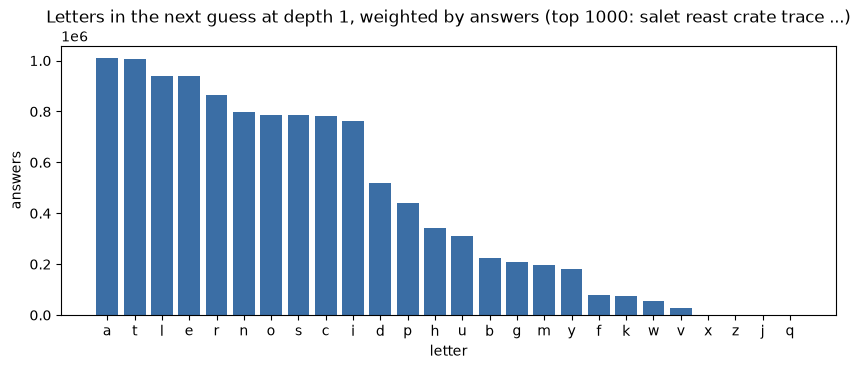

,letter,n_answers,n_positions,n_guesses,share
0,a,1008719,55920,3202,0.435782
1,t,1004653,45168,2132,0.434025
2,l,939013,39776,2192,0.405668
3,e,937957,56723,3369,0.405211
4,r,863825,45603,2581,0.373185
5,n,798353,33837,1866,0.344900
6,o,787597,35650,2314,0.340254
7,s,786650,39753,3045,0.339845
8,c,782094,31620,1450,0.337876
9,i,763743,37425,2213,0.329948


In [6]:
import string

LIVE_ONLY    = False   # <-- True: ignore positions with one answer left (guess = that answer)
COUNT_REPEATS = False  # <-- True: 'abbey' counts b twice; False: each letter once per word

words = at[~at['solved']] if LIVE_ONLY else at
_total = words['n_answers'].sum()

rows = []
for letter in string.ascii_lowercase:
    hits = words['guess'].apply(lambda w: w.count(letter) if COUNT_REPEATS else int(letter in w))
    if not hits.any():
        continue
    rows.append({'letter': letter,
                 'n_answers': int((hits * words['n_answers']).sum()),
                 'n_positions': int((hits > 0).sum()),
                 'n_guesses': words.loc[hits > 0, 'guess'].nunique()})

letter_freq = (pd.DataFrame(rows)
                 .assign(share=lambda d: d['n_answers'] / _total)
                 .sort_values('n_answers', ascending=False)
                 .reset_index(drop=True))

print(f'depth {DEPTH}: {len(letter_freq)} distinct letters over {len(words):,} positions '
      f'({_total:,} answers){" -- live positions only" if LIVE_ONLY else ""}')
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(letter_freq['letter'], letter_freq['n_answers'], color='#3b6ea5')
ax.set_ylabel('answers'); ax.set_xlabel('letter')
ax.set_title(f'Letters in the next guess at depth {DEPTH}, weighted by answers ({LABEL})')
plt.show()
display(letter_freq)

### How many letters are new

A guess's **new letters** are the distinct letters in it that none of the previous guesses
carried — how much fresh alphabet the strategy buys at this position, from 0 (every letter
already played) to 5. At `DEPTH = 0` there is no history, so it is just the opener's
distinct-letter count.

The table is the distribution over the same `words` frame: how many positions land on each
count, and how many answers they cover between them, then those answers split across the
three `guess_kind`s — so a row reads "this much fresh alphabet, bought this often, and this
often by a word that could also have won outright".

The next cell takes the other side of it — the letters that are *not* new, broken down by
what the strategy already knew about each one.

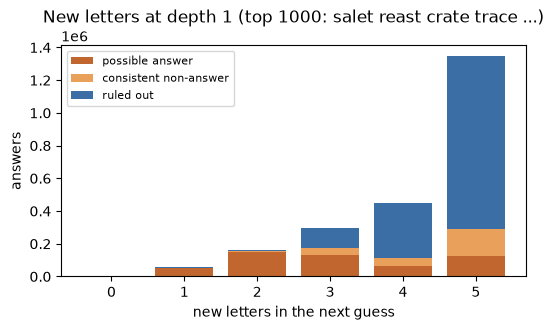

,new_letters,n_positions,n_answers,possible answer,consistent non-answer,ruled out,share
0,0,2583,3734,3717,17,0,0.001613
1,1,23707,55147,54266,356,525,0.023824
2,2,38324,164840,147898,6345,10597,0.071213
3,3,16510,295886,132976,38429,124481,0.127827
4,4,14620,450364,67068,47112,336184,0.194564
5,5,23814,1344764,125617,167362,1051785,0.580958


positions with the fewest new letters:


,opener,guesses,patterns,n_answers,guess,guess_kind,new_letters
0,trois,trois,yyybb,19,rotor,possible answer,0
1,plats,plats,byyby,17,salal,consistent non-answer,0
2,elans,elans,byyby,14,salsa,possible answer,0
3,steal,steal,byyyy,13,latte,possible answer,0
4,neals,neals,bbyyy,12,salsa,possible answer,0
5,rathe,rathe,bbyyy,11,teeth,possible answer,0
6,tepal,tepal,yybyy,10,elate,possible answer,0
7,stein,stein,byyby,9,tenet,possible answer,0
8,leapt,leapt,ybyyb,8,papal,possible answer,0
9,liard,liard,bbyyy,8,radar,possible answer,0


In [7]:
_by_kind = (words.pivot_table(index='new_letters', columns='guess_kind',
                                values='n_answers', aggfunc='sum', fill_value=0)
                   .reindex(columns=list(KINDS), fill_value=0))
new_dist = (words.groupby('new_letters')
                   .agg(n_positions=('guess', 'size'), n_answers=('n_answers', 'sum'))
                   .join(_by_kind)
                   .assign(share=lambda d: d['n_answers'] / d['n_answers'].sum())
                   .reset_index())

fig, ax = plt.subplots(figsize=(6, 3))
bottom = np.zeros(len(new_dist))
for kind, color in zip(KINDS, KIND_COLORS):
    ax.bar(new_dist['new_letters'], new_dist[kind], bottom=bottom, color=color, label=kind)
    bottom = bottom + new_dist[kind].to_numpy()
ax.set_xlabel('new letters in the next guess'); ax.set_ylabel('answers')
ax.set_xticks(range(0, 6)); ax.legend(fontsize=8)
ax.set_title(f'New letters at depth {DEPTH} ({LABEL})')
plt.show()
display(new_dist)

print('positions with the fewest new letters:')
display(words.sort_values(['new_letters', 'n_answers'], ascending=[True, False])
               .head(15)[['opener', 'guesses', 'patterns', 'n_answers', 'guess',
                          'guess_kind', 'new_letters']]
               .reset_index(drop=True))

### Where the repeated letters come from

The same guesses, one TILE at a time: for each of the five tiles of the next guess, what did
the history already say about that letter, and is the tile in the **same place** it said it
about? At `DEPTH = 1` the history is just the opener, so this is "what the second word does
with the first word's letters".

| role | the tile's letter... |
| --- | --- |
| `new` | appeared in no previous guess |
| `green same place` | was green, and this is that square — the confirmed letter, replayed where it belongs |
| `green elsewhere` | was green, and this is a different square |
| `yellow same place` | was yellow *at this very square* — a square the letter is known **not** to occupy |
| `yellow elsewhere` | was yellow, and this is one of the squares it might occupy |
| `grey same place` | was grey at this square, and is played there again |
| `grey elsewhere` | was grey, and is played at a different square |
| `duplicate in guess` | appeared **earlier in this same guess** |

**The rules, exactly.** A letter's known state is the best the history ever gave it: green
if it came back green anywhere, else yellow, else grey (a letter can be several at once —
a doubled letter in one guess can be yellow at one square and grey at another). `same place`
means this tile's index is one where the letter got *that* colour.

`duplicate in guess` takes precedence over everything, so the categories never overlap and
the five roles of a guess always account for the whole word — a second `l` in `rally` is
charged to the doubling, not to the `l` the opener already found. That is the reading of
"the guess just doubles a letter itself"; the per-word count below reports the same thing
without the precedence question.

Counts are **answer-weighted** the same way the letter table is: a position holding 340
answers contributes 340 to each of its five tiles, so `share` is over `5 x` the answers at
this depth and sums to 1. `n_tiles`/`n_positions` are the unweighted counts — how many tiles
and how many distinct positions. A `0` is a result, not a missing row: it says the strategy
never once does that.

**Split three ways by `guess_kind`.** Each role's answer-tiles are divided into the guess
that could win outright (`possible answer`), the one that fits every clue but is not a
mystery word so never could (`consistent non-answer`), and the one that contradicts a clue
(`ruled out`). The second table is the first normalised across the row, so it reads "when
the strategy reuses a letter this way, this is what the word doing it was". The kind is a
property of the POSITION, not the tile, so every tile of a given guess falls on the same
side of it.

Three of the roles can only ever be `ruled out`, and that is forced rather than measured:
a letter classed `grey` came back grey in *every* guess it appeared in, so the answer holds
no copies of it at all (grey means "no further copies"), and `yellow same place` puts a
letter on a square the feedback already said it does not occupy. A word doing either
contradicts a clue by construction, so it can never be a possible answer — nor even a
consistent one.

Uses the same `words` frame as the two cells above, so `LIVE_ONLY` applies here too — with
it off, the positions already down to one answer are included, and those are forced to
replay whatever the single remaining answer contains and are `possible answer` by
construction.

depth 1 (top 1000: salet reast crate trace ...): 119,558 positions, 2,314,735 answers, 11,573,675 tiles played
  possible answer        75,626 positions, 531,542 answers (22.96%)
  consistent non-answer   1,704 positions, 259,621 answers (11.22%)
  ruled out              42,228 positions, 1,523,572 answers (65.82%)


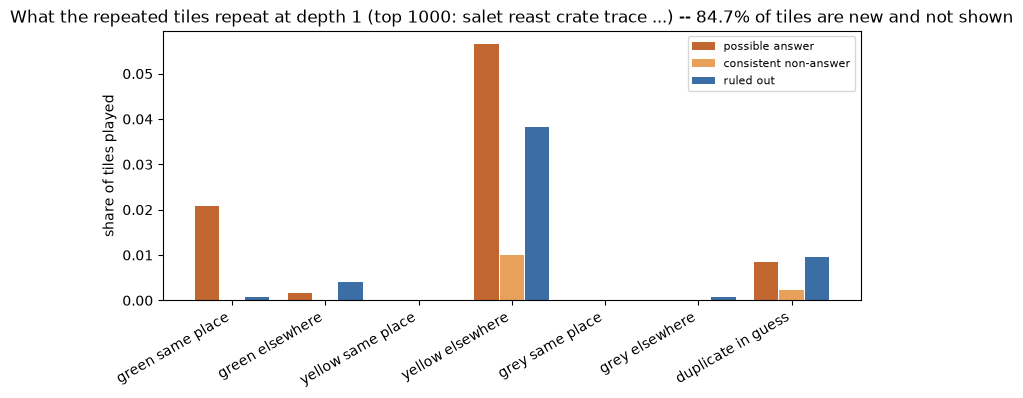

,role,n_tiles,n_positions,n_answer_tiles,possible answer,consistent non-answer,ruled out,share
0,new,327435,116975,9797761,1645347,1153591,6998823,0.846556
1,green same place,96164,60541,248697,240584,729,7384,0.021488
2,green elsewhere,9183,9069,65624,18139,146,47339,0.005670
3,yellow same place,197,195,1849,0,0,1849,0.000160
4,yellow elsewhere,142035,79754,1213466,655250,116536,441680,0.104847
5,grey same place,204,204,1690,0,0,1690,0.000146
6,grey elsewhere,932,928,8741,0,0,8741,0.000755
7,duplicate in guess,21640,20957,235847,98390,27103,110354,0.020378


...the same rows normalised across the kinds:


,possible answer,consistent non-answer,ruled out
role,,,
new,0.167931,0.117740,0.714329
green same place,0.967378,0.002931,0.029691
green elsewhere,0.276408,0.002225,0.721367
yellow same place,0.000000,0.000000,1.000000
yellow elsewhere,0.539982,0.096036,0.363982
grey same place,0.000000,0.000000,1.000000
grey elsewhere,0.000000,0.000000,1.000000
duplicate in guess,0.417177,0.114918,0.467905


the guess itself carries a doubled letter in 20,957 of 119,558 positions, 232,281 of 2,314,735 answers (10.03%)
  possible answer        95,893 answers (41.28%)
  consistent non-answer  26,945 answers (11.60%)
  ruled out              109,443 answers (47.12%)
the biggest position exercising each role, by kind:


,role,guess_kind,opener,guesses,patterns,guess,n_answers,roles
0,green same place,possible answer,crame,crame,bbgbb,slant,61,new | new | green same place | new | new
1,green same place,consistent non-answer,deans,deans,bgbbb,relet,73,new | green same place | new | duplicate in guess | new
2,green same place,ruled out,dries,dries,bgbyb,bract,44,new | green same place | new | new | new
3,green elsewhere,possible answer,drest,drest,bbbgb,slash,46,green elsewhere | new | new | duplicate in guess | new
4,green elsewhere,consistent non-answer,crust,crust,bbbgb,salse,56,green elsewhere | new | new | duplicate in guess | new
5,green elsewhere,ruled out,aloed,aloed,bbbgb,reest,100,new | green elsewhere | duplicate in guess | new | new
6,yellow same place,ruled out,sutor,sutor,ybbbb,salse,53,yellow same place | new | new | duplicate in guess | new
7,yellow elsewhere,possible answer,doest,doest,bbybb,large,310,new | new | new | new | yellow elsewhere
8,yellow elsewhere,consistent non-answer,elint,elint,ybbbb,carse,301,new | new | new | new | yellow elsewhere
9,yellow elsewhere,ruled out,eruct,eruct,yybbb,pilar,182,new | new | new | new | yellow elsewhere


In [8]:
REPEAT_ROLES = ['new', 'green same place', 'green elsewhere',
                'yellow same place', 'yellow elsewhere',
                'grey same place', 'grey elsewhere', 'duplicate in guess']


def tile_roles(guesses, patterns, guess):
    """One role per TILE of `guess`, from REPEAT_ROLES -- see the markdown above.

    `guesses`/`patterns` are the history as lists of strings. A letter's known
    state is the BEST the history ever gave it (green, else yellow, else grey);
    `same place` means this tile's index is one where the letter got that colour.
    A tile whose letter appeared EARLIER IN THIS SAME GUESS is charged to
    `duplicate in guess` whatever the history says, so the roles partition the
    word."""
    seen = {}
    for g, p in zip(guesses, patterns):
        for i, (c, tile) in enumerate(zip(g, p)):
            seen.setdefault(c, {'g': set(), 'y': set(), 'b': set()})[tile].add(i)

    roles = []
    for i, c in enumerate(guess):
        if c in guess[:i]:
            roles.append('duplicate in guess')
            continue
        where = seen.get(c)
        if where is None:
            roles.append('new')
            continue
        for tile, name in (('g', 'green'), ('y', 'yellow'), ('b', 'grey')):
            if where[tile]:
                roles.append(f'{name} same place' if i in where[tile] else f'{name} elsewhere')
                break
    return roles


roles = [tile_roles(h.split(), p.split(), g)
         for h, p, g in zip(words['guesses'], words['patterns'], words['guess'])]
_ans = words['n_answers'].to_numpy()
_kind = words['guess_kind'].to_numpy()

rows = []
for role in REPEAT_ROLES:
    per_pos = np.array([r.count(role) for r in roles])
    ans_tiles = per_pos * _ans
    row = {'role': role,
           'n_tiles': int(per_pos.sum()),
           'n_positions': int((per_pos > 0).sum()),
           'n_answer_tiles': int(ans_tiles.sum())}
    for kind in KINDS:
        row[kind] = int(ans_tiles[_kind == kind].sum())
    rows.append(row)

repeat_dist = (pd.DataFrame(rows)
                 .assign(share=lambda d: d['n_answer_tiles'] / d['n_answer_tiles'].sum()))
kind_share = (repeat_dist.set_index('role')[list(KINDS)]
                         .div(repeat_dist.set_index('role')['n_answer_tiles'], axis=0))

_tiles_played = int(_ans.sum()) * wordle.WORD_LEN
print(f'depth {DEPTH} ({LABEL}): {len(words):,} positions, {_ans.sum():,} answers, '
      f'{_tiles_played:,} tiles played'
      f'{" -- live positions only" if LIVE_ONLY else ""}')
for kind in KINDS:
    n = int(_ans[_kind == kind].sum())
    print(f'  {kind:22s} {int((_kind == kind).sum()):6,} positions, {n:6,} answers '
          f'({n / _ans.sum():6.2%})')

_repeats = repeat_dist[repeat_dist['role'] != 'new']
_new_share = float(repeat_dist.loc[repeat_dist['role'] == 'new', 'share'].iloc[0])
_x = np.arange(len(_repeats))
fig, ax = plt.subplots(figsize=(9, 3.5))
for off, (kind, color) in zip((-0.27, 0, 0.27), zip(KINDS, KIND_COLORS)):
    ax.bar(_x + off, _repeats[kind] / _tiles_played, width=0.26, color=color, label=kind)
ax.set_xticks(_x); ax.set_xticklabels(_repeats['role'], rotation=30, ha='right')
ax.set_ylabel('share of tiles played'); ax.legend(fontsize=8)
ax.set_title(f'What the repeated tiles repeat at depth {DEPTH} ({LABEL})'
             f' -- {_new_share:.1%} of tiles are new and not shown')
plt.show()
display(repeat_dist)
print('...the same rows normalised across the kinds:')
display(kind_share)

_dup = words['guess'].apply(lambda w: len(set(w)) < wordle.WORD_LEN)
_dup_ans = int(words.loc[_dup, 'n_answers'].sum())
print(f'the guess itself carries a doubled letter in {int(_dup.sum()):,} of {len(words):,} '
      f'positions, {_dup_ans:,} of {_ans.sum():,} answers ({_dup_ans / _ans.sum():.2%})')
for kind in KINDS:
    n = int(words.loc[_dup & (words['guess_kind'] == kind), 'n_answers'].sum())
    print(f'  {kind:22s} {n:6,} answers' + (f' ({n / _dup_ans:6.2%})' if _dup_ans else ''))

roled = words.assign(roles=[' | '.join(r) for r in roles])
picks = []
for role in REPEAT_ROLES[1:]:
    hit = roled[roled['roles'].str.contains(role, regex=False)]
    for kind in KINDS:                          # the biggest of each kind
        side = hit[hit['guess_kind'] == kind]
        if side.empty:
            continue
        top = side.sort_values('n_answers', ascending=False).iloc[0]
        picks.append({'role': role, 'guess_kind': kind, 'opener': top['opener'],
                      'guesses': top['guesses'], 'patterns': top['patterns'],
                      'guess': top['guess'], 'n_answers': top['n_answers'],
                      'roles': top['roles']})

print('the biggest position exercising each role, by kind:')
with pd.option_context('display.max_colwidth', 120):
    display(pd.DataFrame(picks))

## What the guess is, by how many options remain

The same three `guess_kind`s, now against the size of the position — how many answers are
still standing when the strategy has to move.

`SCOPES` sets what both this section and the next report on, and it is a LIST of scopes, not
one: `'each+all'` (the default) prints **one table and one chart per ply, then one for
everything pooled**, so a turn-by-turn reading and the overall one arrive together. `'all'`
is the pooled one alone; a list of depths (`[1, 2]`) is exactly those. Ply 1 is the position
after the opener, where the guess being classified is the **second word**.

`OPTION_EDGES`/`OPTION_LABELS` bin the answer count: exact for 1 to 5, where the structure is
sharpest (at 1 there is nothing to decide, at 2 it is a coin flip), then widening. They are
right-closed, so `6-10` is `6 <= n <= 10`.

**Counted by POSITIONS, not answers**, and that is deliberate here: the bucket is *defined*
by the answer count, so weighting inside it by that same count would just re-weight each
bucket by its own variable. `n_answers` is carried beside it for scale.

Each chart is its own figure with its own labelled axis, but they are all drawn over the
SAME buckets — the union across the scopes — so a bucket missing from one ply leaves a gap
there instead of shifting the rest along, and a column sits at the same place in every
chart. The tables drop the rows their scope never reached, since nine blank lines hide the
two that are not. `options_tables` holds the counts frame for each scope by name, and
`options_dist` is the last of them — the pooled one, under the default.

ply 0: 1,000 positions, 2,315,000 answers


,n_positions,n_answers,possible answer,consistent non-answer,ruled out
options,,,,,
251+,1000,2315000,0.265,0.735,0.0


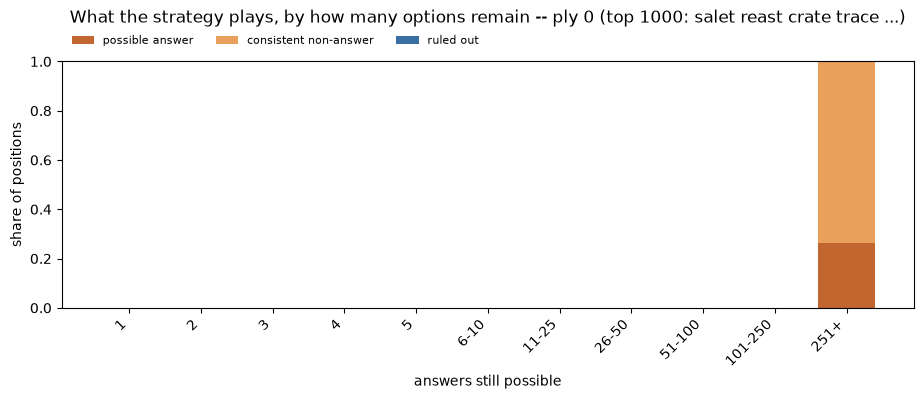

ply 1: 119,558 positions, 2,314,735 answers


,n_positions,n_answers,possible answer,consistent non-answer,ruled out
options,,,,,
1,26144,26144,1.000000,0.000000,0.000000
2,14226,28452,1.000000,0.000000,0.000000
3,9589,28767,1.000000,0.000000,0.000000
4,6859,27436,0.946202,0.000000,0.053798
5,5381,26905,0.855231,0.000186,0.144583
6-10,16175,124762,0.532736,0.000866,0.466399
11-25,19456,323134,0.173263,0.008481,0.818257
26-50,9973,354608,0.100271,0.027675,0.872055
51-100,6524,463990,0.099479,0.047364,0.853158


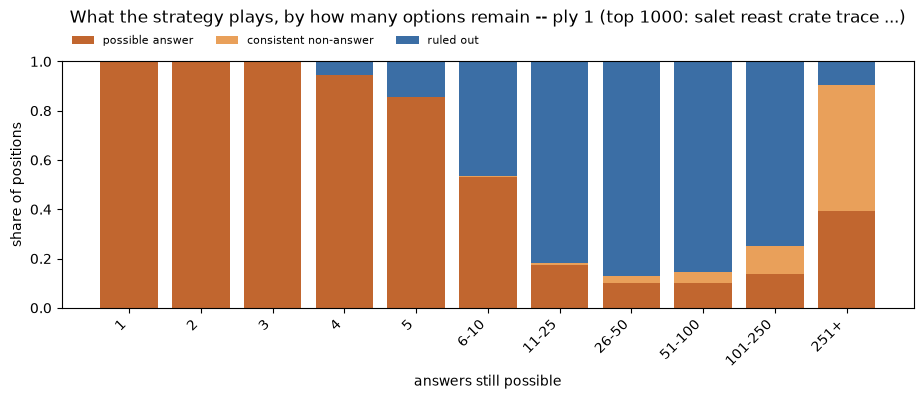

ply 2: 1,168,681 positions, 2,239,109 answers


,n_positions,n_answers,possible answer,consistent non-answer,ruled out
options,,,,,
1,778946,778946,1.000000,0.000000,0.000000
2,185085,370170,1.000000,0.000000,0.000000
3,77584,232752,1.000000,0.000000,0.000000
4,41179,164716,0.912892,0.000000,0.087108
5,25499,127495,0.869681,0.000000,0.130319
6-10,44747,329257,0.747290,0.002101,0.250609
11-25,15000,216153,0.553867,0.040600,0.405533
26-50,641,19620,0.232449,0.081123,0.686427


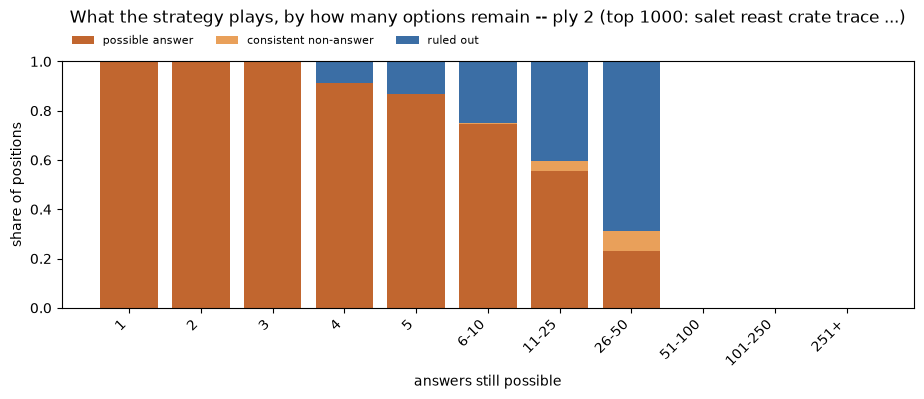

ply 3: 991,978 positions, 1,095,830 answers


,n_positions,n_answers,possible answer,consistent non-answer,ruled out
options,,,,,
1,904225,904225,1.000000,0.000000,0.000000
2,77811,155622,1.000000,0.000000,0.000000
3,6628,19884,1.000000,0.000000,0.000000
4,1824,7296,0.798794,0.000000,0.201206
5,802,4010,0.852868,0.000000,0.147132
6-10,666,4540,0.558559,0.001502,0.439940
11-25,22,253,0.045455,0.000000,0.954545


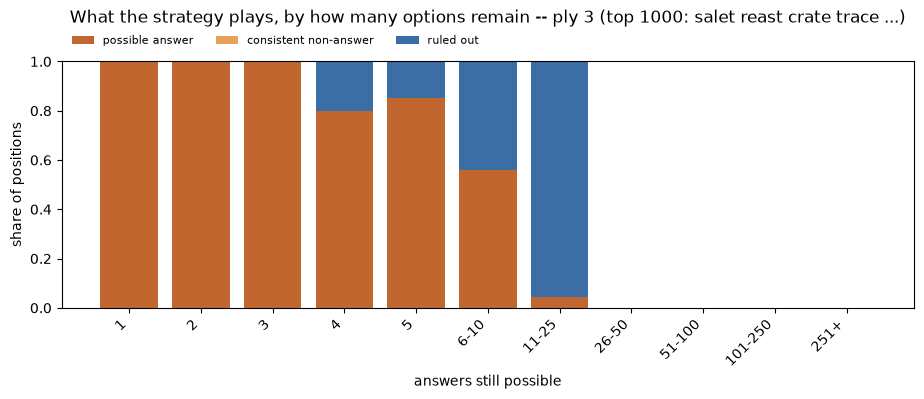

ply 4: 102,314 positions, 104,652 answers


,n_positions,n_answers,possible answer,consistent non-answer,ruled out
options,,,,,
1,100131,100131,1.000000,0.0,0.000000
2,2047,4094,1.000000,0.0,0.000000
3,117,351,0.888889,0.0,0.111111
4,19,76,1.000000,0.0,0.000000


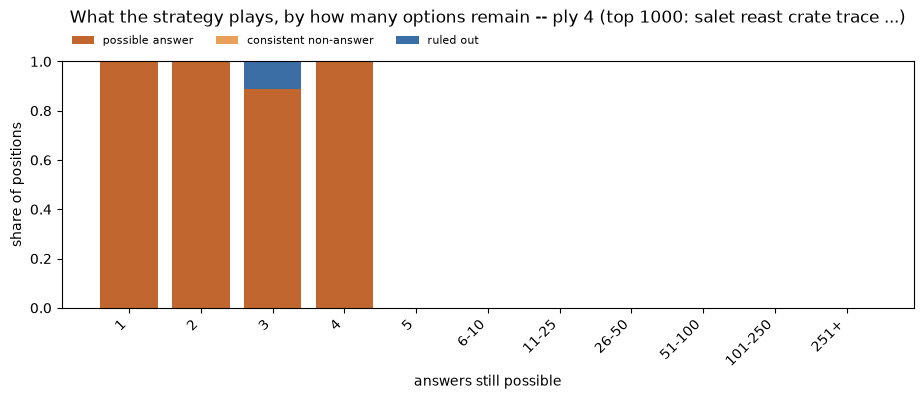

ply 5: 2,351 positions, 2,351 answers


,n_positions,n_answers,possible answer,consistent non-answer,ruled out
options,,,,,
1,2351,2351,1.0,0.0,0.0


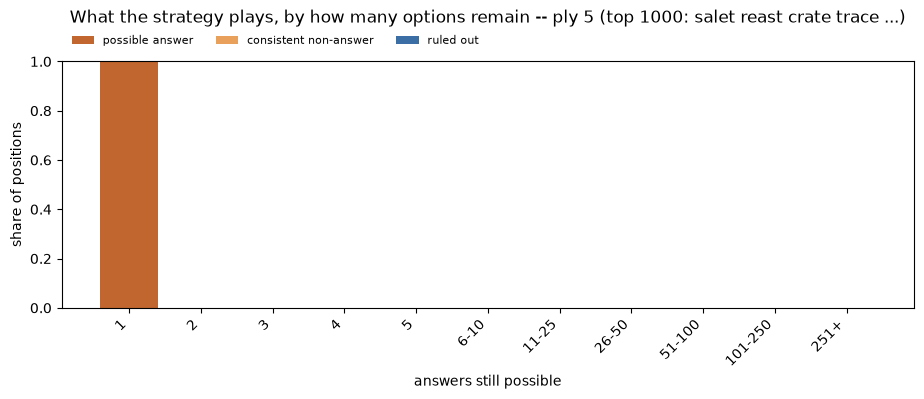

all plies: 2,385,882 positions, 8,071,677 answers


,n_positions,n_answers,possible answer,consistent non-answer,ruled out
options,,,,,
1,1811797,1811797,1.000000,0.000000,0.000000
2,279169,558338,1.000000,0.000000,0.000000
3,93918,281754,0.999862,0.000000,0.000138
4,49881,199524,0.913334,0.000000,0.086666
5,31682,158410,0.866801,0.000032,0.133167
6-10,61588,458559,0.688900,0.001770,0.309330
11-25,34478,539540,0.338767,0.022449,0.638784
26-50,10614,374228,0.108253,0.030903,0.860844
51-100,6524,463990,0.099479,0.047364,0.853158


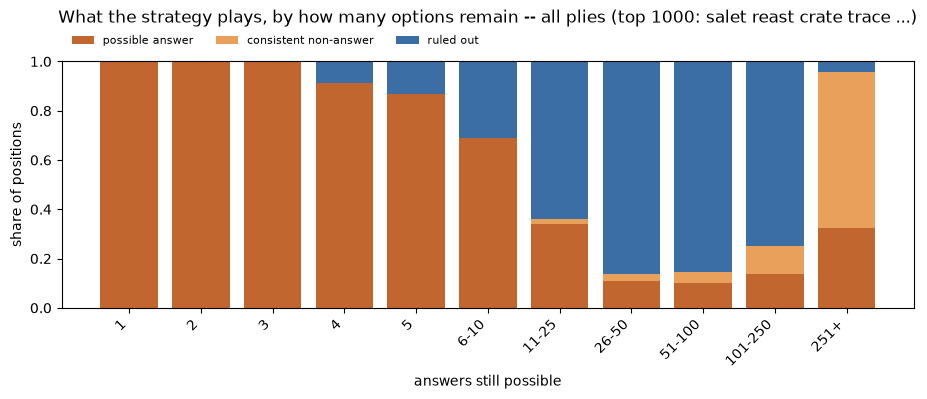

In [9]:
SCOPES = 'each+all'    # <-- 'each+all': a panel per ply then everything pooled;
                       #     'all': pooled only; or a list of depths, e.g. [1, 2]

OPTION_EDGES  = [0, 1, 2, 3, 4, 5, 10, 25, 50, 100, 250, np.inf]
OPTION_LABELS = ['1', '2', '3', '4', '5', '6-10', '11-25', '26-50', '51-100',
                 '101-250', '251+']


def scope_frames(frame, scopes=None):
    """(label, subframe) per requested scope -- the pooled one LAST, so it reads
    as the total. See SCOPES for the three forms."""
    scopes = SCOPES if scopes is None else scopes
    if scopes == 'all':
        return [('all plies', frame)]
    depths = sorted(frame['depth'].unique()) if scopes == 'each+all' else list(scopes)
    out = [(f'ply {d}', frame[frame['depth'] == d]) for d in depths]
    if scopes == 'each+all':
        out.append(('all plies', frame))
    return out


def by_kind(frame, index, values='guess', aggfunc='size'):
    """`frame` cross-tabulated as index x guess_kind, with the row total first.

    `aggfunc='size'` counts POSITIONS; passing values='n_answers' and
    aggfunc='sum' weights by the answers sitting at them. Missing kinds come back
    as 0 columns, so the three are always present and in the same order."""
    table = (frame.pivot_table(index=index, columns='guess_kind', values=values,
                               aggfunc=aggfunc, fill_value=0, observed=False)
                  .reindex(columns=list(KINDS), fill_value=0))
    return table.assign(total=table.sum(axis=1))[['total'] + list(KINDS)]


def kind_rows(tables):
    """Every scope's rows, unioned and put back in the index's own order.

    Each scope is drawn as its OWN chart, so they only line up if they are all
    plotted over the same categories: a bucket missing from one ply has to leave a
    gap there rather than shift the rest along. The order has to come from the
    INDEX, not from the order the scopes happen to introduce rows -- ply 0 holds
    only the widest bucket, so first-seen order opens every axis with it. Sorting
    the union defers to pandas: a binned index by its bin order (never
    alphabetically, where `11+` would land between `1` and `2`), a composition
    lexicographically, a count numerically."""
    return list(pd.concat([t for _, t in tables]).index.unique().sort_values())


def kind_chart(table, rows, denom, title, xlabel, ylabel, fmt=None,
               width=11, height=3.2):
    """One scope's kinds as a stacked share chart, over the shared `rows`.

    `denom` is the column each row is normalised by -- positions or answers,
    whichever that section counts in. `fmt` names a row for the x-axis."""
    fmt = fmt or (lambda r: ' '.join(str(x) for x in r) if isinstance(r, tuple) else str(r))
    share = table[list(KINDS)].div(table[denom], axis=0).reindex(rows).fillna(0)

    fig, ax = plt.subplots(figsize=(width, height))
    bottom = np.zeros(len(rows))
    for kind, color in zip(KINDS, KIND_COLORS):
        ax.bar([fmt(r) for r in rows], share[kind], bottom=bottom, color=color, label=kind)
        bottom = bottom + share[kind].to_numpy()
    ax.set_ylim(0, 1)
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    ax.tick_params(axis='x', labelrotation=45)
    for lab in ax.get_xticklabels():
        lab.set_horizontalalignment('right')
    ax.legend(fontsize=8, ncol=3, loc='lower left', bbox_to_anchor=(0, 1.02), frameon=False)
    ax.set_title(title, pad=28)
    plt.show()


def show_kinds(table, denom):
    """A scope's counts, displayed with the kinds turned into row shares of `denom`.

    Rows the scope never reached are dropped from the DISPLAY -- at ply 4 most of
    them are empty and nine blank lines hide the two that are not. The chart keeps
    every row, so the gap is still visible where it matters."""
    counts = [c for c in table.columns if c not in KINDS]
    shown = table[table[denom] > 0]
    display(pd.concat([shown[counts], shown[list(KINDS)].div(shown[denom], axis=0)], axis=1))


binned = pos.assign(options=pd.cut(pos['n_answers'], bins=OPTION_EDGES,
                                   labels=OPTION_LABELS, right=True))

options_tables = {}
for label, frame in scope_frames(binned):
    table = (by_kind(frame, 'options')
               .rename(columns={'total': 'n_positions'})
               .join(frame.groupby('options', observed=False)['n_answers'].sum()))
    options_tables[label] = table[['n_positions', 'n_answers'] + list(KINDS)]

_rows = kind_rows(list(options_tables.items()))
for label, table in options_tables.items():
    print(f'{label}: {int(table["n_positions"].sum()):,} positions, '
          f'{int(table["n_answers"].sum()):,} answers')
    show_kinds(table, 'n_positions')
    kind_chart(table, _rows, 'n_positions',
               f'What the strategy plays, by how many options remain -- {label} ({LABEL})',
               'answers still possible', 'share of positions')

options_dist = table          # the last scope -- the pooled one, under the default

## ...and by the greens, yellows and greys on the board

The same three kinds against what the board *looks* like — the cumulative tile composition
after the history, which is what a player can actually see. The definition is the repo's,
imported from `tools/tree_states.py` rather than restated, because a different reading is a
different table:

- **`greens`** — POSITIONS pinned green by any guess so far. A position stays pinned; a
  later guess playing another letter there does not unpin it.
- **`yellows`** — COPIES of a letter known present but not yet pinned, SUMMED over letters.
  Two loose B's count 2, and a letter with one copy green and another loose contributes 1.
- **`grays`** — `5 - greens - yellows`.

That reading is the one that makes `greens + yellows` the ANSWER SLOTS ACCOUNTED FOR, hence
`grays` exactly the slots still blank — asserted below at every position. **21 compositions
occur, not 20**: `(4 green, 1 yellow)` is impossible as a single reply but perfectly
reachable cumulatively.

**Weighted by ANSWERS**, matching `tree_states.py`: a position holding `n` answers
contributes `n` cases, so a share reads "this fraction of the answers sitting on a board
that looks like this". `n_positions` is carried beside it, so the node-weighted reading
stays recoverable.

`SCOPES` from the section above drives this one too, so the default draws a chart per ply
and then the pooled one, all over the same set of boards. **19 of the 21 compositions can occur at ply 1**:
that board is a single reply, and `(4 green, 1 yellow)` is unreachable as one while
`(5 green, 0 yellow)` ended the game a ply earlier. Both turn up deeper, cumulatively.

> **In the pooled chart the denominator is not the 2,315.** An answer sits in a position at
> every level it survives, so pooling counts it once per surviving turn and those cells are
> answer-weighted BOARD STATES. The per-ply panels are the reading where each answer appears
> at most once.

ply 0: 1 compositions over 1,000 positions, 2,315,000 answer-positions


,,,n_positions,n_answers,possible answer,consistent non-answer,ruled out
greens,yellows,grays,,,,,
0,0,5,1000,2315000,0.265,0.735,0.0


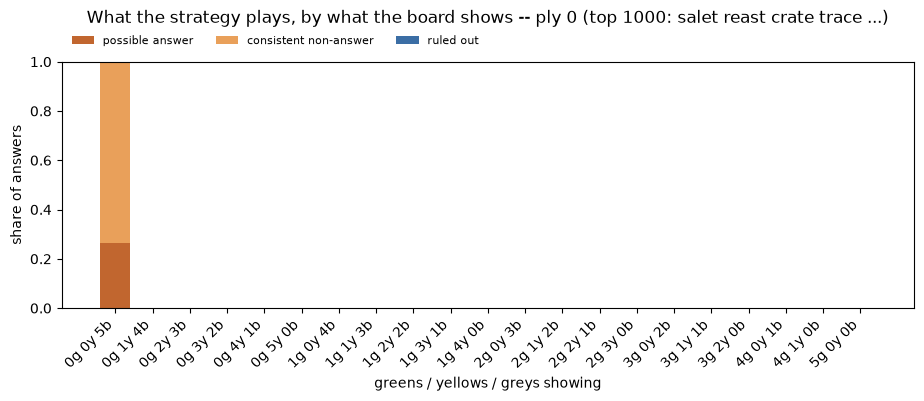

ply 1: 19 compositions over 119,558 positions, 2,314,735 answer-positions


n_positions  n_answers  possible answer  \
greens yellows grays                                            
0      0       5             1000     293225         0.429237   
       1       4             5000     609101         0.151591   
       2       3             9997     444735         0.173180   
       3       2             9666     122440         0.396635   
       4       1             3527      11613         0.783174   
       5       0              181        196         1.000000   
1      0       4             4995     260405         0.018298   
       1       3            19194     292791         0.153181   
       2       2            22092      99669         0.549348   
       3       1             5906      10573         0.868722   
       4       0              228        240         1.000000   
2      0       3             9004      94679         0.169077   
       1       2            15597      45967         0.635978   
       2       1             4128       5905         0.921592   
       3       0              104        104         1.000000   
3      0       2             5669      18427         0.531340   
       1       1             1869       2543         0.906410   
       2       0              110        110         1.000000   
4      0       1             1291       2012         0.836978   

                      consistent non-answer  ruled out  
greens yellows grays                                    
0      0       5                   0.570763   0.000000  
       1       4                   0.111601   0.736809  
       2       3                   0.049414   0.777407  
       3       2                   0.011696   0.591669  
       4       1                   0.000000   0.216826  
       5       0                   0.000000   0.000000  
1      0       4                   0.002162   0.979540  
       1       3                   0.001066   0.845753  
       2       2                   0.000000   0.450652  
       3       1                   0.000000   0.131278  
       4       0                   0.000000   0.000000  
2      0       3                   0.000000   0.830923  
       1       2                   0.000000   0.364022  
       2       1                   0.000000   0.078408  
       3       0                   0.000000   0.000000  
3      0       2                   0.000000   0.468660  
       1       1                   0.000000   0.093590  
       2       0                   0.000000   0.000000  
4      0       1                   0.000000   0.163022

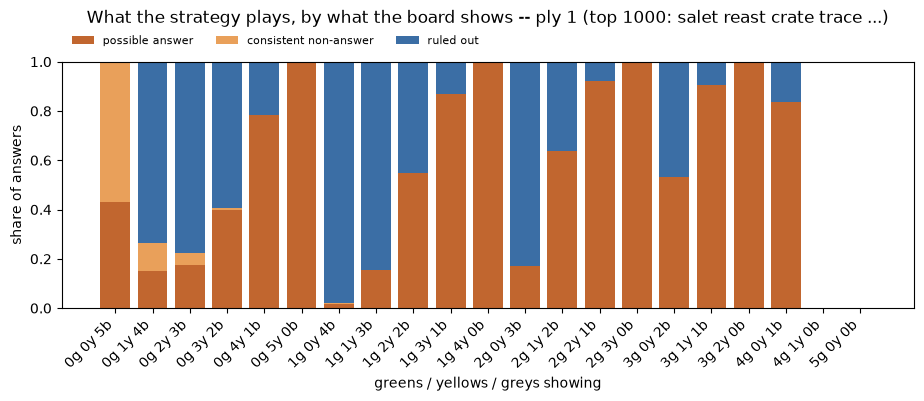

ply 2: 21 compositions over 1,168,681 positions, 2,239,109 answer-positions


n_positions  n_answers  possible answer  \
greens yellows grays                                            
0      0       5             1000      17716         0.741194   
       1       4             9819      83213         0.780852   
       2       3            38907     209673         0.783682   
       3       2            75507     208310         0.907057   
       4       1            55919      84030         0.968404   
       5       0            10484      10759         1.000000   
1      0       4            10583      57124         0.710419   
       1       3            77429     250059         0.828616   
       2       2           181145     341090         0.915670   
       3       1           133573     169699         0.978362   
       4       0            24151      24434         1.000000   
2      0       3            40120     100841         0.829127   
       1       2           150885     244590         0.917789   
       2       1           128207     153285         0.983390   
       3       0            24098      24178         1.000000   
3      0       2            64477      97102         0.926696   
       1       1            72117      84461         0.980405   
       2       0            16312      16318         1.000000   
4      0       1            45333      53612         0.981161   
       1       0             6861       6861         1.000000   
5      0       0             1754       1754         1.000000   

                      consistent non-answer  ruled out  
greens yellows grays                                    
0      0       5                   0.165049   0.093757  
       1       4                   0.045798   0.173350  
       2       3                   0.015100   0.201218  
       3       2                   0.001075   0.091868  
       4       1                   0.000000   0.031596  
       5       0                   0.000000   0.000000  
1      0       4                   0.029970   0.259611  
       1       3                   0.002056   0.169328  
       2       2                   0.000111   0.084218  
       3       1                   0.000000   0.021638  
       4       0                   0.000000   0.000000  
2      0       3                   0.000159   0.170714  
       1       2                   0.000000   0.082211  
       2       1                   0.000000   0.016610  
       3       0                   0.000000   0.000000  
3      0       2                   0.000000   0.073304  
       1       1                   0.000000   0.019595  
       2       0                   0.000000   0.000000  
4      0       1                   0.000000   0.018839  
       1       0                   0.000000   0.000000  
5      0       0                   0.000000   0.000000

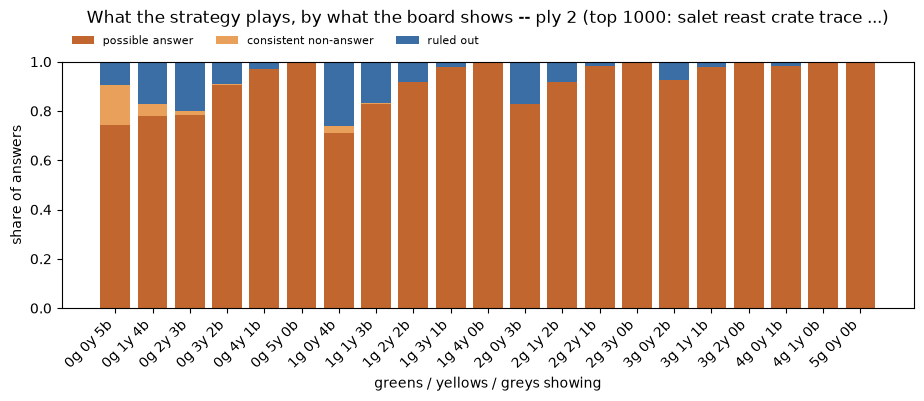

ply 3: 21 compositions over 991,978 positions, 1,095,830 answer-positions


n_positions  n_answers  possible answer  \
greens yellows grays                                            
0      0       5              195        305         1.000000   
       1       4             3391       4135         1.000000   
       2       3            18711      22276         0.994972   
       3       2            37419      41350         0.998065   
       4       1            20965      21919         1.000000   
       5       0             3099       3108         1.000000   
1      0       4             6085       8227         0.999028   
       1       3            47301      54893         0.994845   
       2       2            91343     102207         0.989688   
       3       1            53189      55831         0.999857   
       4       0             9087       9088         1.000000   
2      0       3            48230      57417         0.997091   
       1       2           120438     132865         0.990916   
       2       1            73085      75692         0.999247   
       3       0             9900       9900         1.000000   
3      0       2           144363     164624         0.996319   
       1       1            78110      81419         0.999853   
       2       0            12770      12770         1.000000   
4      0       1           211115     234622         0.996829   
       1       0             2686       2686         1.000000   
5      0       0              496        496         1.000000   

                      consistent non-answer  ruled out  
greens yellows grays                                    
0      0       5                   0.000000   0.000000  
       1       4                   0.000000   0.000000  
       2       3                   0.000000   0.005028  
       3       2                   0.000000   0.001935  
       4       1                   0.000000   0.000000  
       5       0                   0.000000   0.000000  
1      0       4                   0.000000   0.000972  
       1       3                   0.000000   0.005155  
       2       2                   0.000078   0.010234  
       3       1                   0.000000   0.000143  
       4       0                   0.000000   0.000000  
2      0       3                   0.000000   0.002909  
       1       2                   0.000000   0.009084  
       2       1                   0.000000   0.000753  
       3       0                   0.000000   0.000000  
3      0       2                   0.000000   0.003681  
       1       1                   0.000000   0.000147  
       2       0                   0.000000   0.000000  
4      0       1                   0.000000   0.003171  
       1       0                   0.000000   0.000000  
5      0       0                   0.000000   0.000000

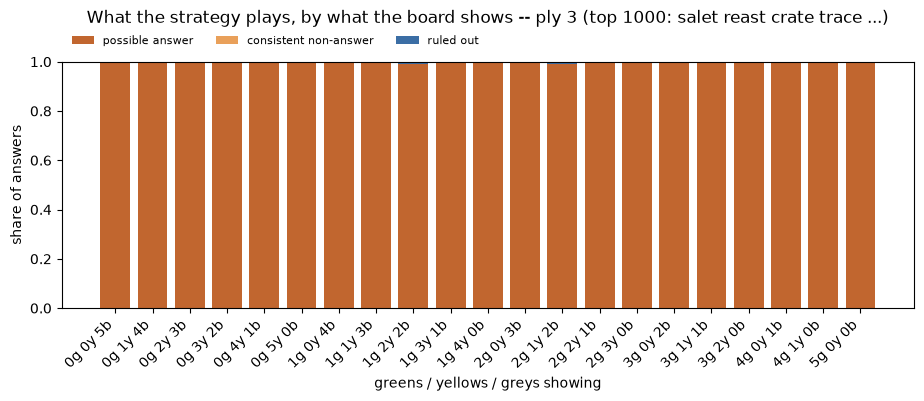

ply 4: 20 compositions over 102,314 positions, 104,652 answer-positions


n_positions  n_answers  possible answer  \
greens yellows grays                                            
0      1       4                5          5         1.000000   
       2       3              121        121         1.000000   
       3       2              263        271         0.988930   
       4       1              159        162         1.000000   
       5       0               18         18         1.000000   
1      0       4               37         37         1.000000   
       1       3              568        579         1.000000   
       2       2             1391       1466         1.000000   
       3       1              886        895         1.000000   
       4       0              130        130         1.000000   
2      0       3             3840       3909         1.000000   
       1       2             4451       4570         0.999344   
       2       1             2051       2058         1.000000   
       3       0              234        234         1.000000   
3      0       2            22561      23404         0.998590   
       1       1             4550       4572         1.000000   
       2       0              487        487         1.000000   
4      0       1            59949      61121         1.000000   
       1       0              405        405         1.000000   
5      0       0              208        208         1.000000   

                      consistent non-answer  ruled out  
greens yellows grays                                    
0      1       4                        0.0   0.000000  
       2       3                        0.0   0.000000  
       3       2                        0.0   0.011070  
       4       1                        0.0   0.000000  
       5       0                        0.0   0.000000  
1      0       4                        0.0   0.000000  
       1       3                        0.0   0.000000  
       2       2                        0.0   0.000000  
       3       1                        0.0   0.000000  
       4       0                        0.0   0.000000  
2      0       3                        0.0   0.000000  
       1       2                        0.0   0.000656  
       2       1                        0.0   0.000000  
       3       0                        0.0   0.000000  
3      0       2                        0.0   0.001410  
       1       1                        0.0   0.000000  
       2       0                        0.0   0.000000  
4      0       1                        0.0   0.000000  
       1       0                        0.0   0.000000  
5      0       0                        0.0   0.000000

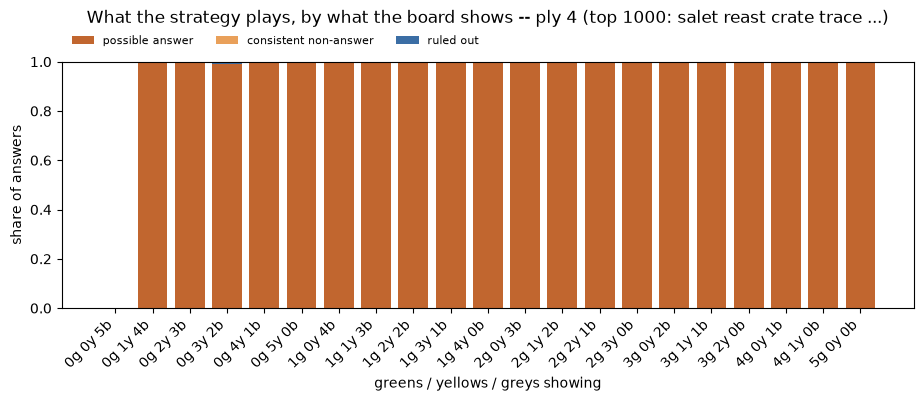

ply 5: 9 compositions over 2,351 positions, 2,351 answer-positions


n_positions  n_answers  possible answer  \
greens yellows grays                                            
0      3       2                1          1              1.0   
       4       1                2          2              1.0   
1      2       2                1          1              1.0   
2      0       3               56         56              1.0   
       1       2               14         14              1.0   
       2       1                4          4              1.0   
3      0       2              635        635              1.0   
       1       1               35         35              1.0   
4      0       1             1603       1603              1.0   

                      consistent non-answer  ruled out  
greens yellows grays                                    
0      3       2                        0.0        0.0  
       4       1                        0.0        0.0  
1      2       2                        0.0        0.0  
2      0       3                        0.0        0.0  
       1       2                        0.0        0.0  
       2       1                        0.0        0.0  
3      0       2                        0.0        0.0  
       1       1                        0.0        0.0  
4      0       1                        0.0        0.0

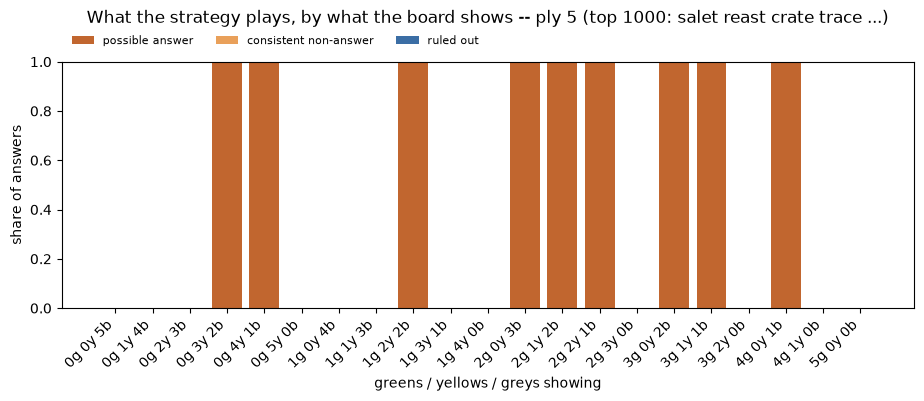

all plies: 21 compositions over 2,385,882 positions, 8,071,677 answer-positions


n_positions  n_answers  possible answer  \
greens yellows grays                                            
0      0       5             3195    2626246         0.286635   
       1       4            18215     696454         0.231819   
       2       3            67736     676805         0.389508   
       3       2           122856     372372         0.749390   
       4       1            80572     117726         0.956059   
       5       0            13782      14081         1.000000   
1      0       4            21700     325793         0.164531   
       1       3           144492     598322         0.513506   
       2       2           295972     544433         0.862731   
       3       1           193554     236998         0.978616   
       4       0            33596      33892         1.000000   
2      0       3           101250     256902         0.626048   
       1       2           291385     428006         0.911097   
       2       1           207475     236944         0.987060   
       3       0            34336      34416         1.000000   
3      0       2           237705     304192         0.946110   
       1       1           156681     173030         0.988990   
       2       0            29679      29685         1.000000   
4      0       1           319291     352970         0.994101   
       1       0             9952       9952         1.000000   
5      0       0             2458       2458         1.000000   

                      consistent non-answer  ruled out  
greens yellows grays                                    
0      0       5                   0.712733   0.000632  
       1       4                   0.103075   0.665106  
       2       3                   0.037148   0.573344  
       3       2                   0.004447   0.246162  
       4       1                   0.000000   0.043941  
       5       0                   0.000000   0.000000  
1      0       4                   0.006983   0.828486  
       1       3                   0.001381   0.485113  
       2       2                   0.000084   0.137185  
       3       1                   0.000000   0.021384  
       4       0                   0.000000   0.000000  
2      0       3                   0.000062   0.373890  
       1       2                   0.000000   0.088903  
       2       1                   0.000000   0.012940  
       3       0                   0.000000   0.000000  
3      0       2                   0.000000   0.053890  
       1       1                   0.000000   0.011010  
       2       0                   0.000000   0.000000  
4      0       1                   0.000000   0.005899  
       1       0                   0.000000   0.000000  
5      0       0                   0.000000   0.000000

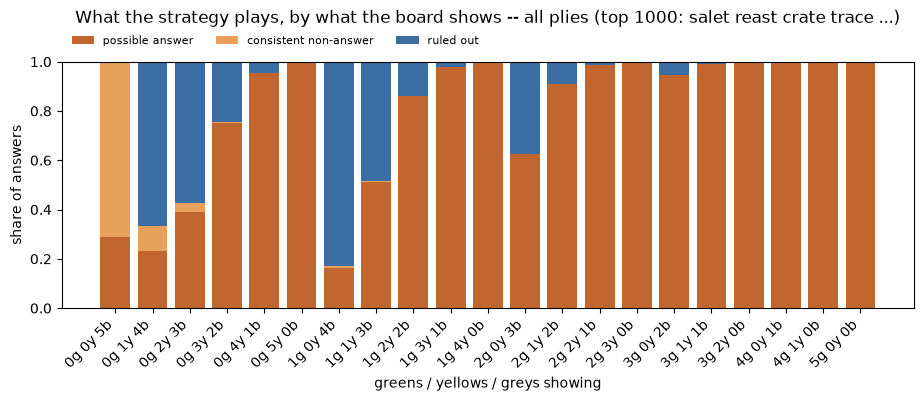

the compositions where the pooled strategy most often plays a probe:


n_positions  n_answers  probe_share
greens yellows grays                                     
1      0       4            21700     325793     0.828486
0      1       4            18215     696454     0.665106
       2       3            67736     676805     0.573344
1      1       3           144492     598322     0.485113
2      0       3           101250     256902     0.373890
0      3       2           122856     372372     0.246162
1      2       2           295972     544433     0.137185
2      1       2           291385     428006     0.088903
3      0       2           237705     304192     0.053890
0      4       1            80572     117726     0.043941

In [10]:
def board_state(guesses, patterns, guess):
    """(greens, yellows, grays, greens kept, yellows kept) at one position.

    The first three are the composition -- tree_states' definition, imported. The
    last two are how much of it `guess` replays, and ride along because they need
    the same walk; the section two below is what reads them. A green is kept when
    the guess plays that letter on that very square; a yellow, a known copy not yet
    placed, when the guess supplies a copy of the letter anywhere -- per letter
    `min(copies not spent on a green it kept, copies still unplaced)`."""
    state = tree_states.EMPTY
    for g, p in zip(guesses, patterns):
        state = tree_states.apply_row(state, g, p)
    pinned, known = state
    greens, yellows = tree_states.greens_yellows(state)

    greens_kept = sum(1 for i, c in enumerate(pinned)
                      if c >= 0 and guess[i] == chr(97 + c))
    yellows_kept = 0
    for c, n in known:
        letter = chr(97 + c)
        placed = sum(1 for x in pinned if x == c)
        kept_here = sum(1 for i, x in enumerate(pinned)
                        if x == c and guess[i] == letter)
        yellows_kept += max(0, min(guess.count(letter) - kept_here, n - placed))
    return greens, yellows, wordle.WORD_LEN - greens - yellows, greens_kept, yellows_kept


# Computed once over every position, then split by scope -- the walk is the
# expensive half and does not depend on which ply a position sits at.
_state = [board_state(h.split(), p.split(), g)
          for h, p, g in zip(pos['guesses'], pos['patterns'], pos['guess'])]
if any(s[2] < 0 for s in _state):
    raise ValueError('greens + yellows exceeded the word length: the slots accounted for '
                     'cannot outnumber the squares')

board = pos.assign(greens=[s[0] for s in _state],
                   yellows=[s[1] for s in _state],
                   grays=[s[2] for s in _state],
                   greens_kept=[s[3] for s in _state],
                   yellows_kept=[s[4] for s in _state])

# A word consistent with the clues has every green in place and holds at least as
# many copies of a known letter as the board proves, so only a ruled-out guess can
# drop either. Free cross-check: tree_states' cumulative state against the
# consistency test positions() ran from the feedback function.
_consistent = board['guess_kind'] != KIND_RULED_OUT
if not (board.loc[_consistent, 'greens_kept'].equals(board.loc[_consistent, 'greens'])
        and board.loc[_consistent, 'yellows_kept'].equals(board.loc[_consistent, 'yellows'])):
    raise ValueError('a guess consistent with the clues dropped a green or a yellow: '
                     'the cumulative state and the consistency test disagree')

# ...AND IN HARD MODE THAT HOLDS AT *EVERY* POSITION, ruled-out guesses included.
# Hard mode's rule IS these two columns: a green replayed on its own square is
# `greens_kept == greens`, and `guess.count(c) >= known[c]` for every proved
# letter is exactly `yellows_kept == yellows` once the greens are kept.  So the
# check needs no second implementation of the rule -- `checktrees.py` accumulates
# the same state and this frame already carries it.
#
# It is also the one thing that would CATCH a mislabelled run: HARD_MODE set
# while `WORDLE_TREES` or a stale kernel points at the normal sweep reads as an
# ordinary notebook until this fires.
if HARD_MODE:
    _legal = ((board['greens_kept'] == board['greens'])
              & (board['yellows_kept'] == board['yellows']))
    if not _legal.all():
        _bad = board[~_legal]
        raise ValueError(
            f'HARD_MODE is on but {len(_bad):,} of {len(board):,} positions play a guess '
            f'that drops a revealed hint, which hard mode forbids -- e.g. '
            f'{_bad.iloc[0]["opener"]}: {_bad.iloc[0]["guess"]!r} after '
            f'{_bad.iloc[0]["guesses"]!r} / {_bad.iloc[0]["patterns"]!r}.  These are not '
            f'hard-mode trees: check paths.TREES and WORDLE_TREES.')
    print(f'hard mode: all {len(board):,} positions replay every revealed green and '
          f'yellow, so every guess in these trees is hard-mode legal')

comp_tables = {}
for label, frame in scope_frames(board):
    table = (by_kind(frame, ['greens', 'yellows', 'grays'],
                     values='n_answers', aggfunc='sum')
               .rename(columns={'total': 'n_answers'})
               .join(frame.groupby(['greens', 'yellows', 'grays']).size()
                          .rename('n_positions')))
    comp_tables[label] = table[['n_positions', 'n_answers'] + list(KINDS)]

_board = lambda r: f'{r[0]}g {r[1]}y {r[2]}b'
_rows = kind_rows(list(comp_tables.items()))
for label, table in comp_tables.items():
    print(f'{label}: {len(table)} compositions over '
          f'{int(table["n_positions"].sum()):,} positions, '
          f'{int(table["n_answers"].sum()):,} answer-positions')
    show_kinds(table, 'n_answers')
    kind_chart(table, _rows, 'n_answers',
               f'What the strategy plays, by what the board shows -- {label} ({LABEL})',
               'greens / yellows / greys showing', 'share of answers', fmt=_board)

comp_dist = table             # the last scope -- the pooled one, under the default
print('the compositions where the pooled strategy most often plays a probe:')
display(comp_dist.assign(probe_share=comp_dist[KIND_RULED_OUT] / comp_dist['n_answers'])
                 .sort_values('probe_share', ascending=False)
                 .head(10)[['n_positions', 'n_answers', 'probe_share']])

## When it plays a ruled-out word, how much new alphabet does it buy?

A `ruled out` guess is spent entirely on information — it cannot win, by construction — so the
natural question is what it buys: how many of its five letters the strategy has never played
before. Same `SCOPES` as the two sections above, so it is a ply at a time and then pooled.

The chart is **one bar per greens/yellows/greys combination**, the same x-axis as the section
above, stacked by the new-letter count — so it reads "on a board that looks like this, when
the strategy spends a turn on a word that cannot win, this is how much fresh alphabet it
takes". `MIX_KIND` picks which kind to break down; it is `ruled out` because that is the
turn being paid for, but any of `KINDS` works.

Ahead of it, the same distribution with the board forgotten: the new-letter count against all
three kinds, so the ruled-out column can be read against what a `possible answer` buys.

Counted by **POSITIONS** in both: the unit is the choice the strategy made, not the answers
riding on it. `n_answers` is carried in the counts table for scale, and `new_letters` comes
off `pos` itself — it is a property of (history, guess) like `guess_kind`, so `positions()`
computes it once and every section reads the same column.

ply 0: possible answer 5.00 new letters on average, consistent non-answer 5.00 new letters on average


,n_positions,n_answers,possible answer,consistent non-answer,ruled out,possible answer (share of kind),consistent non-answer (share of kind)
new_letters,,,,,,,
5,1000,2315000,265,735,0,1.0,1.0


  no ruled out guess anywhere at ply 0
ply 1: possible answer 1.80 new letters on average, consistent non-answer 3.78 new letters on average, ruled out 4.38 new letters on average


,n_positions,n_answers,possible answer,consistent non-answer,ruled out,possible answer (share of kind),consistent non-answer (share of kind),ruled out (share of kind)
new_letters,,,,,,,,
0,2583,3734,2582,1,0,0.034142,0.000587,0.000000
1,23707,55147,23665,12,30,0.312921,0.007042,0.000710
2,38324,164840,37548,166,610,0.496496,0.097418,0.014445
3,16510,295886,10657,572,5281,0.140917,0.335681,0.125059
4,14620,450364,740,388,13492,0.009785,0.227700,0.319504
5,23814,1344764,434,565,22815,0.005739,0.331573,0.540281


  the 42,228 ruled out guesses, by board and new-letter count:


n_positions  mean_new    0         1         2  \
greens yellows grays                                                   
0      1       4             3681  4.991307  0.0  0.000000  0.000000   
       2       3             6831  4.231445  0.0  0.000000  0.000878   
       3       2             3525  3.516312  0.0  0.004539  0.091915   
       4       1              279  3.146953  0.0  0.025090  0.250896   
1      0       4             4581  4.926654  0.0  0.000000  0.000218   
       1       3            11076  4.463705  0.0  0.000000  0.005327   
       2       2             4041  4.031428  0.0  0.001732  0.022024   
       3       1              245  3.710204  0.0  0.000000  0.053061   
2      0       3             4690  4.633475  0.0  0.000000  0.002345   
       1       2             1985  4.188917  0.0  0.000000  0.011083   
       2       1               96  3.812500  0.0  0.000000  0.052083   
3      0       2             1072  4.179104  0.0  0.000000  0.007463   
       1       1               53  3.905660  0.0  0.000000  0.000000   
4      0       1               73  3.794521  0.0  0.000000  0.027397   

                             3         4         5  
greens yellows grays                                
0      1       4      0.000272  0.008150  0.991578  
       2       3      0.143171  0.479578  0.376372  
       3       2      0.400851  0.388085  0.114610  
       4       1      0.412186  0.175627  0.136201  
1      0       4      0.007422  0.057848  0.934512  
       1       3      0.085681  0.348953  0.560040  
       2       2      0.223954  0.447661  0.304628  
       3       1      0.346939  0.436735  0.163265  
2      0       3      0.053518  0.252452  0.691684  
       1       2      0.159194  0.459446  0.370277  
       2       1      0.312500  0.406250  0.229167  
3      0       2      0.156716  0.485075  0.350746  
       1       1      0.264151  0.566038  0.169811  
4      0       1      0.301370  0.520548  0.150685

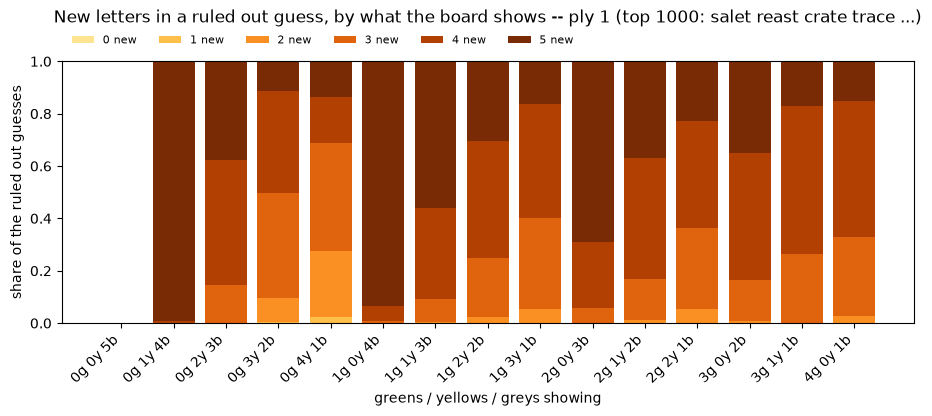

ply 2: possible answer 1.38 new letters on average, consistent non-answer 3.47 new letters on average, ruled out 3.69 new letters on average


,n_positions,n_answers,possible answer,consistent non-answer,ruled out,possible answer (share of kind),consistent non-answer (share of kind),ruled out (share of kind)
new_letters,,,,,,,,
0,155229,167813,155228,1,0,0.135774,0.001325,0.000000
1,508884,706969,508786,14,84,0.445023,0.018543,0.003408
2,384086,781888,382435,99,1552,0.334507,0.131126,0.062969
3,96840,363702,88054,280,8506,0.077019,0.370861,0.345113
4,18772,155423,8239,237,10296,0.007206,0.313907,0.417738
5,4870,63314,537,124,4209,0.000470,0.164238,0.170771


  the 24,647 ruled out guesses, by board and new-letter count:


n_positions  mean_new    0         1         2  \
greens yellows grays                                                   
0      0       5              108  3.935185  0.0  0.000000  0.000000   
       1       4             1089  4.234160  0.0  0.000000  0.011938   
       2       3             3283  3.857143  0.0  0.001523  0.038989   
       3       2             2087  3.435553  0.0  0.004792  0.104935   
       4       1              485  3.169072  0.0  0.020619  0.179381   
1      0       4             1196  4.108696  0.0  0.000000  0.018395   
       1       3             4416  3.823596  0.0  0.000226  0.063859   
       2       2             3949  3.581919  0.0  0.007090  0.057736   
       3       1              794  3.341310  0.0  0.012594  0.112091   
2      0       3             1926  3.793354  0.0  0.000519  0.047767   
       1       2             2996  3.561415  0.0  0.003338  0.066756   
       2       1              560  3.376786  0.0  0.005357  0.073214   
3      0       2             1131  3.488948  0.0  0.002653  0.105217   
       1       1              385  3.303896  0.0  0.000000  0.067532   
4      0       1              242  3.500000  0.0  0.012397  0.024793   

                             3         4         5  
greens yellows grays                                
0      0       5      0.064815  0.935185  0.000000  
       1       4      0.168044  0.393939  0.426079  
       2       3      0.272007  0.475784  0.211697  
       3       2      0.442741  0.344993  0.102540  
       4       1      0.484536  0.241237  0.074227  
1      0       4      0.197324  0.441472  0.342809  
       1       3      0.283062  0.417799  0.235054  
       2       2      0.386174  0.444163  0.104837  
       3       1      0.458438  0.355164  0.061713  
2      0       3      0.314123  0.433022  0.204569  
       1       2      0.401202  0.422563  0.106142  
       2       1      0.510714  0.360714  0.050000  
3      0       2      0.389920  0.404951  0.097259  
       1       1      0.592208  0.309091  0.031169  
4      0       1      0.524793  0.326446  0.111570

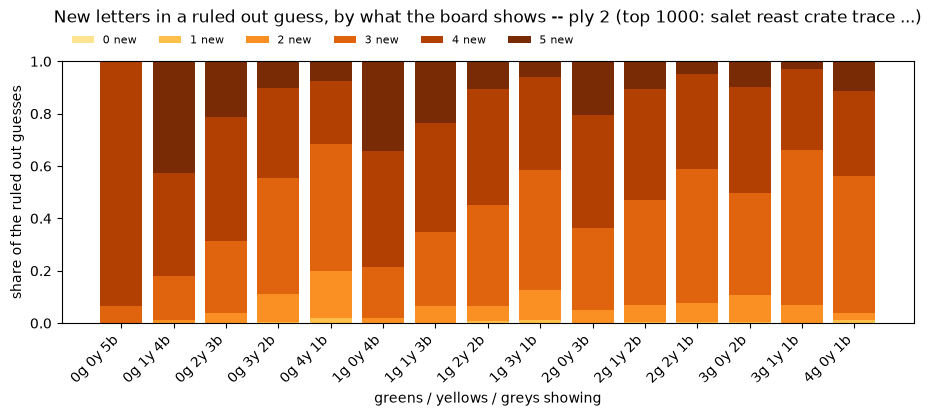

ply 3: possible answer 1.32 new letters on average, consistent non-answer 2.00 new letters on average, ruled out 3.53 new letters on average


,n_positions,n_answers,possible answer,consistent non-answer,ruled out,possible answer (share of kind),consistent non-answer (share of kind),ruled out (share of kind)
new_letters,,,,,,,,
0,115935,120622,115935,0,0,0.116967,0.0,0.000000
1,506558,551751,506558,0,0,0.511067,0.0,0.000000
2,307828,348866,307792,1,35,0.310532,1.0,0.043805
3,59283,69879,58891,0,392,0.059415,0.0,0.490613
4,2288,4165,2000,0,288,0.002018,0.0,0.360451
5,86,547,2,0,84,0.000002,0.0,0.105131


  the 799 ruled out guesses, by board and new-letter count:


n_positions  mean_new    0    1         2         3  \
greens yellows grays                                                        
0      2       3               13  3.769231  0.0  0.0  0.000000  0.384615   
       3       2               14  3.214286  0.0  0.0  0.000000  0.857143   
1      0       4                1  4.000000  0.0  0.0  0.000000  0.000000   
       1       3               48  3.812500  0.0  0.0  0.020833  0.416667   
       2       2              175  3.428571  0.0  0.0  0.028571  0.628571   
       3       1                2  5.000000  0.0  0.0  0.000000  0.000000   
2      0       3               23  3.608696  0.0  0.0  0.000000  0.565217   
       1       2              203  3.699507  0.0  0.0  0.054187  0.290640   
       2       1               14  2.785714  0.0  0.0  0.285714  0.642857   
3      0       2              117  3.427350  0.0  0.0  0.076923  0.564103   
       1       1                3  3.666667  0.0  0.0  0.000000  0.333333   
4      0       1              186  3.451613  0.0  0.0  0.026882  0.521505   

                             4         5  
greens yellows grays                      
0      2       3      0.461538  0.153846  
       3       2      0.071429  0.071429  
1      0       4      1.000000  0.000000  
       1       3      0.291667  0.270833  
       2       2      0.228571  0.114286  
       3       1      0.000000  1.000000  
2      0       3      0.260870  0.173913  
       1       2      0.556650  0.098522  
       2       1      0.071429  0.000000  
3      0       2      0.213675  0.145299  
       1       1      0.666667  0.000000  
4      0       1      0.424731  0.026882

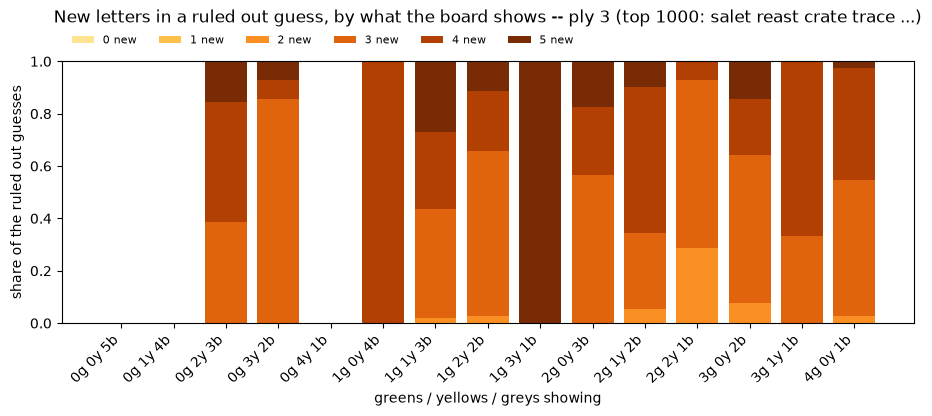

ply 4: possible answer 1.10 new letters on average, ruled out 2.69 new letters on average


,n_positions,n_answers,possible answer,consistent non-answer,ruled out,possible answer (share of kind),ruled out (share of kind)
new_letters,,,,,,,
0,12956,13185,12956,0,0,0.126646,0.000000
1,67960,69120,67960,0,0,0.664314,0.000000
2,20069,20981,20065,0,4,0.196137,0.307692
3,1323,1360,1314,0,9,0.012844,0.692308
4,6,6,6,0,0,0.000059,0.000000


  the 13 ruled out guesses, by board and new-letter count:


,,,n_positions,mean_new,0,1,2,3,4,5
greens,yellows,grays,,,,,,,,
0,3,2,1,2.000000,0.0,0.0,1.000000,0.000000,0.0,0.0
2,1,2,1,2.000000,0.0,0.0,1.000000,0.000000,0.0,0.0
3,0,2,11,2.818182,0.0,0.0,0.181818,0.818182,0.0,0.0


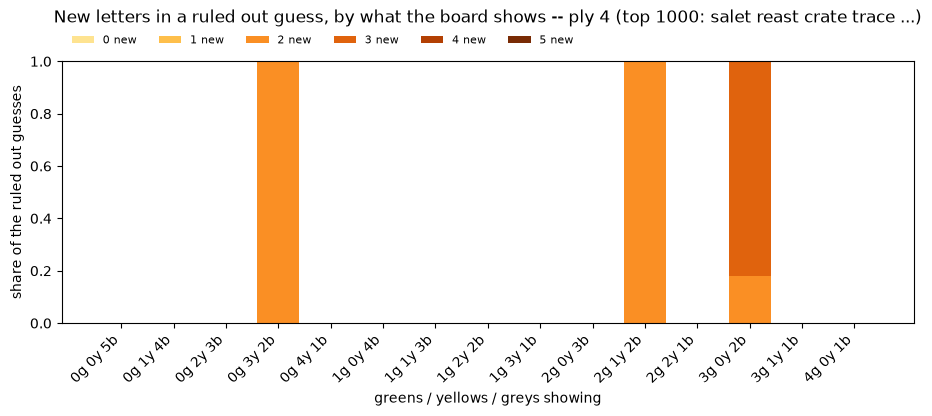

ply 5: possible answer 1.12 new letters on average


,n_positions,n_answers,possible answer,consistent non-answer,ruled out,possible answer (share of kind)
new_letters,,,,,,
0,214,214,214,0,0,0.091025
1,1643,1643,1643,0,0,0.698852
2,491,491,491,0,0,0.208847
3,3,3,3,0,0,0.001276


  no ruled out guess anywhere at ply 5
all plies: possible answer 1.35 new letters on average, consistent non-answer 3.99 new letters on average, ruled out 4.12 new letters on average


,n_positions,n_answers,possible answer,consistent non-answer,ruled out,possible answer (share of kind),consistent non-answer (share of kind),ruled out (share of kind)
new_letters,,,,,,,,
0,286917,305568,286915,2,0,0.123937,0.000626,0.000000
1,1108752,1384630,1108612,26,114,0.478882,0.008138,0.001684
2,750798,1317066,748331,266,2201,0.323253,0.083255,0.032517
3,173959,730830,158919,852,14188,0.068648,0.266667,0.209612
4,35686,609958,10985,625,24076,0.004745,0.195618,0.355696
5,29770,3723625,1238,1424,27108,0.000535,0.445696,0.400490


  the 67,687 ruled out guesses, by board and new-letter count:


n_positions  mean_new    0         1         2  \
greens yellows grays                                                   
0      0       5              108  3.935185  0.0  0.000000  0.000000   
       1       4             4770  4.818449  0.0  0.000000  0.002725   
       2       3            10127  4.109509  0.0  0.000494  0.013232   
       3       2             5627  3.485339  0.0  0.004621  0.096677   
       4       1              764  3.160995  0.0  0.022251  0.205497   
1      0       4             5778  4.757182  0.0  0.000000  0.003981   
       1       3            15540  4.279794  0.0  0.000064  0.022008   
       2       2             8165  3.801102  0.0  0.004287  0.039437   
       3       1             1041  3.431316  0.0  0.009606  0.097983   
2      0       3             6639  4.386203  0.0  0.000151  0.015514   
       1       2             5185  3.806750  0.0  0.001929  0.045130   
       2       1              670  3.426866  0.0  0.004478  0.074627   
3      0       2             2331  3.800086  0.0  0.001287  0.059202   
       1       1              441  3.378685  0.0  0.000000  0.058957   
4      0       1              501  3.524950  0.0  0.005988  0.025948   

                             3         4         5  
greens yellows grays                                
0      0       5      0.064815  0.935185  0.000000  
       1       4      0.038574  0.096226  0.862474  
       2       3      0.185247  0.478325  0.322702  
       3       2      0.417452  0.371246  0.110005  
       4       1      0.458115  0.217277  0.096859  
1      0       4      0.046729  0.137418  0.811873  
       1       3      0.142793  0.368340  0.466795  
       2       2      0.311084  0.441274  0.203919  
       3       1      0.431316  0.373679  0.087416  
2      0       3      0.130893  0.304865  0.548577  
       1       2      0.304147  0.441851  0.206943  
       2       1      0.485075  0.361194  0.074627  
3      0       2      0.293436  0.430287  0.215787  
       1       1      0.551020  0.342404  0.047619  
4      0       1      0.491018  0.391218  0.085828

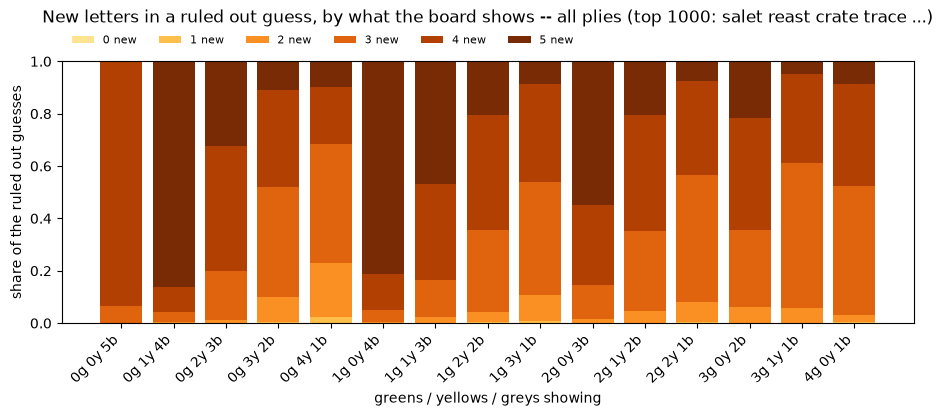

In [11]:
MIX_KIND = KIND_RULED_OUT     # <-- whose guesses to break down; any of KINDS

# An ORDINAL ramp, not the categorical KIND_COLORS: 0 to 5 new letters is a scale.
NEW_COLORS = plt.get_cmap('YlOrBr')(np.linspace(0.25, 0.95, wordle.WORD_LEN + 1))


def count_mix(frame, index, column):
    """positions per (`index`, `column`), every count 0..5 present.

    `column` is any per-position count on the frame -- new letters, greens kept,
    yellows kept -- so one pivot serves this section and the one below it."""
    return (frame.pivot_table(index=index, columns=column, values='guess',
                              aggfunc='size', fill_value=0, observed=False)
                 .reindex(columns=range(wordle.WORD_LEN + 1), fill_value=0))


def mix_chart(table, rows, title, xlabel, ylabel, legend, fmt=None,
              colors=None, width=11, height=3.4):
    """Each row's distribution over an ordinal count, stacked to 1.

    `legend` names a segment, e.g. '{n} new' or '{n} kept'. `colors` is the ordinal
    ramp, defaulting to NEW_COLORS -- a caller stacking something other than a
    0..5 count supplies its own, since one ramp cannot span two scales.

    A row the scope never reached sums to 0 and is left blank rather than drawn as
    a full bar of nothing."""
    fmt = fmt or (lambda r: ' '.join(str(x) for x in r) if isinstance(r, tuple) else str(r))
    counts = table.reindex(rows).fillna(0)
    share = counts.div(counts.sum(axis=1), axis=0).fillna(0)

    fig, ax = plt.subplots(figsize=(width, height))
    bottom = np.zeros(len(rows))
    for n, color in zip(share.columns, NEW_COLORS if colors is None else colors):
        ax.bar([fmt(r) for r in rows], share[n], bottom=bottom, color=color,
               label=legend.format(n=n))
        bottom = bottom + share[n].to_numpy()
    ax.set_ylim(0, 1)
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    ax.tick_params(axis='x', labelrotation=45)
    for lab in ax.get_xticklabels():
        lab.set_horizontalalignment('right')
    ax.legend(fontsize=8, ncol=min(len(share.columns), wordle.WORD_LEN + 1),
              loc='lower left', bbox_to_anchor=(0, 1.02), frameon=False)
    ax.set_title(title, pad=28)
    plt.show()


newletter_tables, mix_tables = {}, {}
for label, frame in scope_frames(board):
    table = (by_kind(frame, 'new_letters')
               .rename(columns={'total': 'n_positions'})
               .join(frame.groupby('new_letters')['n_answers'].sum()))
    newletter_tables[label] = table[['n_positions', 'n_answers'] + list(KINDS)]
    mix_tables[label] = count_mix(frame[frame['guess_kind'] == MIX_KIND],
                                 ['greens', 'yellows', 'grays'], 'new_letters')

_rows = kind_rows(list(newletter_tables.items()))
_mix_rows = list(pd.concat([t for t in mix_tables.values()]).index.unique().sort_values())
_board = lambda r: f'{r[0]}g {r[1]}y {r[2]}b'

for label, table in newletter_tables.items():
    counts = table[list(KINDS)]
    means = {k: (table.index * counts[k]).sum() / counts[k].sum()
             for k in KINDS if counts[k].sum()}
    print(f'{label}: ' + ', '.join(f'{k} {v:.2f} new letters on average'
                                   for k, v in means.items()))
    display(pd.concat([table[table['n_positions'] > 0],
                       counts.div(counts.sum()).add_suffix(' (share of kind)')],
                      axis=1).dropna(axis=1, how='all'))

    mix = mix_tables[label]
    played = mix.sum(axis=1)
    if not played.any():
        print(f'  no {MIX_KIND} guess anywhere at {label}')
        continue
    share = mix.div(played, axis=0)
    print(f'  the {int(played.sum()):,} {MIX_KIND} guesses, by board and new-letter count:')
    display(pd.concat([played.rename('n_positions'),
                       (mix.mul(mix.columns).sum(axis=1) / played).rename('mean_new'),
                       share], axis=1)[played > 0])
    mix_chart(mix, _mix_rows,
              f'New letters in a {MIX_KIND} guess, by what the board shows '
              f'-- {label} ({LABEL})', 'greens / yellows / greys showing',
              f'share of the {MIX_KIND} guesses', '{n} new', fmt=_board)

## How much of what the board proves does the guess keep?

Two more breakdowns on the same boards: of the positions showing at least one **green**, how
many of those greens the guess replays; and of the positions showing at least one **yellow**,
how many of those yellows it carries. Grouped **by ply** — each ply gets its greens chart and
its yellows chart together, and then the pooled pair — since the two are read against each
other at a given turn rather than down the turns.

**What "kept" means, exactly** — the hard-mode reading, stated because the counting is a
choice:

- a **green** is kept when the guess plays that letter **on that very square**. A board with
  `greens = G` can keep 0 to G of them.
- a **yellow** is a KNOWN COPY of a letter not yet placed, so it is kept when the guess
  **supplies a copy of that letter** — anywhere, the excluded square included. Per letter
  that is `min(copies in the guess not spent on a green it kept, copies still unplaced)`,
  summed over letters, which for the ordinary single-copy case is just "the guess contains
  the letter".

> **Only a `ruled out` guess can drop either**, and that is forced, not measured: a word
> consistent with the clues has the greens in place and holds at least as many copies of a
> known letter as the board proves. So every bar's shortfall from "all kept" is a ruled-out
> guess, and `KEEP_KIND` restricts to one kind when the choices alone are wanted. The cell
> **asserts** the implication at every position — it is a free cross-check between
> `tree_states`' cumulative state and the consistency test that `positions()` ran separately.

Counted by **POSITIONS**, the unit being the choice; each bar is normalised over the
composition it stands on, so it is a distribution of "how many kept" and sums to 1.

positions showing at least one: greens 2,079,526, yellows 1,700,283

===== ply 0 =====
greens: no position shows one
yellows: no position shows one

===== ply 1 =====
greens: 90,187 positions, 69.41% keep every green, 1.13 kept on average


n_positions  mean_greens_kept         0         1  \
greens yellows grays                                                      
1      0       4             4995          0.082883  0.917117  0.082883   
       1       3            19194          0.432010  0.567990  0.432010   
       2       2            22092          0.823239  0.176761  0.823239   
       3       1             5906          0.960210  0.039790  0.960210   
       4       0              228          1.000000  0.000000  1.000000   
2      0       3             9004          0.983230  0.495891  0.024989   
       1       2            15597          1.755081  0.117715  0.009489   
       2       1             4128          1.955184  0.021560  0.001696   
       3       0              104          2.000000  0.000000  0.000000   
3      0       2             5669          2.457223  0.164756  0.024167   
       1       1             1869          2.918138  0.025147  0.003210   
       2       0              110          3.000000  0.000000  0.000000   
4      0       1             1291          3.781565  0.048799  0.007746   

                             2         3         4    5  
greens yellows grays                                     
1      0       4      0.000000  0.000000  0.000000  0.0  
       1       3      0.000000  0.000000  0.000000  0.0  
       2       2      0.000000  0.000000  0.000000  0.0  
       3       1      0.000000  0.000000  0.000000  0.0  
       4       0      0.000000  0.000000  0.000000  0.0  
2      0       3      0.479120  0.000000  0.000000  0.0  
       1       2      0.872796  0.000000  0.000000  0.0  
       2       1      0.976744  0.000000  0.000000  0.0  
       3       0      1.000000  0.000000  0.000000  0.0  
3      0       2      0.000176  0.810901  0.000000  0.0  
       1       1      0.000000  0.971643  0.000000  0.0  
       2       0      0.000000  1.000000  0.000000  0.0  
4      0       1      0.000000  0.000000  0.943455  0.0

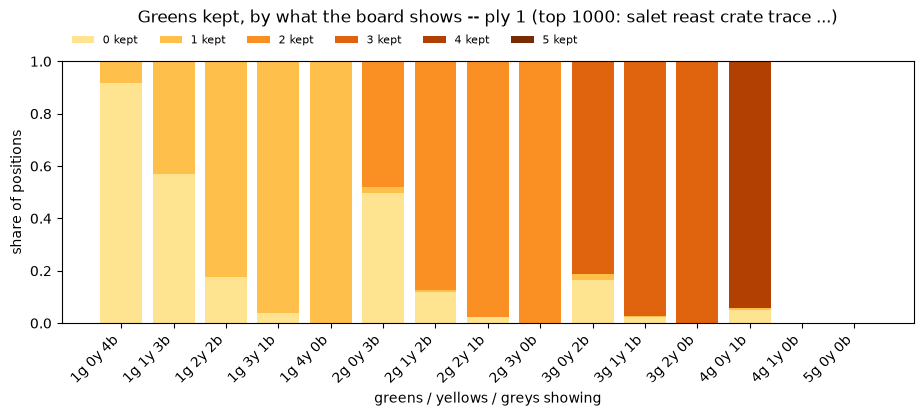

yellows: 97,599 positions, 72.00% keep every yellow, 1.46 kept on average


n_positions  mean_yellows_kept         0         1  \
greens yellows grays                                                       
0      1       4             5000           0.264000  0.736000  0.264000   
       2       3             9997           1.055317  0.261679  0.421326   
       3       2             9666           2.371508  0.044796  0.174219   
       4       1             3527           3.803799  0.011908  0.020981   
       5       0              181           5.000000  0.000000  0.000000   
1      1       3            19194           0.612431  0.387569  0.612431   
       2       2            22092           1.753259  0.079576  0.087588   
       3       1             5906           2.906536  0.015747  0.020488   
       4       0              228           4.000000  0.000000  0.000000   
2      1       2            15597           0.903507  0.096493  0.903507   
       2       1             4128           1.963663  0.014535  0.007267   
       3       0              104           3.000000  0.000000  0.000000   
3      1       1             1869           0.974853  0.025147  0.974853   
       2       0              110           2.000000  0.000000  0.000000   

                             2         3         4    5  
greens yellows grays                                     
0      1       4      0.000000  0.000000  0.000000  0.0  
       2       3      0.316995  0.000000  0.000000  0.0  
       3       2      0.145665  0.635320  0.000000  0.0  
       4       1      0.039410  0.006805  0.920896  0.0  
       5       0      0.000000  0.000000  0.000000  1.0  
1      1       3      0.000000  0.000000  0.000000  0.0  
       2       2      0.832835  0.000000  0.000000  0.0  
       3       1      0.005249  0.958517  0.000000  0.0  
       4       0      0.000000  0.000000  1.000000  0.0  
2      1       2      0.000000  0.000000  0.000000  0.0  
       2       1      0.978198  0.000000  0.000000  0.0  
       3       0      0.000000  1.000000  0.000000  0.0  
3      1       1      0.000000  0.000000  0.000000  0.0  
       2       0      1.000000  0.000000  0.000000  0.0

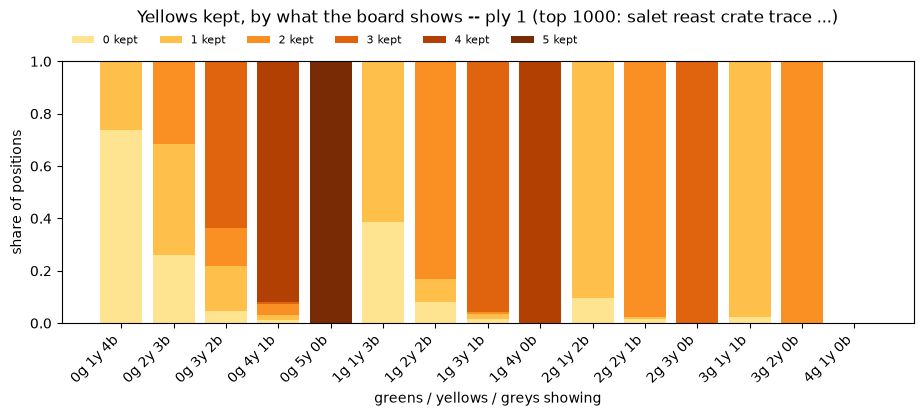


===== ply 2 =====
greens: 977,045 positions, 98.28% keep every green, 1.81 kept on average


n_positions  mean_greens_kept         0         1  \
greens yellows grays                                                      
1      0       4            10583          0.887272  0.112728  0.887272   
       1       3            77429          0.946738  0.053262  0.946738   
       2       2           181145          0.980325  0.019675  0.980325   
       3       1           133573          0.994542  0.005458  0.994542   
       4       0            24151          1.000000  0.000000  1.000000   
2      0       3            40120          1.911117  0.040877  0.007129   
       1       2           150885          1.963429  0.016735  0.003102   
       2       1           128207          1.991740  0.003892  0.000476   
       3       0            24098          2.000000  0.000000  0.000000   
3      0       2            64477          2.950835  0.014083  0.003459   
       1       1            72117          2.984692  0.004645  0.000679   
       2       0            16312          3.000000  0.000000  0.000000   
4      0       1            45333          3.979551  0.004522  0.000728   
       1       0             6861          4.000000  0.000000  0.000000   
5      0       0             1754          5.000000  0.000000  0.000000   

                             2         3         4    5  
greens yellows grays                                     
1      0       4      0.000000  0.000000  0.000000  0.0  
       1       3      0.000000  0.000000  0.000000  0.0  
       2       2      0.000000  0.000000  0.000000  0.0  
       3       1      0.000000  0.000000  0.000000  0.0  
       4       0      0.000000  0.000000  0.000000  0.0  
2      0       3      0.951994  0.000000  0.000000  0.0  
       1       2      0.980164  0.000000  0.000000  0.0  
       2       1      0.995632  0.000000  0.000000  0.0  
       3       0      1.000000  0.000000  0.000000  0.0  
3      0       2      0.000000  0.982459  0.000000  0.0  
       1       1      0.000014  0.994661  0.000000  0.0  
       2       0      0.000000  1.000000  0.000000  0.0  
4      0       1      0.000088  0.000000  0.994662  0.0  
       1       0      0.000000  0.000000  1.000000  0.0  
5      0       0      0.000000  0.000000  0.000000  1.0

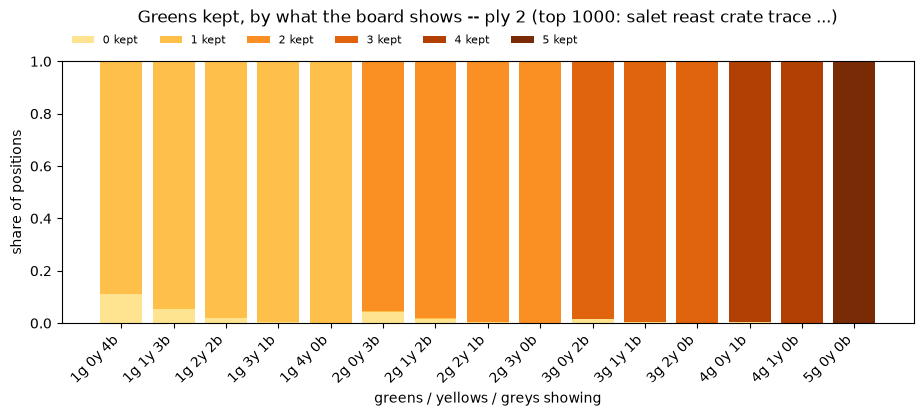

yellows: 1,005,414 positions, 98.25% keep every yellow, 2.08 kept on average


n_positions  mean_yellows_kept         0         1  \
greens yellows grays                                                       
0      1       4             9819           0.903351  0.096649  0.903351   
       2       3            38907           1.875652  0.041406  0.041535   
       3       2            75507           2.942615  0.007814  0.014224   
       4       1            55919           3.975375  0.001609  0.004256   
       5       0            10484           5.000000  0.000000  0.000000   
1      1       3            77429           0.958504  0.041496  0.958504   
       2       2           181145           1.968075  0.011218  0.009490   
       3       1           133573           2.986517  0.002426  0.002688   
       4       0            24151           4.000000  0.000000  0.000000   
2      1       2           150885           0.984922  0.015078  0.984922   
       2       1           128207           1.993417  0.002379  0.001825   
       3       0            24098           3.000000  0.000000  0.000000   
3      1       1            72117           0.995951  0.004049  0.995951   
       2       0            16312           2.000000  0.000000  0.000000   
4      1       0             6861           1.000000  0.000000  1.000000   

                             2         3         4    5  
greens yellows grays                                     
0      1       4      0.000000  0.000000  0.000000  0.0  
       2       3      0.917059  0.000000  0.000000  0.0  
       3       2      0.005496  0.972466  0.000000  0.0  
       4       1      0.002611  0.000197  0.991327  0.0  
       5       0      0.000000  0.000000  0.000000  1.0  
1      1       3      0.000000  0.000000  0.000000  0.0  
       2       2      0.979293  0.000000  0.000000  0.0  
       3       1      0.000831  0.994056  0.000000  0.0  
       4       0      0.000000  0.000000  1.000000  0.0  
2      1       2      0.000000  0.000000  0.000000  0.0  
       2       1      0.995796  0.000000  0.000000  0.0  
       3       0      0.000000  1.000000  0.000000  0.0  
3      1       1      0.000000  0.000000  0.000000  0.0  
       2       0      1.000000  0.000000  0.000000  0.0  
4      1       0      0.000000  0.000000  0.000000  0.0

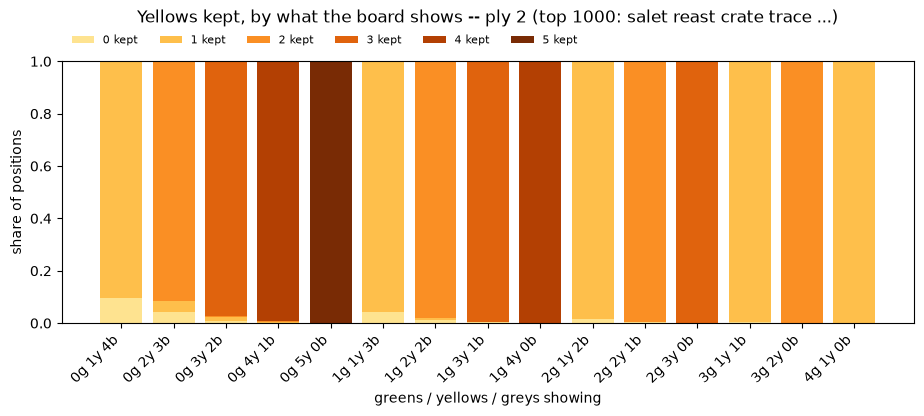


===== ply 3 =====
greens: 908,198 positions, 99.92% keep every green, 2.50 kept on average


n_positions  mean_greens_kept         0         1  \
greens yellows grays                                                      
1      0       4             6085          0.999836  0.000164  0.999836   
       1       3            47301          0.999049  0.000951  0.999049   
       2       2            91343          0.998413  0.001587  0.998413   
       3       1            53189          0.999962  0.000038  0.999962   
       4       0             9087          1.000000  0.000000  1.000000   
2      0       3            48230          1.999129  0.000394  0.000083   
       1       2           120438          1.996795  0.001519  0.000166   
       2       1            73085          1.999672  0.000137  0.000055   
       3       0             9900          2.000000  0.000000  0.000000   
3      0       2           144363          2.997790  0.000589  0.000222   
       1       1            78110          2.999885  0.000038  0.000000   
       2       0            12770          3.000000  0.000000  0.000000   
4      0       1           211115          3.996490  0.000867  0.000014   
       1       0             2686          4.000000  0.000000  0.000000   
5      0       0              496          5.000000  0.000000  0.000000   

                             2         3         4    5  
greens yellows grays                                     
1      0       4      0.000000  0.000000  0.000000  0.0  
       1       3      0.000000  0.000000  0.000000  0.0  
       2       2      0.000000  0.000000  0.000000  0.0  
       3       1      0.000000  0.000000  0.000000  0.0  
       4       0      0.000000  0.000000  0.000000  0.0  
2      0       3      0.999523  0.000000  0.000000  0.0  
       1       2      0.998314  0.000000  0.000000  0.0  
       2       1      0.999808  0.000000  0.000000  0.0  
       3       0      1.000000  0.000000  0.000000  0.0  
3      0       2      0.000000  0.999190  0.000000  0.0  
       1       1      0.000000  0.999962  0.000000  0.0  
       2       0      0.000000  1.000000  0.000000  0.0  
4      0       1      0.000000  0.000000  0.999119  0.0  
       1       0      0.000000  0.000000  1.000000  0.0  
5      0       0      0.000000  0.000000  0.000000  1.0

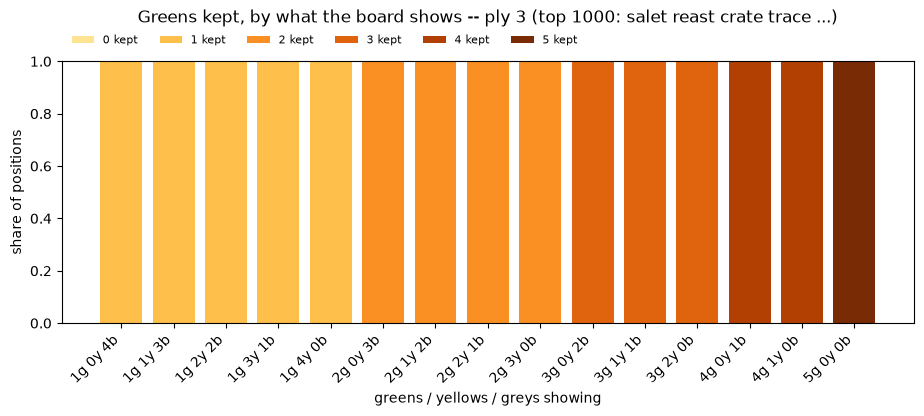

yellows: 581,494 positions, 99.94% keep every yellow, 1.86 kept on average


n_positions  mean_yellows_kept         0         1  \
greens yellows grays                                                       
0      1       4             3391           1.000000  0.000000  1.000000   
       2       3            18711           1.998985  0.000321  0.000374   
       3       2            37419           2.999118  0.000187  0.000134   
       4       1            20965           4.000000  0.000000  0.000000   
       5       0             3099           5.000000  0.000000  0.000000   
1      1       3            47301           0.999049  0.000951  0.999049   
       2       2            91343           1.997373  0.000865  0.000898   
       3       1            53189           2.999887  0.000038  0.000000   
       4       0             9087           4.000000  0.000000  0.000000   
2      1       2           120438           0.999029  0.000971  0.999029   
       2       1            73085           1.999685  0.000123  0.000068   
       3       0             9900           3.000000  0.000000  0.000000   
3      1       1            78110           0.999962  0.000038  0.999962   
       2       0            12770           2.000000  0.000000  0.000000   
4      1       0             2686           1.000000  0.000000  1.000000   

                             2         3    4    5  
greens yellows grays                                
0      1       4      0.000000  0.000000  0.0  0.0  
       2       3      0.999305  0.000000  0.0  0.0  
       3       2      0.000053  0.999626  0.0  0.0  
       4       1      0.000000  0.000000  1.0  0.0  
       5       0      0.000000  0.000000  0.0  1.0  
1      1       3      0.000000  0.000000  0.0  0.0  
       2       2      0.998237  0.000000  0.0  0.0  
       3       1      0.000000  0.999962  0.0  0.0  
       4       0      0.000000  0.000000  1.0  0.0  
2      1       2      0.000000  0.000000  0.0  0.0  
       2       1      0.999808  0.000000  0.0  0.0  
       3       0      0.000000  1.000000  0.0  0.0  
3      1       1      0.000000  0.000000  0.0  0.0  
       2       0      1.000000  0.000000  0.0  0.0  
4      1       0      0.000000  0.000000  0.0  0.0

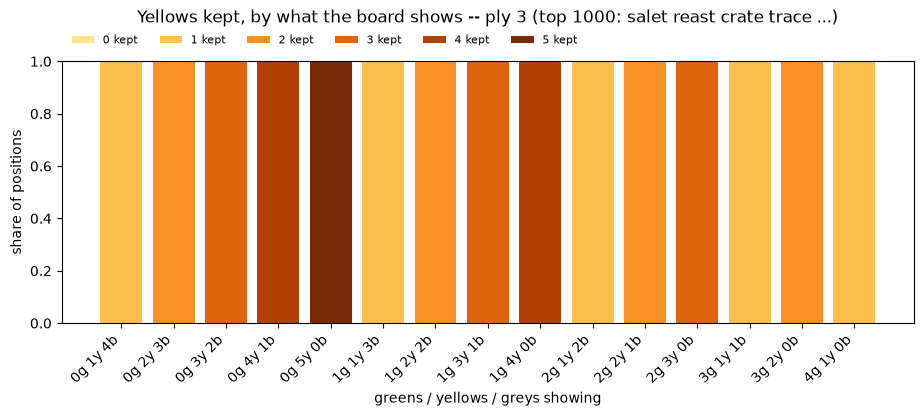


===== ply 4 =====
greens: 101,748 positions, 99.99% keep every green, 3.43 kept on average


n_positions  mean_greens_kept         0    1         2  \
greens yellows grays                                                           
1      0       4               37          1.000000  0.000000  1.0  0.000000   
       1       3              568          1.000000  0.000000  1.0  0.000000   
       2       2             1391          1.000000  0.000000  1.0  0.000000   
       3       1              886          1.000000  0.000000  1.0  0.000000   
       4       0              130          1.000000  0.000000  1.0  0.000000   
2      0       3             3840          2.000000  0.000000  0.0  1.000000   
       1       2             4451          1.999551  0.000225  0.0  0.999775   
       2       1             2051          2.000000  0.000000  0.0  1.000000   
       3       0              234          2.000000  0.000000  0.0  1.000000   
3      0       2            22561          2.998537  0.000488  0.0  0.000000   
       1       1             4550          3.000000  0.000000  0.0  0.000000   
       2       0              487          3.000000  0.000000  0.0  0.000000   
4      0       1            59949          4.000000  0.000000  0.0  0.000000   
       1       0              405          4.000000  0.000000  0.0  0.000000   
5      0       0              208          5.000000  0.000000  0.0  0.000000   

                             3    4    5  
greens yellows grays                      
1      0       4      0.000000  0.0  0.0  
       1       3      0.000000  0.0  0.0  
       2       2      0.000000  0.0  0.0  
       3       1      0.000000  0.0  0.0  
       4       0      0.000000  0.0  0.0  
2      0       3      0.000000  0.0  0.0  
       1       2      0.000000  0.0  0.0  
       2       1      0.000000  0.0  0.0  
       3       0      0.000000  0.0  0.0  
3      0       2      0.999512  0.0  0.0  
       1       1      1.000000  0.0  0.0  
       2       0      1.000000  0.0  0.0  
4      0       1      0.000000  1.0  0.0  
       1       0      0.000000  1.0  0.0  
5      0       0      0.000000  0.0  1.0

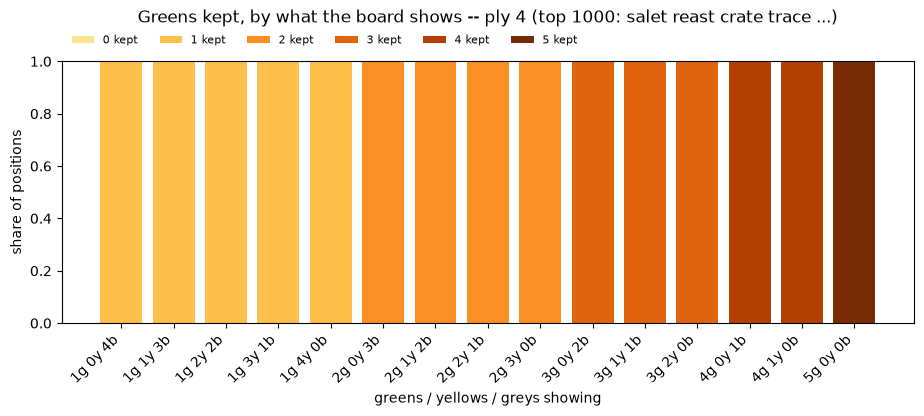

yellows: 15,719 positions, 99.99% keep every yellow, 1.49 kept on average


n_positions  mean_yellows_kept         0         1    2  \
greens yellows grays                                                            
0      1       4                5           1.000000  0.000000  1.000000  0.0   
       2       3              121           2.000000  0.000000  0.000000  1.0   
       3       2              263           2.988593  0.003802  0.000000  0.0   
       4       1              159           4.000000  0.000000  0.000000  0.0   
       5       0               18           5.000000  0.000000  0.000000  0.0   
1      1       3              568           1.000000  0.000000  1.000000  0.0   
       2       2             1391           2.000000  0.000000  0.000000  1.0   
       3       1              886           3.000000  0.000000  0.000000  0.0   
       4       0              130           4.000000  0.000000  0.000000  0.0   
2      1       2             4451           0.999775  0.000225  0.999775  0.0   
       2       1             2051           2.000000  0.000000  0.000000  1.0   
       3       0              234           3.000000  0.000000  0.000000  0.0   
3      1       1             4550           1.000000  0.000000  1.000000  0.0   
       2       0              487           2.000000  0.000000  0.000000  1.0   
4      1       0              405           1.000000  0.000000  1.000000  0.0   

                             3    4    5  
greens yellows grays                      
0      1       4      0.000000  0.0  0.0  
       2       3      0.000000  0.0  0.0  
       3       2      0.996198  0.0  0.0  
       4       1      0.000000  1.0  0.0  
       5       0      0.000000  0.0  1.0  
1      1       3      0.000000  0.0  0.0  
       2       2      0.000000  0.0  0.0  
       3       1      1.000000  0.0  0.0  
       4       0      0.000000  1.0  0.0  
2      1       2      0.000000  0.0  0.0  
       2       1      0.000000  0.0  0.0  
       3       0      1.000000  0.0  0.0  
3      1       1      0.000000  0.0  0.0  
       2       0      0.000000  0.0  0.0  
4      1       0      0.000000  0.0  0.0

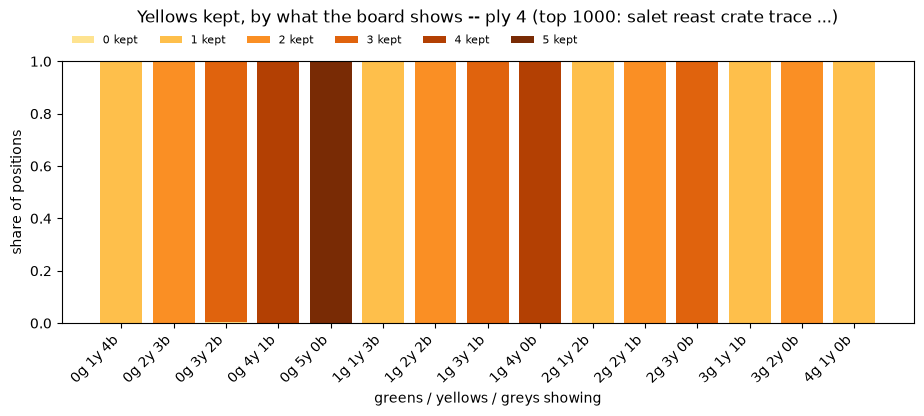


===== ply 5 =====
greens: 2,348 positions, 100.00% keep every green, 3.65 kept on average


n_positions  mean_greens_kept    0    1    2    3    4  \
greens yellows grays                                                           
1      2       2                1               1.0  0.0  1.0  0.0  0.0  0.0   
2      0       3               56               2.0  0.0  0.0  1.0  0.0  0.0   
       1       2               14               2.0  0.0  0.0  1.0  0.0  0.0   
       2       1                4               2.0  0.0  0.0  1.0  0.0  0.0   
3      0       2              635               3.0  0.0  0.0  0.0  1.0  0.0   
       1       1               35               3.0  0.0  0.0  0.0  1.0  0.0   
4      0       1             1603               4.0  0.0  0.0  0.0  0.0  1.0   

                        5  
greens yellows grays       
1      2       2      0.0  
2      0       3      0.0  
       1       2      0.0  
       2       1      0.0  
3      0       2      0.0  
       1       1      0.0  
4      0       1      0.0

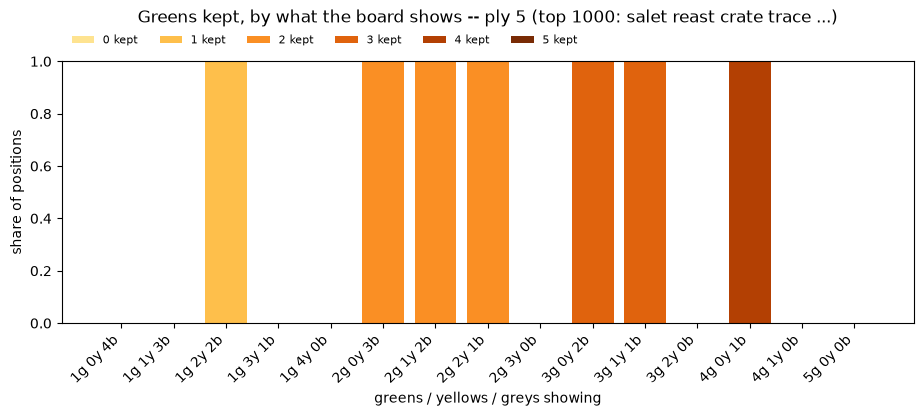

yellows: 57 positions, 100.00% keep every yellow, 1.23 kept on average


n_positions  mean_yellows_kept    0    1    2    3    4  \
greens yellows grays                                                            
0      3       2                1                3.0  0.0  0.0  0.0  1.0  0.0   
       4       1                2                4.0  0.0  0.0  0.0  0.0  1.0   
1      2       2                1                2.0  0.0  0.0  1.0  0.0  0.0   
2      1       2               14                1.0  0.0  1.0  0.0  0.0  0.0   
       2       1                4                2.0  0.0  0.0  1.0  0.0  0.0   
3      1       1               35                1.0  0.0  1.0  0.0  0.0  0.0   

                        5  
greens yellows grays       
0      3       2      0.0  
       4       1      0.0  
1      2       2      0.0  
2      1       2      0.0  
       2       1      0.0  
3      1       1      0.0

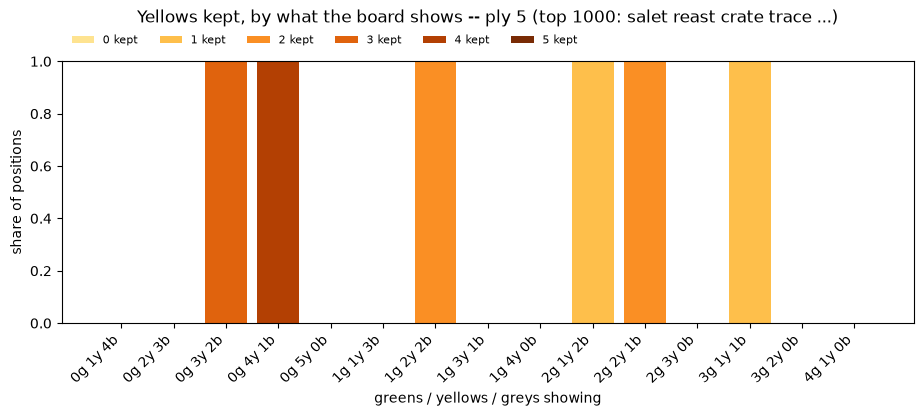


===== all plies =====
greens: 2,079,526 positions, 97.83% keep every green, 2.16 kept on average


n_positions  mean_greens_kept         0         1  \
greens yellows grays                                                      
1      0       4            21700          0.733871  0.266129  0.733871   
       1       3           144492          0.895697  0.104303  0.895697   
       2       2           295972          0.974275  0.025725  0.974275   
       3       1           193554          0.995009  0.004991  0.995009   
       4       0            33596          1.000000  0.000000  1.000000   
2      0       3           101250          1.873946  0.060484  0.005086   
       1       2           291385          1.966621  0.015598  0.002183   
       2       1           207475          1.993888  0.002882  0.000347   
       3       0            34336          2.000000  0.000000  0.000000   
3      0       2           237705          2.972239  0.008153  0.001649   
       1       1           156681          2.991920  0.002457  0.000351   
       2       0            29679          3.000000  0.000000  0.000000   
4      0       1           319291          3.993893  0.001413  0.000144   
       1       0             9952          4.000000  0.000000  0.000000   
5      0       0             2458          5.000000  0.000000  0.000000   

                             2         3         4    5  
greens yellows grays                                     
1      0       4      0.000000  0.000000  0.000000  0.0  
       1       3      0.000000  0.000000  0.000000  0.0  
       2       2      0.000000  0.000000  0.000000  0.0  
       3       1      0.000000  0.000000  0.000000  0.0  
       4       0      0.000000  0.000000  0.000000  0.0  
2      0       3      0.934430  0.000000  0.000000  0.0  
       1       2      0.982219  0.000000  0.000000  0.0  
       2       1      0.996771  0.000000  0.000000  0.0  
       3       0      1.000000  0.000000  0.000000  0.0  
3      0       2      0.000004  0.990194  0.000000  0.0  
       1       1      0.000006  0.997185  0.000000  0.0  
       2       0      0.000000  1.000000  0.000000  0.0  
4      0       1      0.000013  0.000000  0.998431  0.0  
       1       0      0.000000  0.000000  1.000000  0.0  
5      0       0      0.000000  0.000000  0.000000  1.0

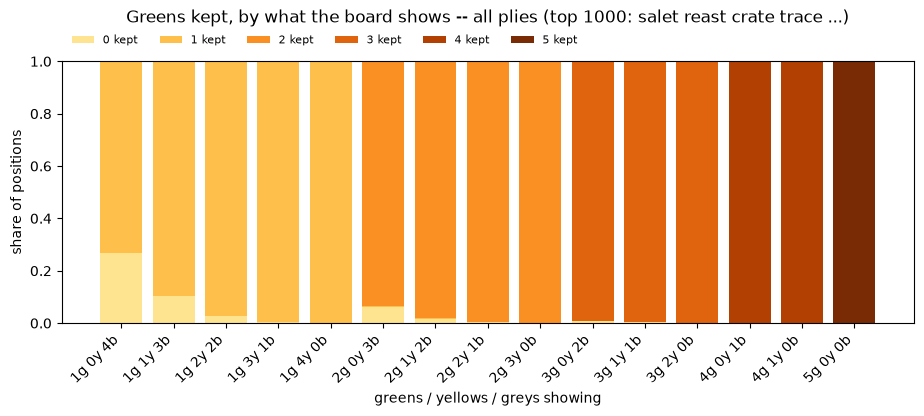

yellows: 1,700,283 positions, 97.34% keep every yellow, 1.96 kept on average


n_positions  mean_yellows_kept         0         1  \
greens yellows grays                                                       
0      1       4            18215           0.745869  0.254131  0.745869   
       2       3            67736           1.788872  0.062493  0.086143   
       3       2           122856           2.914990  0.008392  0.022490   
       4       1            80572           3.974321  0.001638  0.003872   
       5       0            13782           5.000000  0.000000  0.000000   
1      1       3           144492           0.925968  0.074032  0.925968   
       2       2           295972           1.961233  0.013072  0.012623   
       3       1           193554           2.987812  0.002165  0.002480   
       4       0            33596           4.000000  0.000000  0.000000   
2      1       2           291385           0.986623  0.013377  0.986623   
       2       1           207475           1.995098  0.001803  0.001297   
       3       0            34336           3.000000  0.000000  0.000000   
3      1       1           156681           0.997817  0.002183  0.997817   
       2       0            29679           2.000000  0.000000  0.000000   
4      1       0             9952           1.000000  0.000000  1.000000   

                             2         3         4    5  
greens yellows grays                                     
0      1       4      0.000000  0.000000  0.000000  0.0  
       2       3      0.851364  0.000000  0.000000  0.0  
       3       2      0.014855  0.954264  0.000000  0.0  
       4       1      0.003537  0.000434  0.990518  0.0  
       5       0      0.000000  0.000000  0.000000  1.0  
1      1       3      0.000000  0.000000  0.000000  0.0  
       2       2      0.974305  0.000000  0.000000  0.0  
       3       1      0.000734  0.994622  0.000000  0.0  
       4       0      0.000000  0.000000  1.000000  0.0  
2      1       2      0.000000  0.000000  0.000000  0.0  
       2       1      0.996901  0.000000  0.000000  0.0  
       3       0      0.000000  1.000000  0.000000  0.0  
3      1       1      0.000000  0.000000  0.000000  0.0  
       2       0      1.000000  0.000000  0.000000  0.0  
4      1       0      0.000000  0.000000  0.000000  0.0

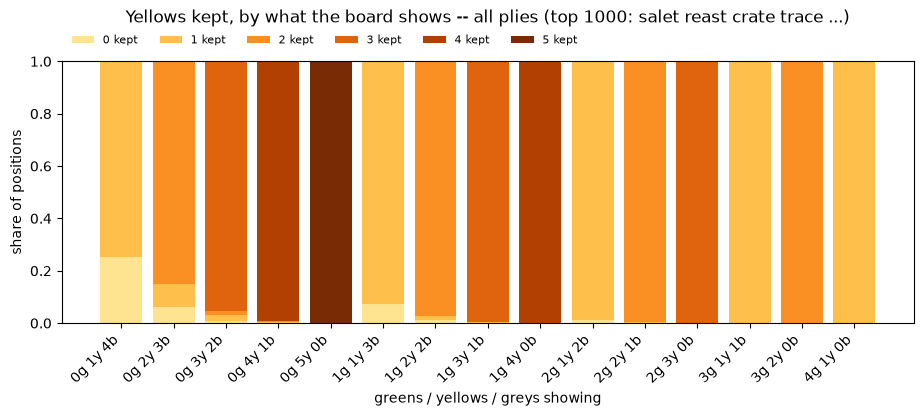

In [12]:
KEEP_KIND = None      # <-- None: every position; or one of KINDS to restrict to it

BOARD_INDEX = ['greens', 'yellows', 'grays']
KEEPS = (('greens', 'greens_kept'), ('yellows', 'yellows_kept'))

# Built colour-major (each needs its row set unioned across the scopes), then read
# ply-major below, so a ply's greens and yellows charts sit together.
_frames = {}
_tables = {}
for shown, kept in KEEPS:
    frame = board if KEEP_KIND is None else board[board['guess_kind'] == KEEP_KIND]
    _frames[shown] = frame = frame[frame[shown] > 0]
    _tables[shown] = {label: count_mix(sub, BOARD_INDEX, kept)
                      for label, sub in scope_frames(frame)}
_rows = {shown: list(pd.concat(list(t.values())).index.unique().sort_values())
         for shown, t in _tables.items()}

print('positions showing at least one'
      + ('' if KEEP_KIND is None else f', {KEEP_KIND} only') + ': '
      + ', '.join(f'{shown} {len(_frames[shown]):,}' for shown, _ in KEEPS))

for label, _ in scope_frames(board):
    print(f'\n===== {label} =====')
    for shown, kept in KEEPS:
        table = _tables[shown].get(label)
        played = table.sum(axis=1) if table is not None else None
        if table is None or not played.any():
            print(f'{shown}: no position shows one')
            continue
        all_kept = sum(table.loc[r, r[BOARD_INDEX.index(shown)]] for r in table.index)
        print(f'{shown}: {int(played.sum()):,} positions, '
              f'{all_kept / played.sum():.2%} keep every {shown[:-1]}, '
              f'{table.mul(table.columns).sum().sum() / played.sum():.2f} kept on average')
        display(pd.concat([played.rename('n_positions'),
                           (table.mul(table.columns).sum(axis=1) / played).rename(f'mean_{kept}'),
                           table.div(played, axis=0)], axis=1)[played > 0])
        mix_chart(table, _rows[shown],
                  f'{shown.capitalize()} kept, by what the board shows -- {label} ({LABEL})',
                  'greens / yellows / greys showing', 'share of positions', '{n} kept',
                  fmt=_board)

## How many words are still standing, by what the board shows

The section above asks *what the strategy plays* on a given board; this one asks *how much
is left to choose between*. For each ply and each greens/yellows/greys composition, the
distribution of `n_answers` — the answers still possible when the board looks like that.

The composition is the same cumulative reading as above — `tree_states`' definition,
imported rather than restated, so `greens` are POSITIONS pinned, `yellows` are known COPIES
not yet placed, and `grays` is the remainder. A row here is the same row there, and
`n_positions` / `n_answers` line up column for column.

**`DIST_WEIGHT` is the choice, and it changes every number in the table.** The two are
different aggregations of one distribution and rank compositions differently, so never
quote one as the other:

- **`answers`** (the default) — a position holding `n` answers contributes `n`, the
  repo-wide convention for a tree-state table (`tools/tree_states.py`, the user's call).
  It reads "the answer is out there and its board looks like this; this is how much company
  it has". Under it `mean` is exactly `sum(n²) / sum(n)` — `tree_states`' own `avg_answers`.
- **`positions`** — each position counts once whatever it holds: "the strategy is standing
  at a board like this; this is how big the node is". A tree is mostly LEAVES (one answer
  left, the last guess just plays it), so this reads far lower, and the `min`/`p25` columns
  are usually 1.

Quantiles are taken by the cumulative-weight rule and are **not interpolated** — a count of
words remaining that never occurred is not a quantile of anything.

The chart bins the same distribution on `OPTION_EDGES` (the bins the two sections above
use) and stacks each composition to 1, so a bar reads as the SHAPE of that board rather
than as its size; `n_positions` in the table is what says how much of the tree it is. The
ramp is deliberately not the new-letter one — a different scale gets a different ramp.

`SCOPES` is shared with the sections above: a panel per ply, then everything pooled. Ply 0
is the root, one position per tree holding the whole answer list.


ply 0 (top 1000: salet reast crate trace ...): 1,000 positions over 1 compositions, 2,315,000 answer-positions
  words remaining, answers-weighted: mean 2315.00, min 2,315, p25 2,315, median 2,315, p75 2,315, p90 2,315, max 2,315


,,,n_positions,n_answers,mean,min,p25,median,p75,p90,max
greens,yellows,grays,,,,,,,,,
0,0,5,1000,2315000,2315.0,2315,2315,2315,2315,2315,2315


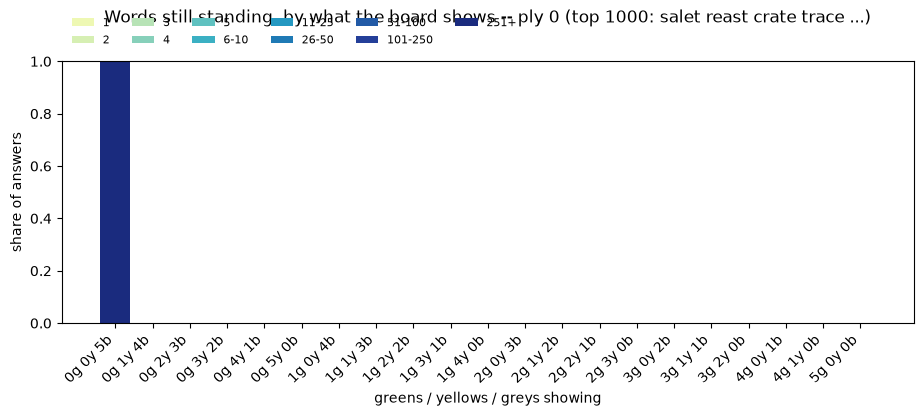

ply 1 (top 1000: salet reast crate trace ...): 119,558 positions over 19 compositions, 2,314,735 answer-positions
  words remaining, answers-weighted: mean 104.31, min 1, p25 25, median 71, p75 149, p90 265, max 506


n_positions  n_answers        mean  min  p25  median  \
greens yellows grays                                                         
0      0       5             1000     293225  305.723622  161  262     299   
       1       4             5000     609101  147.188727    9  107     139   
       2       3             9997     444735   65.982931    1   38      60   
       3       2             9666     122440   21.650539    1   11      18   
       4       1             3527      11613    5.762766    1    3       5   
       5       0              181        196    1.183673    1    1       1   
1      0       4             4995     260405   73.340024    1   46      69   
       1       3            19194     292791   26.461015    1   14      23   
       2       2            22092      99669    8.543007    1    4       7   
       3       1             5906      10573    2.726851    1    1       2   
       4       0              228        240    1.108333    1    1       1   
2      0       3             9004      94679   20.749047    1   10      16   
       1       2            15597      45967    5.574717    1    2       4   
       2       1             4128       5905    1.927011    1    1       1   
       3       0              104        104    1.000000    1    1       1   
3      0       2             5669      18427    6.141152    1    3       5   
       1       1             1869       2543    1.788832    1    1       1   
       2       0              110        110    1.000000    1    1       1   
4      0       1             1291       2012    2.139165    1    1       2   

                      p75  p90  max  
greens yellows grays                 
0      0       5      344  394  506  
       1       4      187  229  334  
       2       3       88  117  193  
       3       2       29   43   70  
       4       1        8   12   25  
       5       0        1    2    4  
1      0       4       98  123  185  
       1       3       34   47  108  
       2       2       11   17   38  
       3       1        4    6   12  
       4       0        1    1    3  
2      0       3       26   37   91  
       1       2        7   11   29  
       2       1        2    4    8  
       3       0        1    1    1  
3      0       2        8   13   27  
       1       1        2    3    7  
       2       0        1    1    1  
4      0       1        3    4    6

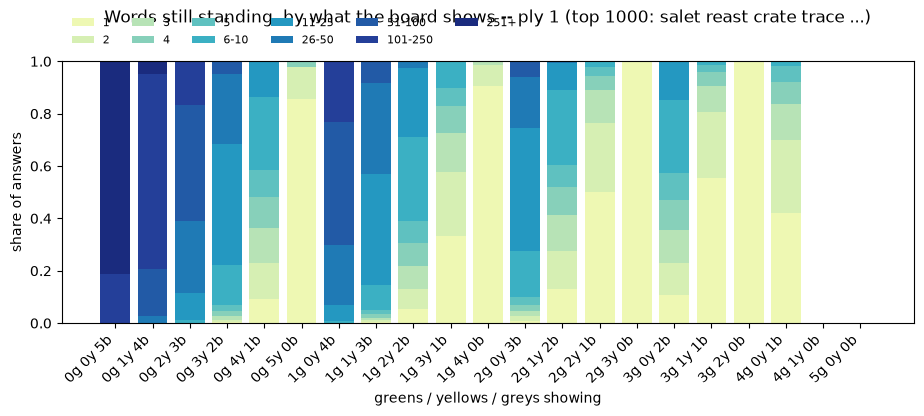

ply 2 (top 1000: salet reast crate trace ...): 1,168,681 positions over 21 compositions, 2,239,109 answer-positions
  words remaining, answers-weighted: mean 4.43, min 1, p25 1, median 2, p75 6, p90 11, max 46


n_positions  n_answers       mean  min  p25  median  \
greens yellows grays                                                        
0      0       5             1000      17716  19.552382    1   15      19   
       1       4             9819      83213  12.193780    1    7      12   
       2       3            38907     209673   9.902520    1    5       8   
       3       2            75507     208310   5.032212    1    2       4   
       4       1            55919      84030   2.141092    1    1       2   
       5       0            10484      10759   1.051864    1    1       1   
1      0       4            10583      57124   9.369687    1    5       8   
       1       3            77429     250059   6.051072    1    3       5   
       2       2           181145     341090   3.186555    1    1       2   
       3       1           133573     169699   1.589338    1    1       1   
       4       0            24151      24434   1.023164    1    1       1   
2      0       3            40120     100841   4.919993    1    2       4   
       1       2           150885     244590   2.598888    1    1       2   
       2       1           128207     153285   1.431797    1    1       1   
       3       0            24098      24178   1.006618    1    1       1   
3      0       2            64477      97102   2.263908    1    1       2   
       1       1            72117      84461   1.371580    1    1       1   
       2       0            16312      16318   1.000735    1    1       1   
4      0       1            45333      53612   1.361710    1    1       1   
       1       0             6861       6861   1.000000    1    1       1   
5      0       0             1754       1754   1.000000    1    1       1   

                      p75  p90  max  
greens yellows grays                 
0      0       5       23   26   46  
       1       4       16   20   43  
       2       3       13   19   46  
       3       2        7   10   31  
       4       1        3    4   12  
       5       0        1    1    3  
1      0       4       13   18   33  
       1       3        8   11   44  
       2       2        4    7   23  
       3       1        2    3    9  
       4       0        1    1    2  
2      0       3        6    9   41  
       1       2        3    5   19  
       2       1        2    2    7  
       3       0        1    1    2  
3      0       2        3    5   15  
       1       1        2    2    7  
       2       0        1    1    2  
4      0       1        2    2    5  
       1       0        1    1    1  
5      0       0        1    1    1

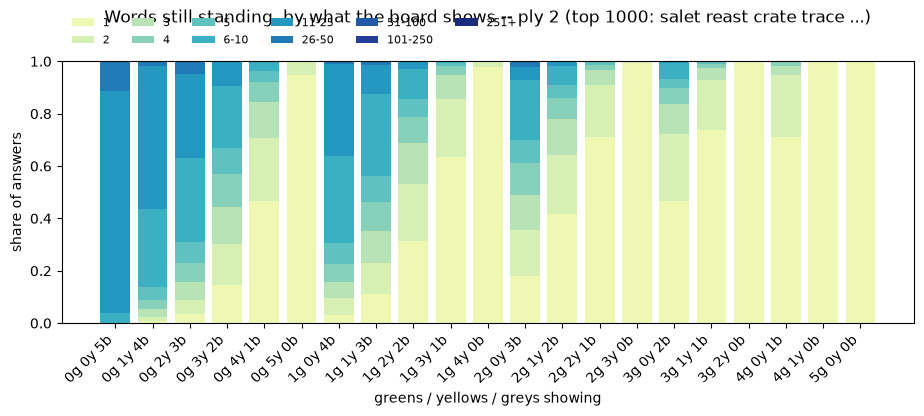

ply 3 (top 1000: salet reast crate trace ...): 991,978 positions over 21 compositions, 1,095,830 answer-positions
  words remaining, answers-weighted: mean 1.24, min 1, p25 1, median 1, p75 1, p90 2, max 12


n_positions  n_answers      mean  min  p25  median  p75  \
greens yellows grays                                                            
0      0       5              195        305  1.983607    1    1       2    3   
       1       4             3391       4135  1.449335    1    1       1    2   
       2       3            18711      22276  1.503771    1    1       1    2   
       3       2            37419      41350  1.259492    1    1       1    1   
       4       1            20965      21919  1.093709    1    1       1    1   
       5       0             3099       3108  1.005792    1    1       1    1   
1      0       4             6085       8227  1.859609    1    1       1    2   
       1       3            47301      54893  1.374765    1    1       1    1   
       2       2            91343     102207  1.323833    1    1       1    1   
       3       1            53189      55831  1.101485    1    1       1    1   
       4       0             9087       9088  1.000220    1    1       1    1   
2      0       3            48230      57417  1.452410    1    1       1    2   
       1       2           120438     132865  1.266752    1    1       1    1   
       2       1            73085      75692  1.072425    1    1       1    1   
       3       0             9900       9900  1.000000    1    1       1    1   
3      0       2           144363     164624  1.294902    1    1       1    1   
       1       1            78110      81419  1.082389    1    1       1    1   
       2       0            12770      12770  1.000000    1    1       1    1   
4      0       1           211115     234622  1.206929    1    1       1    1   
       1       0             2686       2686  1.000000    1    1       1    1   
5      0       0              496        496  1.000000    1    1       1    1   

                      p90  max  
greens yellows grays            
0      0       5        3    4  
       1       4        2    5  
       2       3        3   11  
       3       2        2    9  
       4       1        1    5  
       5       0        1    2  
1      0       4        4    8  
       1       3        2   12  
       2       2        2   11  
       3       1        1    4  
       4       0        1    2  
2      0       3        2   12  
       1       2        2   12  
       2       1        1    5  
       3       0        1    1  
3      0       2        2   10  
       1       1        1    4  
       2       0        1    1  
4      0       1        2    4  
       1       0        1    1  
5      0       0        1    1

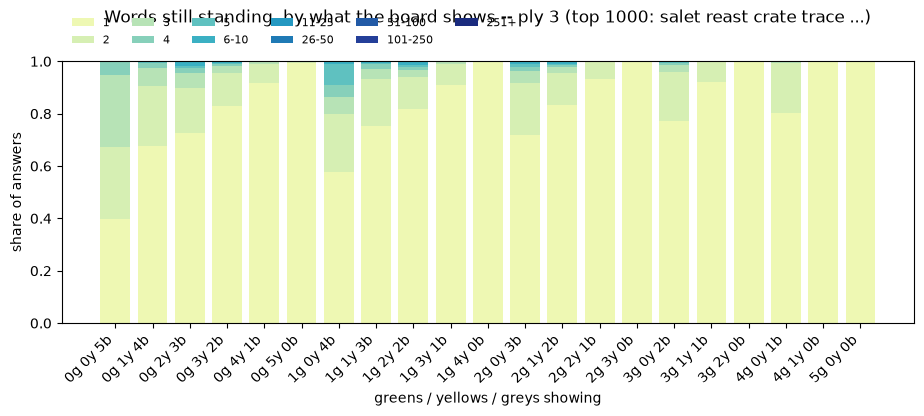

ply 4 (top 1000: salet reast crate trace ...): 102,314 positions over 20 compositions, 104,652 answer-positions
  words remaining, answers-weighted: mean 1.05, min 1, p25 1, median 1, p75 1, p90 1, max 4


n_positions  n_answers      mean  min  p25  median  p75  \
greens yellows grays                                                            
0      1       4                5          5  1.000000    1    1       1    1   
       2       3              121        121  1.000000    1    1       1    1   
       3       2              263        271  1.066421    1    1       1    1   
       4       1              159        162  1.037037    1    1       1    1   
       5       0               18         18  1.000000    1    1       1    1   
1      0       4               37         37  1.000000    1    1       1    1   
       1       3              568        579  1.044905    1    1       1    1   
       2       2             1391       1466  1.125512    1    1       1    1   
       3       1              886        895  1.020112    1    1       1    1   
       4       0              130        130  1.000000    1    1       1    1   
2      0       3             3840       3909  1.035815    1    1       1    1   
       1       2             4451       4570  1.054705    1    1       1    1   
       2       1             2051       2058  1.006803    1    1       1    1   
       3       0              234        234  1.000000    1    1       1    1   
3      0       2            22561      23404  1.084601    1    1       1    1   
       1       1             4550       4572  1.009624    1    1       1    1   
       2       0              487        487  1.000000    1    1       1    1   
4      0       1            59949      61121  1.038350    1    1       1    1   
       1       0              405        405  1.000000    1    1       1    1   
5      0       0              208        208  1.000000    1    1       1    1   

                      p90  max  
greens yellows grays            
0      1       4        1    1  
       2       3        1    1  
       3       2        1    3  
       4       1        1    2  
       5       0        1    1  
1      0       4        1    1  
       1       3        1    3  
       2       2        1    4  
       3       1        1    2  
       4       0        1    1  
2      0       3        1    3  
       1       2        1    3  
       2       1        1    2  
       3       0        1    1  
3      0       2        1    4  
       1       1        1    2  
       2       0        1    1  
4      0       1        1    2  
       1       0        1    1  
5      0       0        1    1

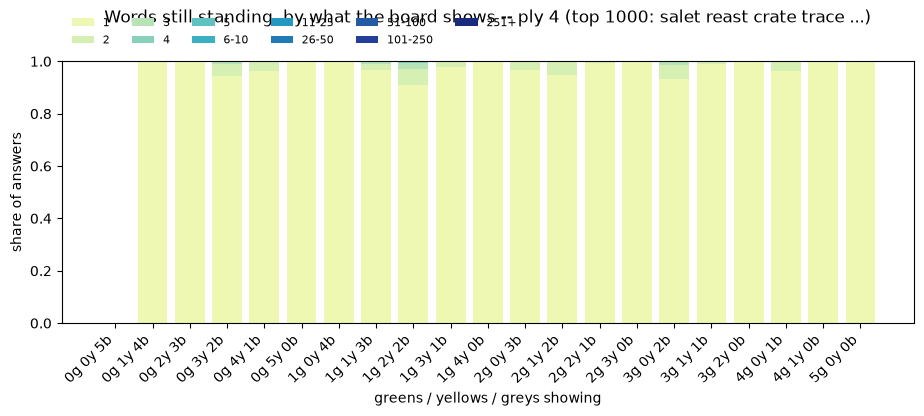

ply 5 (top 1000: salet reast crate trace ...): 2,351 positions over 9 compositions, 2,351 answer-positions
  words remaining, answers-weighted: mean 1.00, min 1, p25 1, median 1, p75 1, p90 1, max 1


n_positions  n_answers  mean  min  p25  median  p75  \
greens yellows grays                                                        
0      3       2                1          1   1.0    1    1       1    1   
       4       1                2          2   1.0    1    1       1    1   
1      2       2                1          1   1.0    1    1       1    1   
2      0       3               56         56   1.0    1    1       1    1   
       1       2               14         14   1.0    1    1       1    1   
       2       1                4          4   1.0    1    1       1    1   
3      0       2              635        635   1.0    1    1       1    1   
       1       1               35         35   1.0    1    1       1    1   
4      0       1             1603       1603   1.0    1    1       1    1   

                      p90  max  
greens yellows grays            
0      3       2        1    1  
       4       1        1    1  
1      2       2        1    1  
2      0       3        1    1  
       1       2        1    1  
       2       1        1    1  
3      0       2        1    1  
       1       1        1    1  
4      0       1        1    1

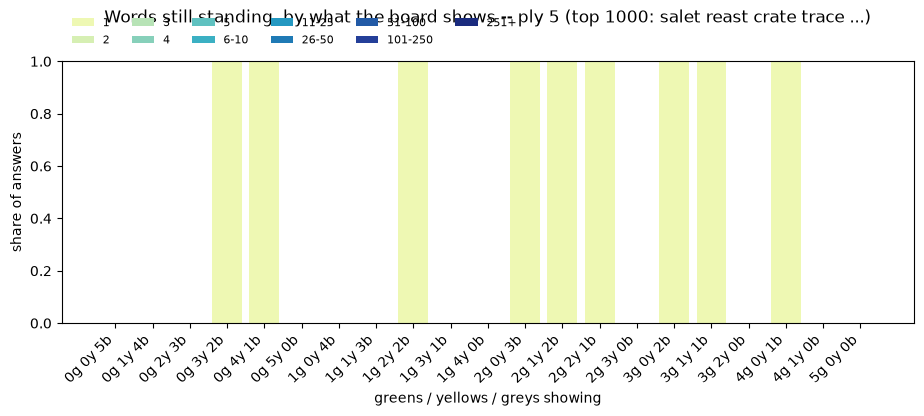

all plies (top 1000: salet reast crate trace ...): 2,385,882 positions over 21 compositions, 8,071,677 answer-positions
  words remaining, answers-weighted: mean 695.28, min 1, p25 2, median 27, p75 2,315, p90 2,315, max 2,315


n_positions  n_answers         mean  min   p25  median  \
greens yellows grays                                                           
0      0       5             3195    2626246  2074.907607    1  2315    2315   
       1       4            18215     696454   130.193064    1    88     129   
       2       3            67736     676805    46.475468    1    11      37   
       3       2           122856     372372    10.074662    1     2       5   
       4       1            80572     117726     2.301802    1     1       1   
       5       0            13782      14081     1.043463    1     1       1   
1      0       4            21700     325793    60.310317    1    25      57   
       1       3           144492     598322    15.604878    1     4       9   
       2       2           295972     544433     3.811913    1     1       2   
       3       1           193554     236998     1.523009    1     1       1   
       4       0            33596      33892     1.017526    1     1       1   
2      0       3           101250     256902     9.918701    1     2       5   
       1       2           291385     428006     2.488414    1     1       1   
       2       1           207475     236944     1.325638    1     1       1   
       3       0            34336      34416     1.004649    1     1       1   
3      0       2           237705     304192     1.880996    1     1       1   
       1       1           156681     173030     1.231994    1     1       1   
       2       0            29679      29685     1.000404    1     1       1   
4      0       1           319291     352970     1.205621    1     1       1   
       1       0             9952       9952     1.000000    1     1       1   
5      0       0             2458       2458     1.000000    1     1       1   

                       p75   p90   max  
greens yellows grays                    
0      0       5      2315  2315  2315  
       1       4       179   223   334  
       2       3        71   103   193  
       3       2        13    26    70  
       4       1         3     5    25  
       5       0         1     1     4  
1      0       4        89   117   185  
       1       3        23    37   108  
       2       2         5     9    38  
       3       1         2     3    12  
       4       0         1     1     3  
2      0       3        13    26    91  
       1       2         3     5    29  
       2       1         1     2     8  
       3       0         1     1     2  
3      0       2         2     3    27  
       1       1         1     2     7  
       2       0         1     1     2  
4      0       1         1     2     6  
       1       0         1     1     1  
5      0       0         1     1     1

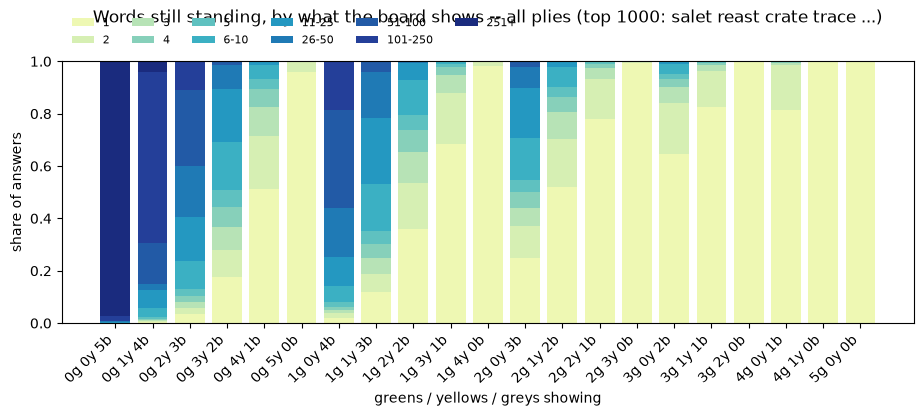

weighting check: answer-weighted mean >= position-weighted at all 21 compositions, equal at 2 of them
the boards where most is still standing (answers-weighted mean):


n_positions  n_answers         mean  min   p25  median  \
greens yellows grays                                                           
0      0       5             3195    2626246  2074.907607    1  2315    2315   
       1       4            18215     696454   130.193064    1    88     129   
1      0       4            21700     325793    60.310317    1    25      57   
0      2       3            67736     676805    46.475468    1    11      37   
1      1       3           144492     598322    15.604878    1     4       9   
0      3       2           122856     372372    10.074662    1     2       5   
2      0       3           101250     256902     9.918701    1     2       5   
1      2       2           295972     544433     3.811913    1     1       2   
2      1       2           291385     428006     2.488414    1     1       1   
0      4       1            80572     117726     2.301802    1     1       1   

                       p75   p90   max  
greens yellows grays                    
0      0       5      2315  2315  2315  
       1       4       179   223   334  
1      0       4        89   117   185  
0      2       3        71   103   193  
1      1       3        23    37   108  
0      3       2        13    26    70  
2      0       3        13    26    91  
1      2       2         5     9    38  
2      1       2         3     5    29  
0      4       1         3     5    25

In [13]:
DIST_WEIGHT = 'answers'   # <-- 'answers': a position of n contributes n; 'positions': once

QUANTILES      = [0.0, 0.25, 0.5, 0.75, 0.9, 1.0]
QUANTILE_NAMES = ['min', 'p25', 'median', 'p75', 'p90', 'max']

# An ORDINAL ramp over the option bins, deliberately NOT NEW_COLORS: the two charts
# stack different scales and must not read as one.
OPTION_COLORS = plt.get_cmap('YlGnBu')(np.linspace(0.12, 0.92, len(OPTION_LABELS)))


def weights_of(frame, weight=None):
    """The weight each position carries, per DIST_WEIGHT -- see the markdown above."""
    weight = DIST_WEIGHT if weight is None else weight
    if weight == 'answers':
        return frame['n_answers'].to_numpy(float)
    if weight == 'positions':
        return np.ones(len(frame))
    raise ValueError(f"DIST_WEIGHT must be 'answers' or 'positions', not {weight!r}")


def weighted_quantiles(values, weights, qs=QUANTILES):
    """`values`' q-quantiles under `weights`, by cumulative weight, NOT interpolated.

    The smallest value whose cumulative weight share reaches q. These are COUNTS of
    words, so an interpolated quantile would name a count that never occurred."""
    order = np.argsort(values, kind='stable')
    v = np.asarray(values)[order]
    cum = np.cumsum(np.asarray(weights, float)[order])
    return [int(v[np.searchsorted(cum, q * cum[-1], side='left')]) for q in qs]


def remaining_dist(frame, index, weight=None):
    """One row per `index` value: the distribution of n_answers sitting under it."""
    keys, rows = [], []
    for key, sub in frame.groupby(index, sort=True):
        n = sub['n_answers'].to_numpy()
        w = weights_of(sub, weight)
        rec = {'n_positions': len(sub), 'n_answers': int(n.sum()),
               'mean': (n * w).sum() / w.sum()}
        rec.update(zip(QUANTILE_NAMES, weighted_quantiles(n, w)))
        keys.append(key)
        rows.append(rec)
    idx = (pd.MultiIndex.from_tuples(keys, names=index) if isinstance(index, list)
           else pd.Index(keys, name=index))
    return pd.DataFrame(rows, index=idx)


def options_mix(frame, index, weight=None):
    """`index` x option bin, weighted per DIST_WEIGHT, every bin present."""
    weight = DIST_WEIGHT if weight is None else weight
    kw = (dict(values='n_answers', aggfunc='sum') if weight == 'answers'
          else dict(values='guess', aggfunc='size'))
    return (frame.pivot_table(index=index, columns='options', fill_value=0,
                              observed=False, **kw)
                 .reindex(columns=OPTION_LABELS, fill_value=0))


binned_board = board.assign(options=pd.cut(board['n_answers'], bins=OPTION_EDGES,
                                           labels=OPTION_LABELS, right=True))

_scopes = scope_frames(binned_board)
remaining_tables = {label: remaining_dist(f, BOARD_INDEX) for label, f in _scopes}
remaining_mixes  = {label: options_mix(f, BOARD_INDEX) for label, f in _scopes}

_rows = list(pd.concat(list(remaining_mixes.values())).index.unique().sort_values())
_board = lambda r: f'{r[0]}g {r[1]}y {r[2]}b'

for label, frame in _scopes:
    table = remaining_tables[label]
    n, w = frame['n_answers'].to_numpy(), weights_of(frame)
    quants = dict(zip(QUANTILE_NAMES, weighted_quantiles(n, w)))
    print(f'{label} ({LABEL}): {len(frame):,} positions over {len(table)} compositions, '
          f'{int(n.sum()):,} answer-positions')
    print(f'  words remaining, {DIST_WEIGHT}-weighted: mean {(n * w).sum() / w.sum():.2f}, '
          + ', '.join(f'{k} {v:,}' for k, v in quants.items()))
    display(table)
    mix_chart(remaining_mixes[label], _rows,
              f'Words still standing, by what the board shows -- {label} ({LABEL})',
              'greens / yellows / greys showing', f'share of {DIST_WEIGHT}', '{n}',
              fmt=_board, colors=OPTION_COLORS)

remaining_pooled = remaining_tables[_scopes[-1][0]]   # the last scope -- pooled by default

# Free check: for ANY set of positions the answer-weighted mean (sum n^2 / sum n)
# is at least the position-weighted one (sum n / count), by Cauchy-Schwarz, with
# equality exactly when every position holds the same number. Asserted per
# composition, so a weighting taken off the wrong column shows up as a violation
# rather than as a plausible-looking number.
_a = remaining_dist(binned_board, BOARD_INDEX, weight='answers')['mean']
_p = remaining_dist(binned_board, BOARD_INDEX, weight='positions')['mean']
_bad = _a.index[_a < _p - 1e-9]
if len(_bad):
    raise ValueError(f'answer-weighted mean below the position-weighted one at '
                     f'{list(_bad)}: the two weightings are crossed')
print(f'weighting check: answer-weighted mean >= position-weighted at all {len(_a)} '
      f'compositions, equal at {int((abs(_a - _p) < 1e-9).sum())} of them')

print(f'the boards where most is still standing ({DIST_WEIGHT}-weighted mean):')
display(remaining_pooled.sort_values('mean', ascending=False).head(10))


## The opener's reply: how often each colour combination comes up

The **first guess only**, and the one section here that reads no tree at all: it buckets the
answer list by `wordle.pattern(opener, answer)` directly, so it is a fact about the OPENER
WORD rather than about the strategy played after it. `TREE_OPENERS` still names the
openers, so the selection is the one every other cell uses.

`FIRST_KEY` picks what "colour combination" means, and the two are different tables:

- **`pattern`** (the default) — the literal five-tile reply, `bbgyb`. 238 of the 243 codes
  are attainable (4 greens + 1 yellow is impossible — the fifth letter is either in that
  square, hence green, or not in the word at all), and a code no selected opener can
  produce is dropped from the table and counted in the header rather than shown as a row
  of zeros.
- **`composition`** — greens / yellows / greys, the same cumulative reading the sections
  above use. After ONE guess the cumulative state is just the tiles, so this is exactly the
  tile counts, and 20 of the 21 compositions occur (`4g 1y 0b` is the impossible one).

**Every column is per (opener, answer) pair**, so an opener contributes its own answer list
and every selected opener carries equal weight:

| column | meaning |
| --- | --- |
| `n_openers` | selected openers that can produce this reply at all |
| `n_answers` | pooled (opener, answer) pairs giving it |
| `share` | that against every pair, i.e. `n_answers / (openers x answers)` |
| `mean` `min` `median` `p90` `max` | the spread of the PER-OPENER count across the selection — an opener that cannot produce the reply counts 0, which is what makes `min` meaningful |

The chart draws the top `TOP_N` rows: the bar is the mean per-opener count and the whisker
is `min` to `max` across the openers, so how COMMON a reply is and how much the choice of
opener moves it are read off together.

**Three checks run, and the third is the sharp one.** Each opener's counts must sum to the
answer list; the five 4-green-1-yellow codes must be empty for every opener; and the
composition table is diffed against the **tree-derived** ply-1 frame from the sections
above — which shares none of this code. They must agree at every composition except
`5g 0y 0b`, where the tree is SHORT by exactly the number of selected openers that are
themselves answer words: a tree line for an answer equal to the opener is one guess long
and records no pattern, so the all-green reply ends the game and is not a position. That
gap is why this section counts from the feedback function instead of from `pos`.


top 1000: salet reast crate trace ...: 1000 opener(s) x 2,315 answers = 2,315,000 replies, over 238 of 243 pattern(s) (5 never produced)
  distinct replies one opener produces: 96 .. 150 (mean 119.8)


,n_openers,n_answers,share,mean,min,median,p90,max
pattern,,,,,,,,
bbbbb,1000,293225,0.126663,293.225,161,286.0,374.0,506
bbbyb,1000,136119,0.058799,136.119,32,128.0,222.0,316
bbbby,1000,135775,0.058650,135.775,14,129.0,213.0,297
bbybb,1000,128879,0.055671,128.879,20,120.0,194.1,334
bybbb,1000,122716,0.053009,122.716,33,116.0,195.1,312
...,...,...,...,...,...,...,...,...
yggyy,6,6,0.000003,0.006,0,0.0,0.0,1
gygyy,6,6,0.000003,0.006,0,0.0,0.0,1
yggyg,5,5,0.000002,0.005,0,0.0,0.0,1


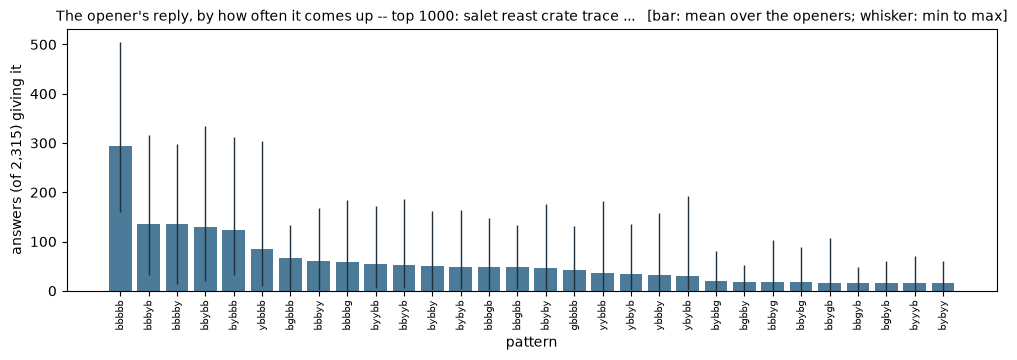

checks: replies sum to 2,315 per opener; the 5 impossible codes are empty; the composition totals match the ply-1 tree frame except all-green, where 265 of 1000 openers are answer words and win outright
the replies whose frequency the choice of opener moves most (max - min):


,n_openers,n_answers,share,mean,min,median,p90,max,spread
pattern,,,,,,,,,
bbbbb,1000,293225,0.126663,293.225,161,286.0,374.0,506,345
bbybb,1000,128879,0.055671,128.879,20,120.0,194.1,334,314
ybbbb,1000,85612,0.036981,85.612,9,68.0,159.1,304,295
bbbyb,1000,136119,0.058799,136.119,32,128.0,222.0,316,284
bbbby,1000,135775,0.058650,135.775,14,129.0,213.0,297,283
bybbb,1000,122716,0.053009,122.716,33,116.0,195.1,312,279
ybybb,1000,29263,0.012641,29.263,2,23.0,57.0,193,191
bbbbg,998,57589,0.024876,57.589,0,38.0,131.0,185,185
yybbb,999,36312,0.015686,36.312,0,26.0,78.0,182,182


In [14]:
FIRST_KEY = 'pattern'   # <-- 'pattern': the literal byg reply; 'composition': greens/yellows/greys
TOP_N     = 30          # <-- rows the chart draws, best first (None: every row)

# A single NEUTRAL series: deliberately not one of KIND_COLORS, which name
# categories -- a bar here is a frequency, not a kind.
FREQ_COLOR = '#4c7a99'

_CODES = np.arange(wordle.N_PATTERNS)
_TILES = np.array([wordle.decode(c) for c in _CODES])      # (N_PATTERNS, L), position 0 first
_GREENS, _YELLOWS = (_TILES == 2).sum(axis=1), (_TILES == 1).sum(axis=1)


def pat_of(code):
    """A base-3 code back to its `byg` string -- the inverse of tree_states.code_of."""
    return ''.join('byg'[t] for t in wordle.decode(code))


def reply_counts(openers, answers=None):
    """(len(openers), N_PATTERNS) int: answers giving each reply, per opener.

    Straight off `wordle.pattern_row`, so it needs no tree and no pattern matrix
    -- an opener with no tree on disk would work here, though TREE_OPENERS is
    what the notebook selects."""
    codes = wordle.to_codes(ANSWERS if answers is None else answers)
    out = np.zeros((len(openers), wordle.N_PATTERNS), int)
    for i, w in enumerate(openers):
        out[i] = np.bincount(wordle.pattern_row(w, codes), minlength=wordle.N_PATTERNS)
    return out


def key_groups(key):
    """(labels, group index over the 243 codes) for the requested FIRST_KEY."""
    if key == 'pattern':
        return [pat_of(c) for c in _CODES], _CODES.copy()
    if key == 'composition':
        pairs = sorted({(int(g), int(y)) for g, y in zip(_GREENS, _YELLOWS)})
        order = {p: i for i, p in enumerate(pairs)}
        labels = [f'{g}g {y}y {wordle.WORD_LEN - g - y}b' for g, y in pairs]
        groups = np.array([order[(int(g), int(y))] for g, y in zip(_GREENS, _YELLOWS)])
        return labels, groups
    raise ValueError(f"FIRST_KEY must be 'pattern' or 'composition', not {key!r}")


def reply_table(counts, key):
    """Per-key frequencies plus the spread of the per-opener count across `counts`."""
    labels, groups = key_groups(key)
    per_opener = np.stack([counts[:, groups == j].sum(axis=1) for j in range(len(labels))],
                          axis=1)                      # (n_openers, n_keys)
    totals = per_opener.sum(axis=0)
    frame = pd.DataFrame({
        key: labels,
        'n_openers': (per_opener > 0).sum(axis=0),
        'n_answers': totals,
        'share': totals / counts.sum(),
        'mean': per_opener.mean(axis=0),
        'min': per_opener.min(axis=0),
        'median': np.median(per_opener, axis=0),
        'p90': np.percentile(per_opener, 90, axis=0),
        'max': per_opener.max(axis=0),
    }).set_index(key)
    return frame, per_opener


def freq_chart(frame, title, xlabel, top_n=None, width=12, height=3.4):
    """Mean per-opener count per key, with a min..max whisker across the openers."""
    shown = frame if top_n is None else frame.head(top_n)
    x = np.arange(len(shown))
    fig, ax = plt.subplots(figsize=(width, height))
    ax.bar(x, shown['mean'], color=FREQ_COLOR)
    ax.vlines(x, shown['min'], shown['max'], color='#22303c', linewidth=1)
    ax.set_xticks(x)
    ax.set_xticklabels(shown.index, rotation=90 if len(shown) > 24 else 45,
                       ha='center' if len(shown) > 24 else 'right', fontsize=7)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(f'answers (of {len(ANSWERS):,}) giving it')
    ax.set_title(title + '   [bar: mean over the openers; whisker: min to max]', fontsize=10)
    plt.show()


REPLY_COUNTS = reply_counts(TREE_OPENERS)
first_replies, first_per_opener = reply_table(REPLY_COUNTS, FIRST_KEY)
first_replies = first_replies.sort_values('n_answers', ascending=False)

_seen = first_replies[first_replies['n_answers'] > 0]
print(f'{LABEL}: {len(TREE_OPENERS)} opener(s) x {len(ANSWERS):,} answers = '
      f'{REPLY_COUNTS.sum():,} replies, over {len(_seen)} of {len(first_replies)} '
      f'{FIRST_KEY}(s) ({len(first_replies) - len(_seen)} never produced)')
print(f'  distinct replies one opener produces: '
      f'{(REPLY_COUNTS > 0).sum(axis=1).min()} .. {(REPLY_COUNTS > 0).sum(axis=1).max()} '
      f'(mean {(REPLY_COUNTS > 0).sum(axis=1).mean():.1f})')
display(_seen)
freq_chart(_seen, f"The opener's reply, by how often it comes up -- {LABEL}",
           FIRST_KEY, TOP_N)

# --- checks ---------------------------------------------------------------
# 1. every answer lands in exactly one reply, per opener.
if not (REPLY_COUNTS.sum(axis=1) == len(ANSWERS)).all():
    raise ValueError("an opener's replies do not sum to the answer list: a lost bucket")

# 2. 4 greens + 1 yellow is impossible -- the fifth letter is in that square
#    (green) or absent (grey). 238 of 243 codes attainable, and these are the 5.
_impossible = _CODES[(_GREENS == 4) & (_YELLOWS == 1)]
if len(_impossible) != 5 or REPLY_COUNTS[:, _impossible].any():
    raise ValueError(f'{len(_impossible)} four-green-one-yellow codes, '
                     f'{int(REPLY_COUNTS[:, _impossible].sum())} answers in them: '
                     'the impossible patterns are not empty')

# 3. the sharp one: the composition table against the TREE-derived ply-1 frame,
#    which shares none of this code. They agree everywhere but all-green, where
#    the tree is short by one line per opener that is itself an answer word --
#    that answer's line is one guess long and records no pattern, so the win is
#    not a position. Under `ansall` the answer list IS the guess list, so every
#    opener is an answer word and the gap is the whole selection.
_comp, _ = reply_table(REPLY_COUNTS, 'composition')
_here = _comp['n_answers']
# .rename() maps a MultiIndex LEVEL at a time, so the label is built from the
# tuples directly -- one row per (greens, yellows, grays), spelled as above.
_by_comp = (board[board['depth'] == 1]
            .groupby(['greens', 'yellows', 'grays'])['n_answers'].sum())
_tree = pd.Series(_by_comp.to_numpy(),
                  index=[f'{gr}g {ye}y {gy}b' for gr, ye, gy in _by_comp.index]
                  ).reindex(_comp.index, fill_value=0)
_won = sum(1 for w in TREE_OPENERS if w in ANSWER_SET)
_expected = pd.Series(0, index=_comp.index)
_expected[f'{wordle.WORD_LEN}g 0y 0b'] = _won
if not (_here - _tree).equals(_expected):
    raise ValueError('the feedback-derived ply-1 compositions disagree with the trees: '
                     + str((_here - _tree - _expected).pipe(lambda s: s[s != 0]).to_dict()))
print(f'checks: replies sum to {len(ANSWERS):,} per opener; the 5 impossible codes are '
      f'empty; the composition totals match the ply-1 tree frame except all-green, '
      f'where {_won} of {len(TREE_OPENERS)} openers are answer words and win outright')

print(f'the replies whose frequency the choice of opener moves most (max - min):')
display(_seen.assign(spread=_seen['max'] - _seen['min'])
             .sort_values('spread', ascending=False).head(10))


## Which letter follows which: for each `alpha`, how the `beta`s rank

For a pair of letters `alpha` and `beta`, take every selected tree whose **opener contains
`alpha` and does not contain `beta`**, and look at what its **second guess** does. Split those
positions by what the opener said about `alpha`:

- **`alpha` present** — it came back green or yellow somewhere, so the answer holds it;
- **`alpha` absent** — every copy came back grey, so the answer holds none.

In each case, the cell is the share of the time the second guess **contains `beta`**, and the
`beta`s are ranked by it, per `alpha`. So a high cell reads "having learnt that `alpha` is in
(or out of) the word, the strategy reaches for `beta` next".

**The choices this makes, stated because they are choices:**

- **`alpha` present means present *at all***, since a letter can be green at one square and
  yellow or grey at another. `green or yellow anywhere` is exactly "the answer holds a copy"
  and `all grey` exactly "it holds none", so the two cases are complementary and exhaustive.
- **`beta` in the guess means at least one copy**, position ignored.
- **Every cell has its OWN denominator.** The trees a pair uses are those whose opener carries
  `alpha` and not `beta`, so moving `beta` moves the tree set, and two cells in a row are not
  drawn from the same games. `n_answers` per pair is carried for that reason.
- **Weighted by ANSWERS by default** — "the share of the time" being read as across games, so a
  position holding 340 answers counts 340 times one holding 1. `BETA_WEIGHT = 'positions'`
  counts each reachable position once instead; the two answer different questions and the
  section reports whichever is set.
- **Second guess only**, so this section ignores `SCOPES` — the question names the ply.

`alpha` has to appear in some selected opener, so this wants a large `TOP_K`: at `TOP_K = 1`
only the five letters of `salet` have a row at all.

top 1000: salet reast crate trace ...: 119,558 second-guess positions, weighted by answers; 20 letters appear in an opener (abcdefghilmnoprstuwy)

the 8 betas the second guess reaches for most often, per alpha:


,alpha present weight,alpha present,alpha absent weight,alpha absent
a,528885,"e 83.0%, t 69.4%, r 68.1%, l 66.4%, s 49.2%, c 46.0%, n 40.8%, i 29.7%",818292,"e 91.2%, t 73.0%, r 71.5%, s 67.0%, o 56.4%, i 52.8%, l 46.9%, n 45.4%"
b,10401,"a 74.0%, e 73.4%, r 46.3%, o 42.4%, t 40.2%, l 39.8%, i 33.5%, n 32.9%",79872,"e 93.2%, a 80.6%, t 77.2%, r 75.2%, s 64.8%, l 59.0%, n 47.5%, i 46.2%"
c,102976,"e 79.3%, a 76.8%, r 57.9%, l 44.8%, t 43.3%, o 40.7%, i 40.2%, n 38.4%",429410,"e 90.6%, t 79.9%, a 77.7%, r 72.0%, s 67.2%, l 59.6%, n 46.6%, i 44.4%"
d,58800,"e 73.3%, a 66.9%, r 62.5%, i 50.3%, l 46.8%, o 40.1%, n 35.9%, t 29.8%",309255,"e 90.3%, t 79.6%, a 78.4%, r 70.6%, s 70.0%, l 57.2%, c 48.0%, o 43.0%"
e,733722,"r 75.3%, a 73.1%, t 68.4%, s 58.5%, l 55.0%, i 36.8%, n 36.3%, c 30.5%",875005,"a 79.8%, t 74.7%, r 65.4%, s 62.8%, o 58.9%, l 57.9%, n 53.6%, c 49.0%"
f,1860,"e 52.7%, i 51.3%, a 49.8%, r 48.3%, l 46.4%, t 44.5%, s 26.6%, n 25.8%",18972,"e 93.7%, t 76.2%, r 75.2%, a 67.2%, l 59.5%, o 51.9%, s 47.6%, n 46.0%"
g,10787,"e 75.2%, r 53.8%, a 53.7%, l 47.5%, o 46.0%, n 44.6%, i 38.9%, s 33.4%",72540,"e 89.6%, a 78.5%, t 77.7%, r 73.8%, l 67.9%, s 62.5%, c 46.1%, o 44.6%"
h,26879,"e 71.4%, t 63.1%, r 60.8%, s 55.9%, a 55.8%, c 45.8%, o 36.1%, l 32.8%",137456,"e 89.3%, a 81.2%, r 72.3%, t 72.2%, l 58.3%, n 53.9%, s 52.1%, i 51.1%"
i,206312,"e 77.8%, t 64.0%, n 59.0%, a 57.8%, r 56.4%, s 52.9%, l 48.8%, d 36.0%",532092,"e 91.4%, a 82.5%, t 76.6%, r 76.2%, s 65.9%, l 63.0%, c 49.5%, o 45.3%"
l,244201,"e 82.4%, a 80.4%, s 52.3%, t 49.3%, i 39.9%, o 36.3%, r 33.7%, c 30.4%",628459,"e 89.2%, r 85.2%, t 80.4%, a 73.5%, s 64.3%, n 53.7%, o 46.9%, c 46.1%"


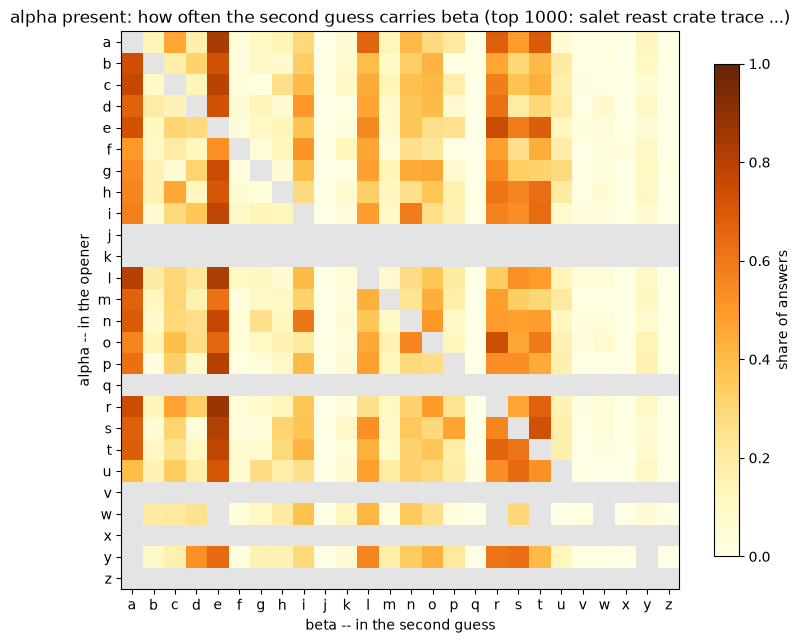

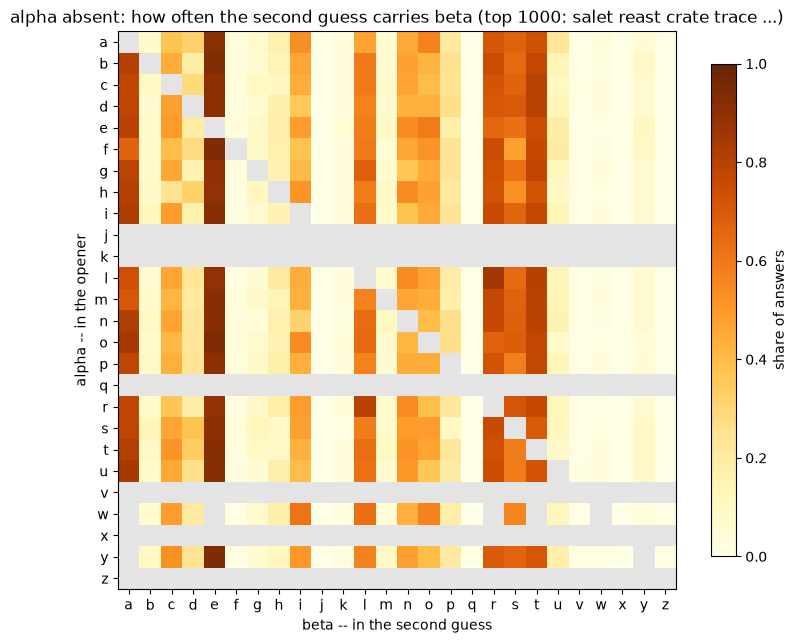

every beta for alpha = 'e', best first when 'e' is present:


,alpha present,alpha present weight,alpha absent,alpha absent weight
r,0.752885,327269.0,0.654080,390290.0
a,0.730536,350499.0,0.798119,417988.0
t,0.684362,430728.0,0.747239,513672.0
s,0.585234,378994.0,0.627834,451981.0
l,0.550080,465567.0,0.578923,555219.0
i,0.368436,535247.0,0.486907,638313.0
n,0.363040,532084.0,0.536455,634536.0
c,0.304702,574316.0,0.489644,684896.0
d,0.281961,599636.0,0.193901,715112.0
o,0.259936,563743.0,0.589392,672306.0


In [15]:
BETA_WEIGHT = 'answers'    # <-- 'answers' or 'positions': what "the share of the time" counts
RANK_ALPHA  = 'e'          # <-- the letter whose full beta ranking to print
TOP_BETAS   = 8            # <-- how many betas the per-alpha summary names

ALPHABET = string.ascii_lowercase
CASES = ('alpha present', 'alpha absent')

second = pos[pos['depth'] == 1]
_n = len(second)
opener_has = np.zeros((_n, len(ALPHABET)), bool)   # the opener carries this letter
in_answer  = np.zeros((_n, len(ALPHABET)), bool)   # ...and it came back green or yellow
guess_has  = np.zeros((_n, len(ALPHABET)), bool)   # the second guess carries this letter
for i, (opener, pat, guess) in enumerate(zip(second['opener'], second['patterns'],
                                             second['guess'])):
    for j, c in enumerate(opener):
        k = ord(c) - 97
        opener_has[i, k] = True
        in_answer[i, k] |= pat[j] != 'b'           # any non-grey copy: the answer holds it
    for c in guess:
        guess_has[i, ord(c) - 97] = True

_weights = (second['n_answers'].to_numpy().astype(float) if BETA_WEIGHT == 'answers'
            else np.ones(_n))


def beta_shares(present):
    """(share, weight) as alpha x beta frames, over the trees each PAIR admits.

    `present` picks the case: openers where alpha came back green or yellow
    somewhere, or where every copy came back grey. A pair's rows are those whose
    opener also LACKS beta, so each cell carries its own denominator."""
    share = np.full((len(ALPHABET),) * 2, np.nan)
    weight = np.zeros((len(ALPHABET),) * 2)
    for a in range(len(ALPHABET)):
        mask = opener_has[:, a] & (in_answer[:, a] if present else ~in_answer[:, a])
        if not mask.any():
            continue
        w = _weights[mask][:, None]
        lacks = ~opener_has[mask]                  # the opener does not carry beta
        weight[a] = (w * lacks).sum(axis=0)
        hit = (w * (lacks & guess_has[mask])).sum(axis=0)
        share[a] = np.divide(hit, weight[a], out=np.full(len(ALPHABET), np.nan),
                             where=weight[a] > 0)
    frame = lambda m: pd.DataFrame(m, index=list(ALPHABET), columns=list(ALPHABET))
    return frame(share), frame(weight)


beta_share, beta_weight = {}, {}
for case in CASES:
    beta_share[case], beta_weight[case] = beta_shares(case == CASES[0])

_seen = sorted({c for o in second['opener'].unique() for c in o})
print(f'{LABEL}: {_n:,} second-guess positions, weighted by {BETA_WEIGHT}; '
      f'{len(_seen)} letters appear in an opener ({"".join(_seen)})')


def top_betas(row, n=None):
    """The n best betas for one alpha, as 'b 87.2%, c 71.4%, ...'."""
    best = row.dropna().sort_values(ascending=False).head(n or TOP_BETAS)
    return ', '.join(f'{b} {v:.1%}' for b, v in best.items())


# The pair weights vary with beta, so the row's is its largest -- the betas no
# selected opener carries, where nothing is excluded and the whole case is in play.
summary = pd.DataFrame({
    f'{CASES[0]} weight': beta_weight[CASES[0]].max(axis=1).round().astype(int),
    CASES[0]: [top_betas(beta_share[CASES[0]].loc[a]) for a in ALPHABET],
    f'{CASES[1]} weight': beta_weight[CASES[1]].max(axis=1).round().astype(int),
    CASES[1]: [top_betas(beta_share[CASES[1]].loc[a]) for a in ALPHABET],
}, index=list(ALPHABET))
print(f'\nthe {TOP_BETAS} betas the second guess reaches for most often, per alpha:')
with pd.option_context('display.max_colwidth', 200):
    display(summary[summary[f'{CASES[0]} weight'] + summary[f'{CASES[1]} weight'] > 0])

_cmap = plt.get_cmap('YlOrBr').copy()
_cmap.set_bad('#e4e4e4')     # a pair with no trees is GREY, not the 0 of the ramp
for case in CASES:
    fig, ax = plt.subplots(figsize=(9, 8))
    im = ax.imshow(np.ma.masked_invalid(beta_share[case]), cmap=_cmap, vmin=0, vmax=1)
    ax.set_xticks(range(len(ALPHABET)), list(ALPHABET))
    ax.set_yticks(range(len(ALPHABET)), list(ALPHABET))
    ax.set_xlabel('beta -- in the second guess'); ax.set_ylabel('alpha -- in the opener')
    ax.set_title(f'{case}: how often the second guess carries beta ({LABEL})')
    fig.colorbar(im, ax=ax, shrink=0.8, label=f'share of {BETA_WEIGHT}')
    plt.show()

if RANK_ALPHA:
    ranked = pd.DataFrame({
        f'{case}{suffix}': col
        for case in CASES
        for suffix, col in (('', beta_share[case].loc[RANK_ALPHA]),
                            (' weight', beta_weight[case].loc[RANK_ALPHA]))
    }).dropna(subset=[CASES[0], CASES[1]], how='all')
    print(f'every beta for alpha = {RANK_ALPHA!r}, best first when {RANK_ALPHA!r} is present:')
    display(ranked.sort_values(CASES[0], ascending=False))

## Look up one position

Filter by the history you have in hand — it is just a prefix of the `guesses`/`patterns`
columns. Each selected tree that reaches that history gets its own block: the position
itself, then every outcome its optimal next guess can produce from there. An empty
`HISTORY`/`FEEDBACK` is the root, so it prints one block per tree.

In [16]:
HISTORY  = 'salet'     # <-- guesses so far, space separated ('' for the root)
FEEDBACK = 'bbbyb'     # <-- their feedback, space separated `byg` strings ('' for the root)

hits = pos[(pos['guesses'] == HISTORY) & (pos['patterns'] == FEEDBACK)]
if hits.empty:
    print(f'no position with guesses {HISTORY!r} and patterns {FEEDBACK!r} in any of '
          f'{len(TREE_OPENERS)} tree(s) ({LABEL}) -- unreachable under these strategies, '
          f'or a typo')
for _, r in hits.iterrows():
    print(f'{r["opener"]}: {r["n_answers"]:,} answers left; '
          f'optimal next guess: {r["guess"]!r}')
    display(hits[hits['opener'] == r['opener']].reset_index(drop=True))
    kids = pos[(pos['opener'] == r['opener'])
               & (pos['guesses'] == (HISTORY + ' ' + r['guess']).strip())]
    print(f'{len(kids)} outcome(s) of {r["guess"]!r} here:')
    display(kids.reset_index(drop=True))

salet: 165 answers left; optimal next guess: 'drone'


,opener,depth,guesses,patterns,n_answers,guess,new_letters,guess_kind,solved,sample
0,salet,1,salet,bbbyb,165,drone,4,possible answer,False,beech beefy begin begun


57 outcome(s) of 'drone' here:


,opener,depth,guesses,patterns,n_answers,guess,new_letters,guess_kind,solved,sample
0,salet,2,salet drone,bbbyb bbbyg,12,finch,4,ruled out,False,binge fence genie hence
1,salet,2,salet drone,bbbyb bybby,12,femur,3,possible answer,False,berry every femur ferry
2,salet,2,salet drone,bbbyb bybbg,10,merge,2,possible answer,False,curve eerie fibre merge
3,salet,2,salet drone,bbbyb bbbbg,9,piece,3,possible answer,False,chime femme fugue imbue
4,salet,2,salet drone,bbbyb bgbbg,9,campi,4,ruled out,False,bribe creme crepe crime
5,salet,2,salet drone,bbbyb bbbyy,8,begin,3,possible answer,False,begin begun bench enemy
6,salet,2,salet drone,bbbyb ybbbg,8,bijou,4,ruled out,False,budge chide fudge guide
7,salet,2,salet drone,bbbyb bbbby,6,beech,3,possible answer,False,beech beefy check equip
8,salet,2,salet drone,bbbyb byybg,6,forge,2,possible answer,False,force forge gorge ombre
9,salet,2,salet drone,bbbyb bggbg,6,probe,2,possible answer,False,broke froze grope grove


## Cross-check the counts

`n_answers` is read off the tree's structure (lines sharing a prefix). This re-derives it
from scratch for a random sample of positions — filtering the 2315 answers by replaying
each guess/feedback pair through `wordle.pattern` — so a misparse shows up as a mismatch
rather than as a plausible-looking wrong number. Same spirit as `tools/checktrees.py`. The
same filter re-derives `guess_kind`'s first case for free: the guess could win here exactly
when it is one of the survivors. The sample is drawn across every selected tree at once,
since a history already names the tree it belongs to.

The `consistent non-answer` / `ruled out` half of `guess_kind` is checked in `positions()`
itself, at *every* node rather than a sample: being one of the node's answers has to agree
with (reproduces every clue) and (is an answer word), and the function raises if it does not.

In [17]:
N_CHECK = 200      # <-- how many random positions to re-derive

def answers_after(guesses, patterns):
    """The answers consistent with a history, from the feedback function alone."""
    alive = list(ANSWERS)
    for g, p in zip(guesses, patterns):
        want = tree_states.code_of(p)
        alive = [a for a in alive if wordle.pattern(g, a) == want]
    return alive

rng = np.random.default_rng(0)                       # reproducible sample
idx = rng.choice(len(pos), size=min(N_CHECK, len(pos)), replace=False)
bad = []
for i in idx:
    r = pos.iloc[int(i)]
    alive = answers_after(r['guesses'].split(), r['patterns'].split())
    if len(alive) != r['n_answers']:
        bad.append((r, f'{r["n_answers"]} answers on the tree, {len(alive)} by filtering'))
    # ...and the same filter re-derives the FIRST kind: the guess could win here
    # exactly when it survives as one of the answers.
    elif (r['guess'] in alive) != (r['guess_kind'] == KIND_ANSWER):
        bad.append((r, f'kind {r["guess_kind"]!r} but the guess is '
                       f'{"" if r["guess"] in alive else "not "}one of the survivors'))

print(f'checked {len(idx)} positions over {pos.iloc[idx]["opener"].nunique()} tree(s) '
      f'({LABEL}): ' + ('all counts and kinds agree' if not bad
                        else f'{len(bad)} MISMATCH(ES)'))
for r, why in bad[:10]:
    print(f'  {r["opener"]}: {r["guesses"]} | {r["patterns"]} -> {r["guess"]}: {why}')

checked 200 positions over 186 tree(s) (top 1000: salet reast crate trace ...): all counts and kinds agree
